# Calculate Difference of Treated and Untreated Fitness Scores

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
# You probably want to change these paths to your computer's
main_dir = Path("/Users/isaiahhazelwood/Documents/rotations-2024/fraser-lab/DMS-data/")
raw_data_dir = main_dir / "raw-data/"
difference_dir = main_dir / "diff-scores/"
difference_tail_dir = main_dir / "diff-tail-scores/"

def load_raw_data(filename, keep_cols, header=0, directory=raw_data_dir, sep=","):
    """
    Load a given set of columns from a csv file as string lists.
    filename: file name within the raw-data directory
    keep_cols: 0-indexed list of columns to record
    header: number of header lines to skip
    """
    loaded = [[] for _ in keep_cols] # List of data points in that column
    with open(directory / filename, "r") as f_raw:
        for line_num, line in enumerate(f_raw):
            if line_num < header: # Skip lines in header
                continue
            cols = line.rstrip("\n").split(sep)
            for data_i, col_i in enumerate(keep_cols):
                loaded[data_i].append(cols[col_i])
    return loaded

SINGLE_AA = ['C', 'D', 'S', 'Q', 'K', 'I', 'P', 'T', 'F', 'N', 'G', 'H', 'L',
             'R', 'W', 'A', 'V', 'E', 'Y', 'M', '*']
aa3to1 = {'CYS': 'C', 'ASP': 'D', 'SER': 'S', 'GLN': 'Q', 'LYS': 'K',
          'ILE': 'I', 'PRO': 'P', 'THR': 'T', 'PHE': 'F', 'ASN': 'N', 
          'GLY': 'G', 'HIS': 'H', 'LEU': 'L', 'ARG': 'R', 'TRP': 'W', 
          'ALA': 'A', 'VAL': 'V', 'GLU': 'E', 'TYR': 'Y', 'MET': 'M', 'TER': '*'}

def clean_data(prot, ligand, wt, pos, mut, score):
    """
    Clean the given data to remove rows with missing and NA values.
    wt: single letter wild-type amino acid
    position: position in amino acid (as string)
    mut: single letter mutant amino acid
    score: arbitrary score (as string)
    """
    assert len(prot) == len(ligand)
    assert len(prot) == len(wt)
    assert len(prot) == len(pos)
    assert len(prot) == len(mut)
    assert len(prot) == len(score)

    cleaned_prot = []
    cleaned_ligand = []
    cleaned_wt = []
    cleaned_pos = []
    cleaned_mut = []
    cleaned_score = []
    for i in range(len(wt)):
        if ((prot[i] != "" and ligand[i] != "" and wt[i] != "" and pos != "" and mut != "" and score != "")
            and wt[i] in SINGLE_AA and pos[i].isdecimal() and mut[i] in SINGLE_AA):
            cleaned_prot.append(prot[i])
            cleaned_ligand.append(ligand[i])
            cleaned_wt.append(wt[i])
            cleaned_pos.append(pos[i])
            cleaned_mut.append(mut[i])
            cleaned_score.append(str(float(score[i])))
    return (cleaned_prot, cleaned_ligand, cleaned_wt, cleaned_pos, cleaned_mut, cleaned_score)

def write_formatted_data(filename, data, header, directory=difference_dir):
    """
    Write the mutation data to a file in standardized format.
    filename: file name within raw-scores directory
    data: list of columns to write to file
    header: list of column names to include as single-line header
    """
    assert len(header) == len(data)
    assert all(len(col) == len(data[0]) for col in data)
    with open(directory / filename, "w") as f_scores:
        f_scores.write(",".join(header) + "\n")
        for i in range(len(data[0])):
            f_scores.write(",".join(col[i] for col in data) + "\n")

## EGFR Hayes 2024

In [3]:
# Load control data from the Chakraborty 2019 EGFR DMS paper
with open(raw_data_dir / "EGFR-Chakraborty-2019.html", 'r') as f_chakraborty_2019:
    raw_chakraborty_2019 = f_chakraborty_2019.readlines()
chakraborty_records = raw_chakraborty_2019[0].rstrip("\n").split(",")
chakraborty_control = {}
for record in chakraborty_records:
    fields = record.split("<\\/br>")
    snv = fields[0].split()[1]
    wt = snv[0]
    pos = snv[1:-1]
    mut = snv[-1]
    fc = float(fields[1].split()[1])
    chakraborty_control[(wt, pos, mut)] = np.log2(fc + 0.0001)

# Load Hayes 2024 EGFR scores
egfr_hayes_data = load_raw_data("EGFR-Hayes-2024-all.csv", (0, 2), header=1)
hayes_erl_200nM = {}
for i in range(len(egfr_hayes_data[0])):
    wt = egfr_hayes_data[0][i][:1]
    pos = egfr_hayes_data[0][i][1:-1]
    mut = egfr_hayes_data[0][i][-1:]
    hayes_erl_200nM[(wt, pos, mut)] = float(egfr_hayes_data[1][i])

In [4]:
# Calculate mean and std of both datasets
chakraborty_control_mean = np.mean(list(chakraborty_control.values()))
chakraborty_control_std = np.std(list(chakraborty_control.values()))
print(f"Control mean, std: {chakraborty_control_mean}, {chakraborty_control_std}")
print(f"Treated mean, std: {np.mean(list(hayes_erl_200nM.values()))}, {np.std(list(hayes_erl_200nM.values()))}")

# Normalize control distribution to standard normal, like Hayes dataset
# This is NOT normalizing by the wild type
for key in chakraborty_control:
    chakraborty_control[key] = (chakraborty_control[key] - chakraborty_control_mean) / chakraborty_control_std

Control mean, std: 0.08818172850415762, 0.9667257013433195
Treated mean, std: -0.004857544303709164, 1.011234543723557


Control minor mutation mean, std: 0.0029556708409717723, 0.41663119592974424
Treated mean, std: 0.06116944522465748, 0.516789845777151


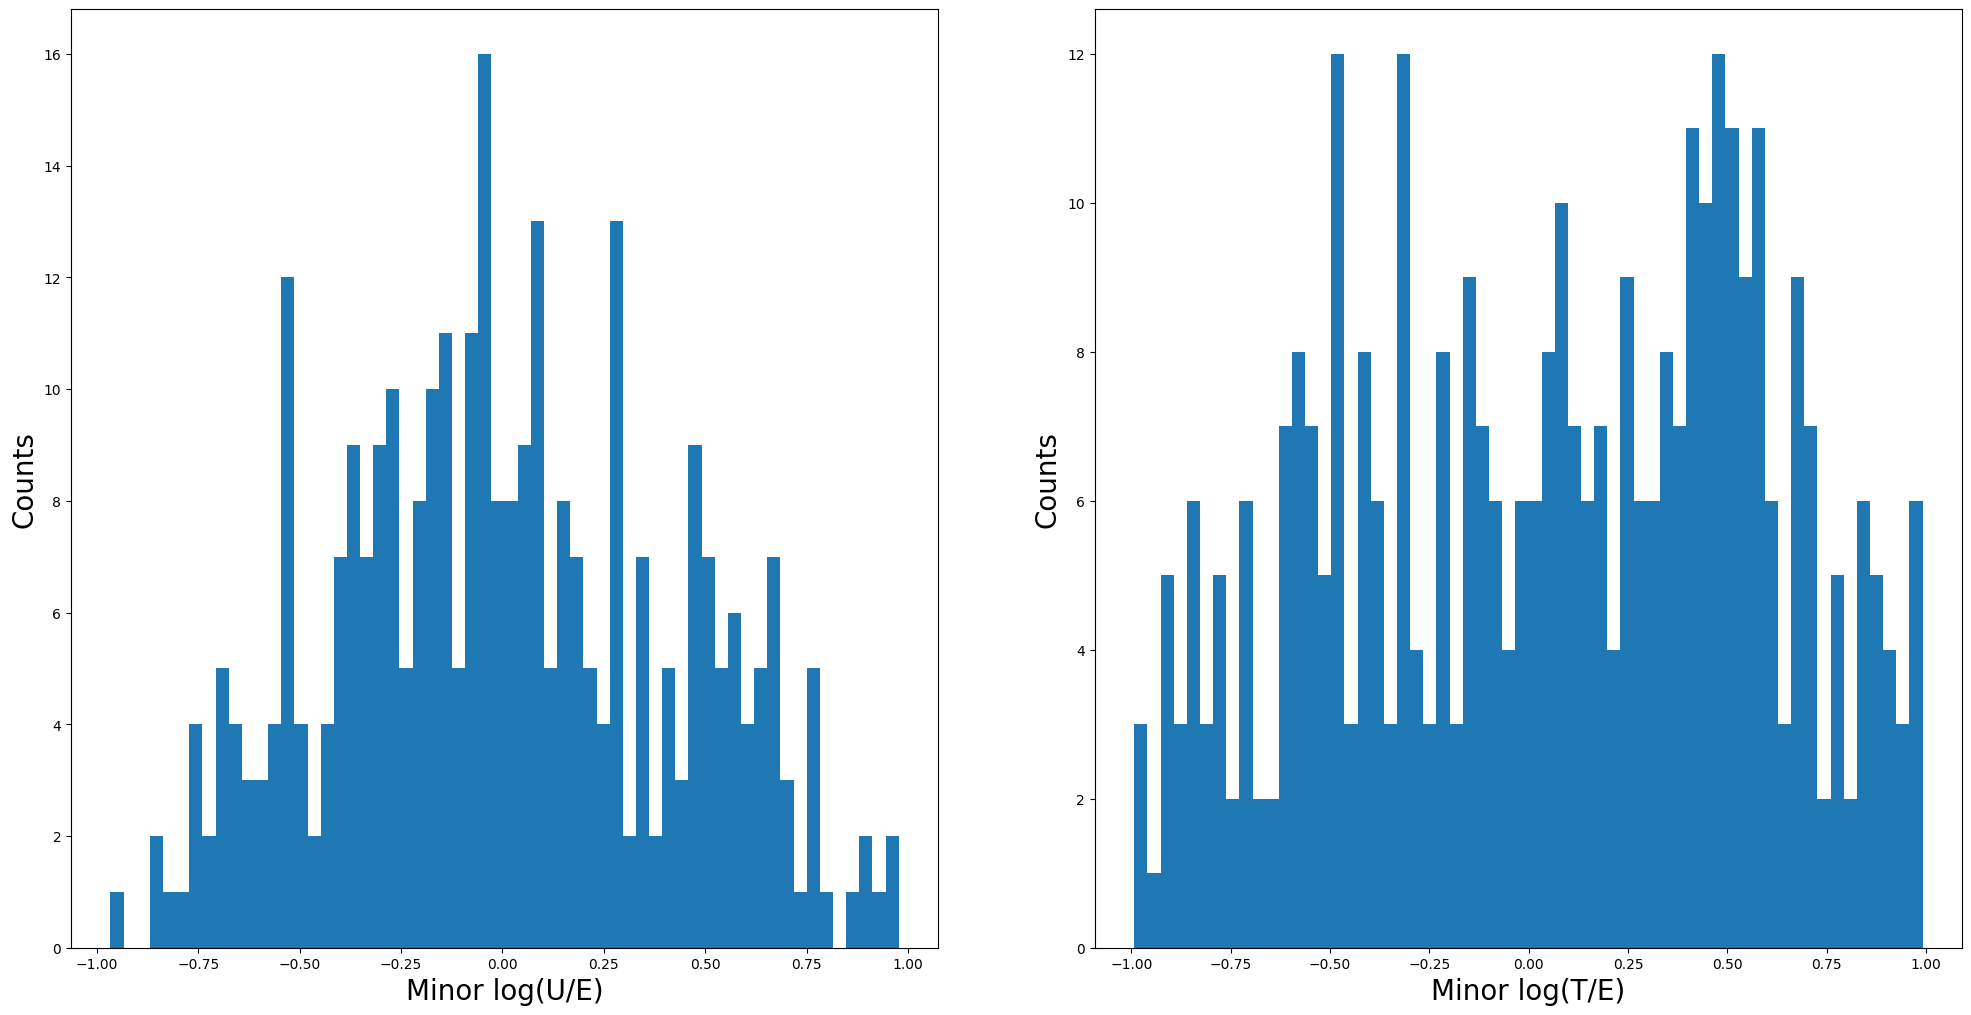

In [5]:
# Plot the score distribution of minor mutations (choosing a reasonable limit to avoid outliers)
minor_aa = ('L', 'I', 'V')
chakraborty_control_minor = {key: chakraborty_control[key] for key in chakraborty_control 
                             if key[0] in minor_aa and key[2] in minor_aa and abs(chakraborty_control[key]) <= 1}
hayes_erl_200nM_minor = {key: hayes_erl_200nM[key] for key in hayes_erl_200nM 
                         if key[0] in minor_aa and key[2] in minor_aa and abs(hayes_erl_200nM[key]) <= 1}

fig, axs = plt.subplots(1, 2)
axs[0].hist(list(chakraborty_control_minor.values()), bins=60)
axs[0].set_xlabel("Minor log(U/E)", size=20)
axs[0].set_ylabel("Counts", size=20)
axs[1].hist(list(hayes_erl_200nM_minor.values()), bins=60)
axs[1].set_xlabel("Minor log(T/E)", size=20)
axs[1].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

chakraborty_control_minor_mean = np.mean(list(chakraborty_control_minor.values()))
hayes_erl_200nM_minor_mean = np.mean(list(hayes_erl_200nM_minor.values()))
print(f"Control minor mutation mean, std: {chakraborty_control_minor_mean}, {np.std(list(chakraborty_control_minor.values()))}")
print(f"Treated mean, std: {hayes_erl_200nM_minor_mean}, {np.std(list(hayes_erl_200nM_minor.values()))}")

In [6]:
# Shift control and treatment distributions by the mean of the minor mutation distributions,
# to normalize for wild type
for key in chakraborty_control:
    chakraborty_control[key] = chakraborty_control[key] - chakraborty_control_minor_mean
for key in hayes_erl_200nM:
    hayes_erl_200nM[key] = hayes_erl_200nM[key] - hayes_erl_200nM_minor_mean

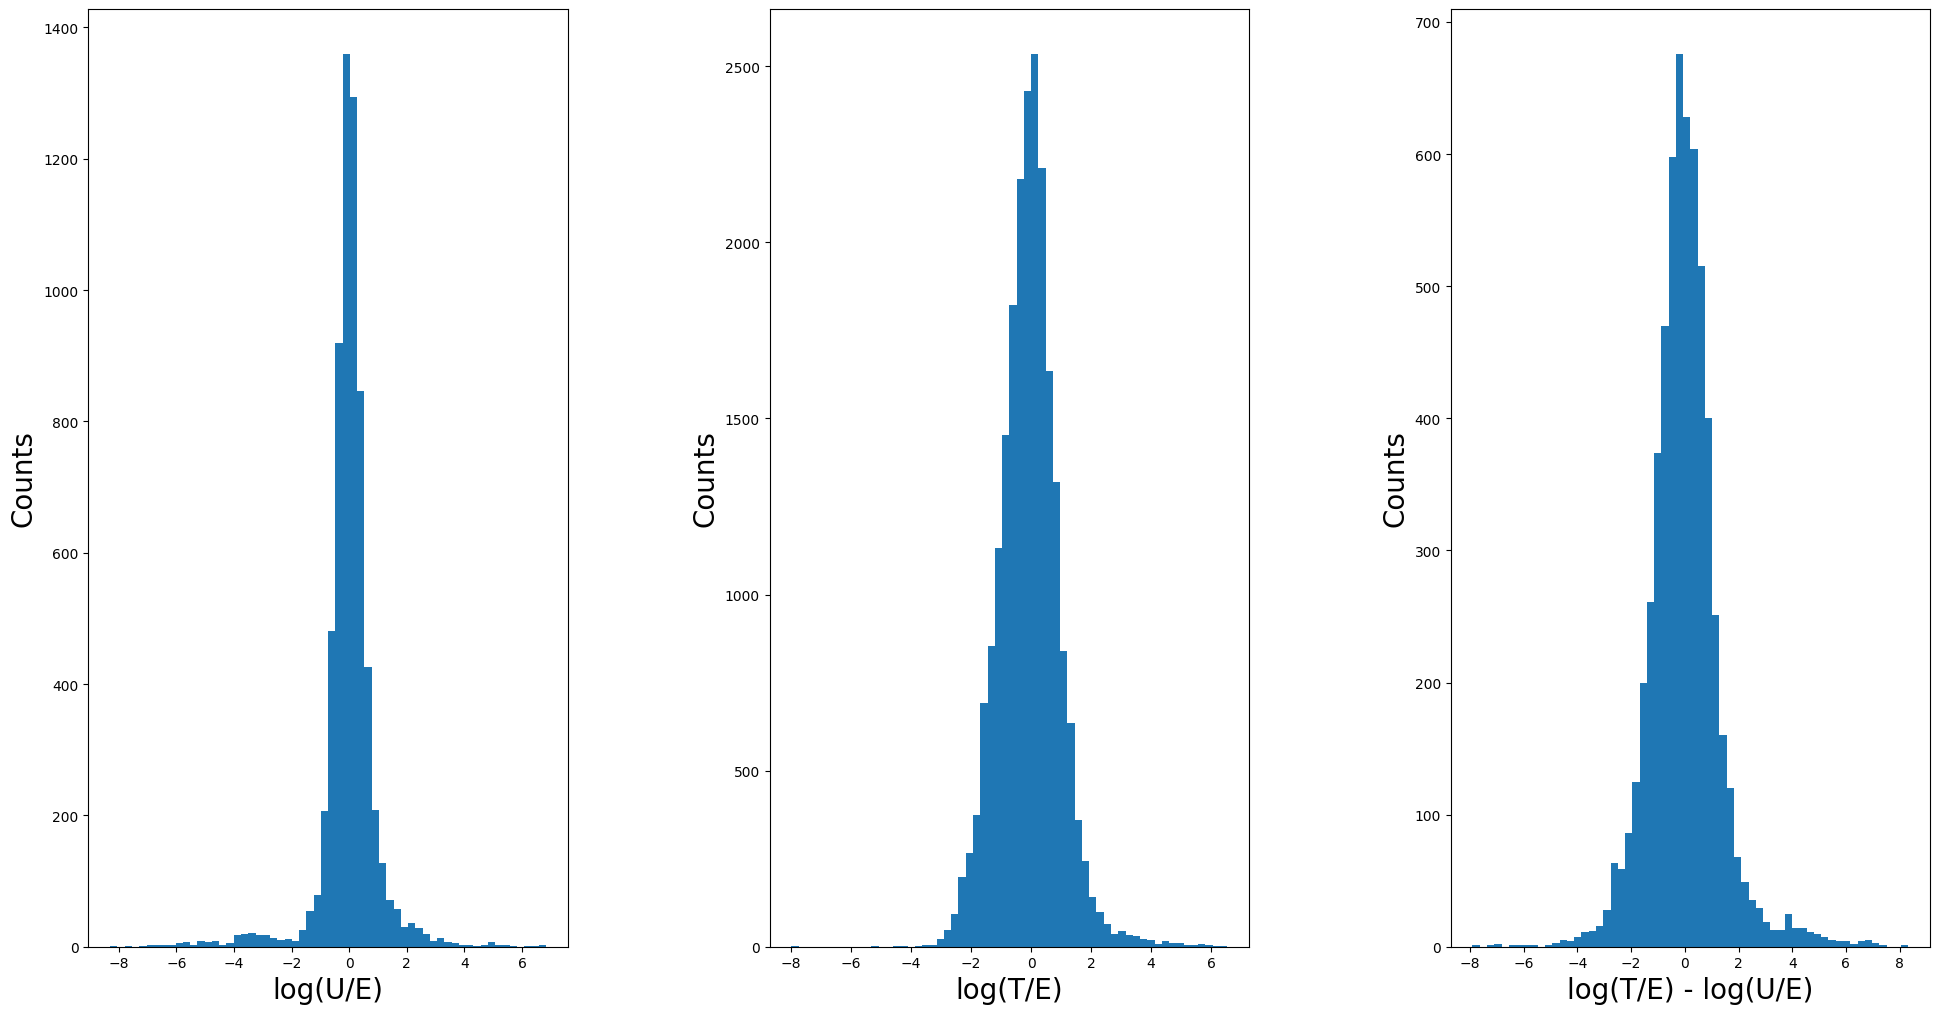

In [7]:
# Calculate the difference of treated and untreated scores
# Plot score distribution for each dataset and their difference
lfc_diff = {}
for key in hayes_erl_200nM:
    if key in chakraborty_control:
        lfc_diff[key] = hayes_erl_200nM[key] - chakraborty_control[key]

fig, axs = plt.subplots(1, 3)
datasets = [chakraborty_control, hayes_erl_200nM, lfc_diff]
for i in range(len(datasets)):
    axs[i].hist(list(datasets[i].values()), bins=60)
    if i == 0:
        axs[i].set_xlabel("log(U/E)", size=20)
    elif i == 1:
        axs[i].set_xlabel("log(T/E)", size=20)
    elif i == 2:
        axs[i].set_xlabel("log(T/E) - log(U/E)", size=20)
    axs[i].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

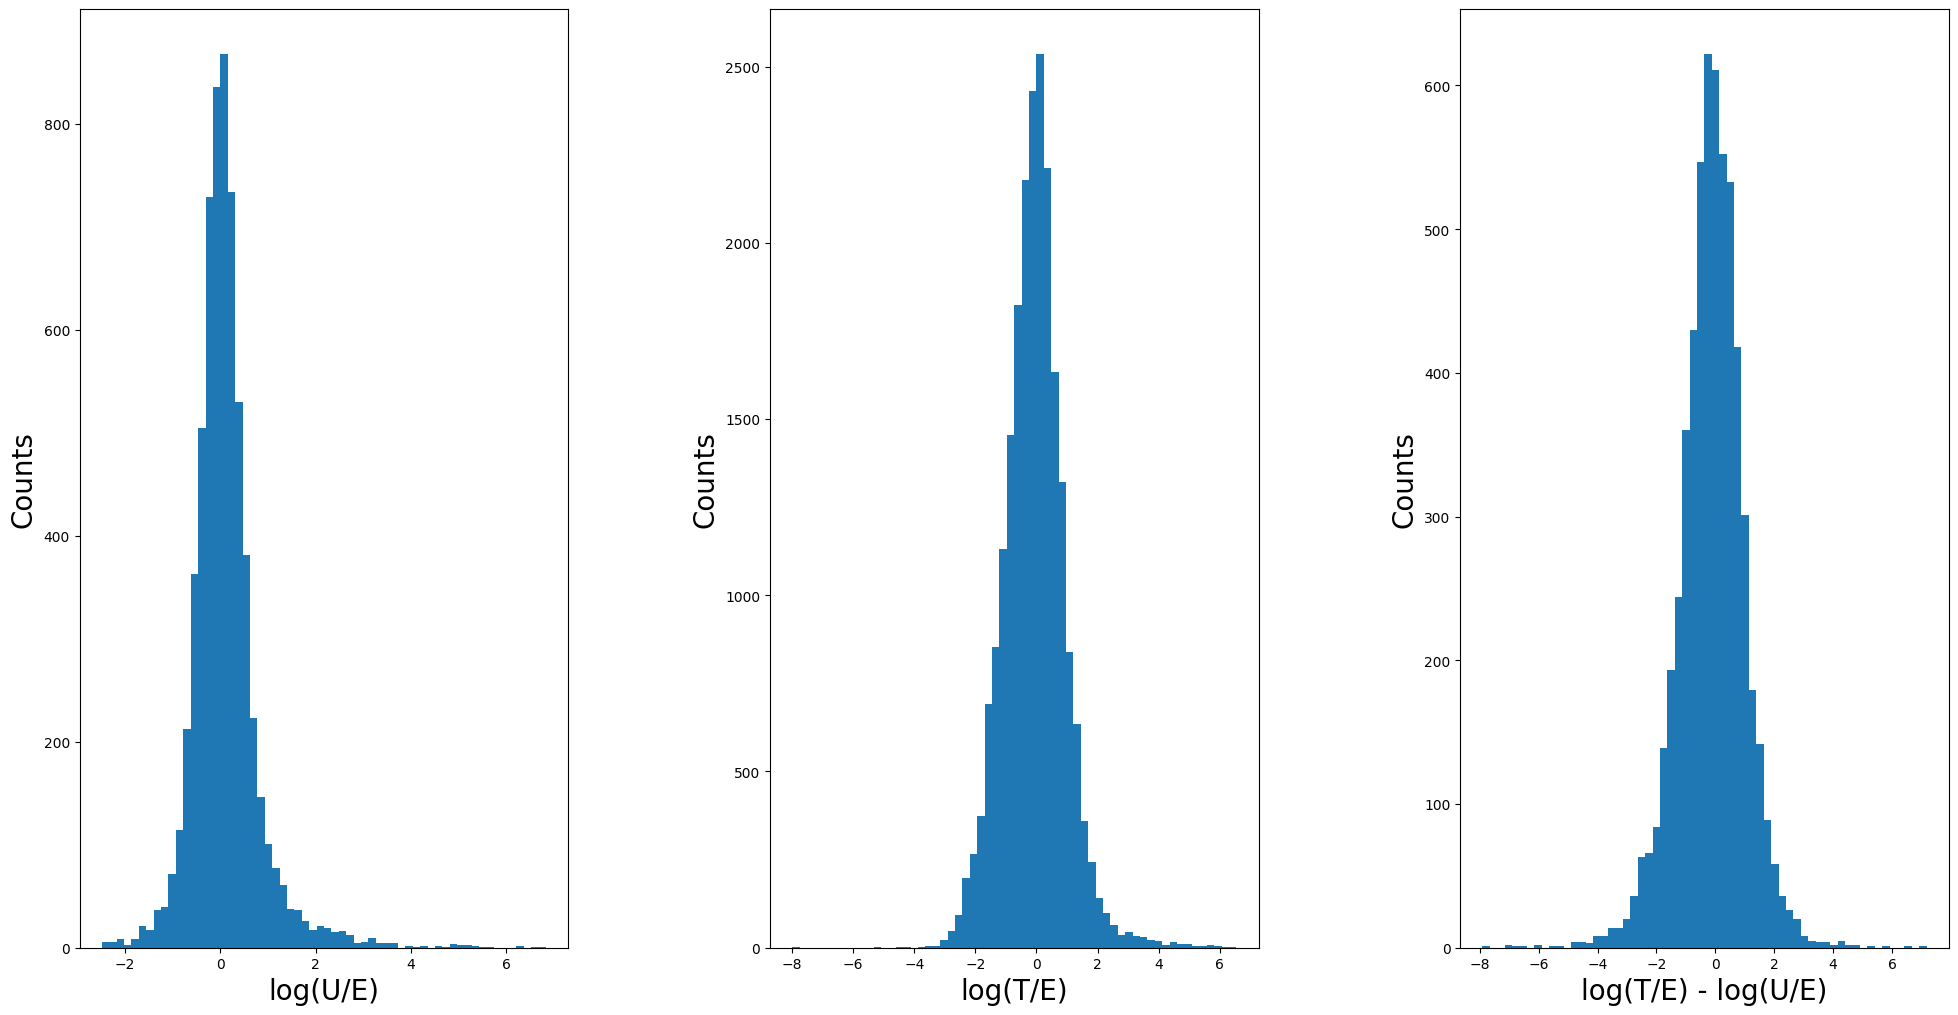

In [8]:
# Stop codons are already excluded
# Remove the second small LoF mode in the untreated scores below -2.5
chakraborty_control = {key: chakraborty_control[key] for key in chakraborty_control if chakraborty_control[key] >= -2.5}
# Recalculate difference scores and plot the new distributions
lfc_diff = {}
for key in hayes_erl_200nM:
    if key in chakraborty_control:
        lfc_diff[key] = hayes_erl_200nM[key] - chakraborty_control[key]

fig, axs = plt.subplots(1, 3)
datasets = [chakraborty_control, hayes_erl_200nM, lfc_diff]
for i in range(len(datasets)):
    axs[i].hist(list(datasets[i].values()), bins=60)
    if i == 0:
        axs[i].set_xlabel("log(U/E)", size=20)
    elif i == 1:
        axs[i].set_xlabel("log(T/E)", size=20)
    elif i == 2:
        axs[i].set_xlabel("log(T/E) - log(U/E)", size=20)
    axs[i].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [9]:
# Save difference scores to output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

for wt, pos, mut in lfc_diff:
    prot_col.append("EGFR")
    ligand_col.append("Erl_200nM")
    wt_col.append(wt)
    pos_col.append(pos)
    mut_col.append(mut)
    score_col.append(lfc_diff[(wt, pos, mut)])

write_formatted_data("EGFR_Hayes_2024.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"))

In [66]:
# Save the tails of the difference scores to an additional output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

lfc_diff_mean = np.mean(list(lfc_diff.values()))
lfc_diff_std = np.std(list(lfc_diff.values()))
print(f"Score difference mean, std: {lfc_diff_mean}, {lfc_diff_std}")

for wt, pos, mut in lfc_diff:
    if np.abs(lfc_diff[(wt, pos, mut)] - lfc_diff_mean) > lfc_diff_std:
        prot_col.append("EGFR")
        ligand_col.append("Erl_200nM")
        wt_col.append(wt)
        pos_col.append(pos)
        mut_col.append(mut)
        score_col.append(lfc_diff[(wt, pos, mut)])

write_formatted_data("EGFR_Hayes_2024_tail.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"),
                     directory=difference_tail_dir)

Score difference mean, std: -0.12409646144869141, 1.1326696428756662


## EGFR Kim 2024

In [63]:
# Load pre-normalized data from Kim et al paper
egfr_kim_data = load_raw_data("EGFR-Kim-2024.csv", (5, 8, 10, 12), header=2)
aa_from = []
position = []
aa_to = []

afa_scores = {}
osi_scores = {}
osi_T970M_scores = {}
for i in range(len(egfr_kim_data[0])):
    wt = egfr_kim_data[0][i][:1]
    pos = egfr_kim_data[0][i][1:-1]
    mut = egfr_kim_data[0][i][-1:]
    if egfr_kim_data[1][i] != "" and egfr_kim_data[1][i] != "N/A":
        afa_scores[(wt, pos, mut)] = float(egfr_kim_data[1][i])
    if egfr_kim_data[2][i] != "" and egfr_kim_data[2][i] != "N/A":
        osi_scores[(wt, pos, mut)] = float(egfr_kim_data[2][i])
    if egfr_kim_data[3][i] != "" and egfr_kim_data[3][i] != "N/A":
        osi_T970M_scores[(wt, pos, mut)] = float(egfr_kim_data[3][i])

Treatment 0 syn std, mean: 0.06939879414068442, 0.789023694989961
Treatment 1 syn std, mean: 0.08394031452851712, 0.784379866148128
Treatment 2 syn std, mean: 0.03164611202362205, 0.7777599793183807


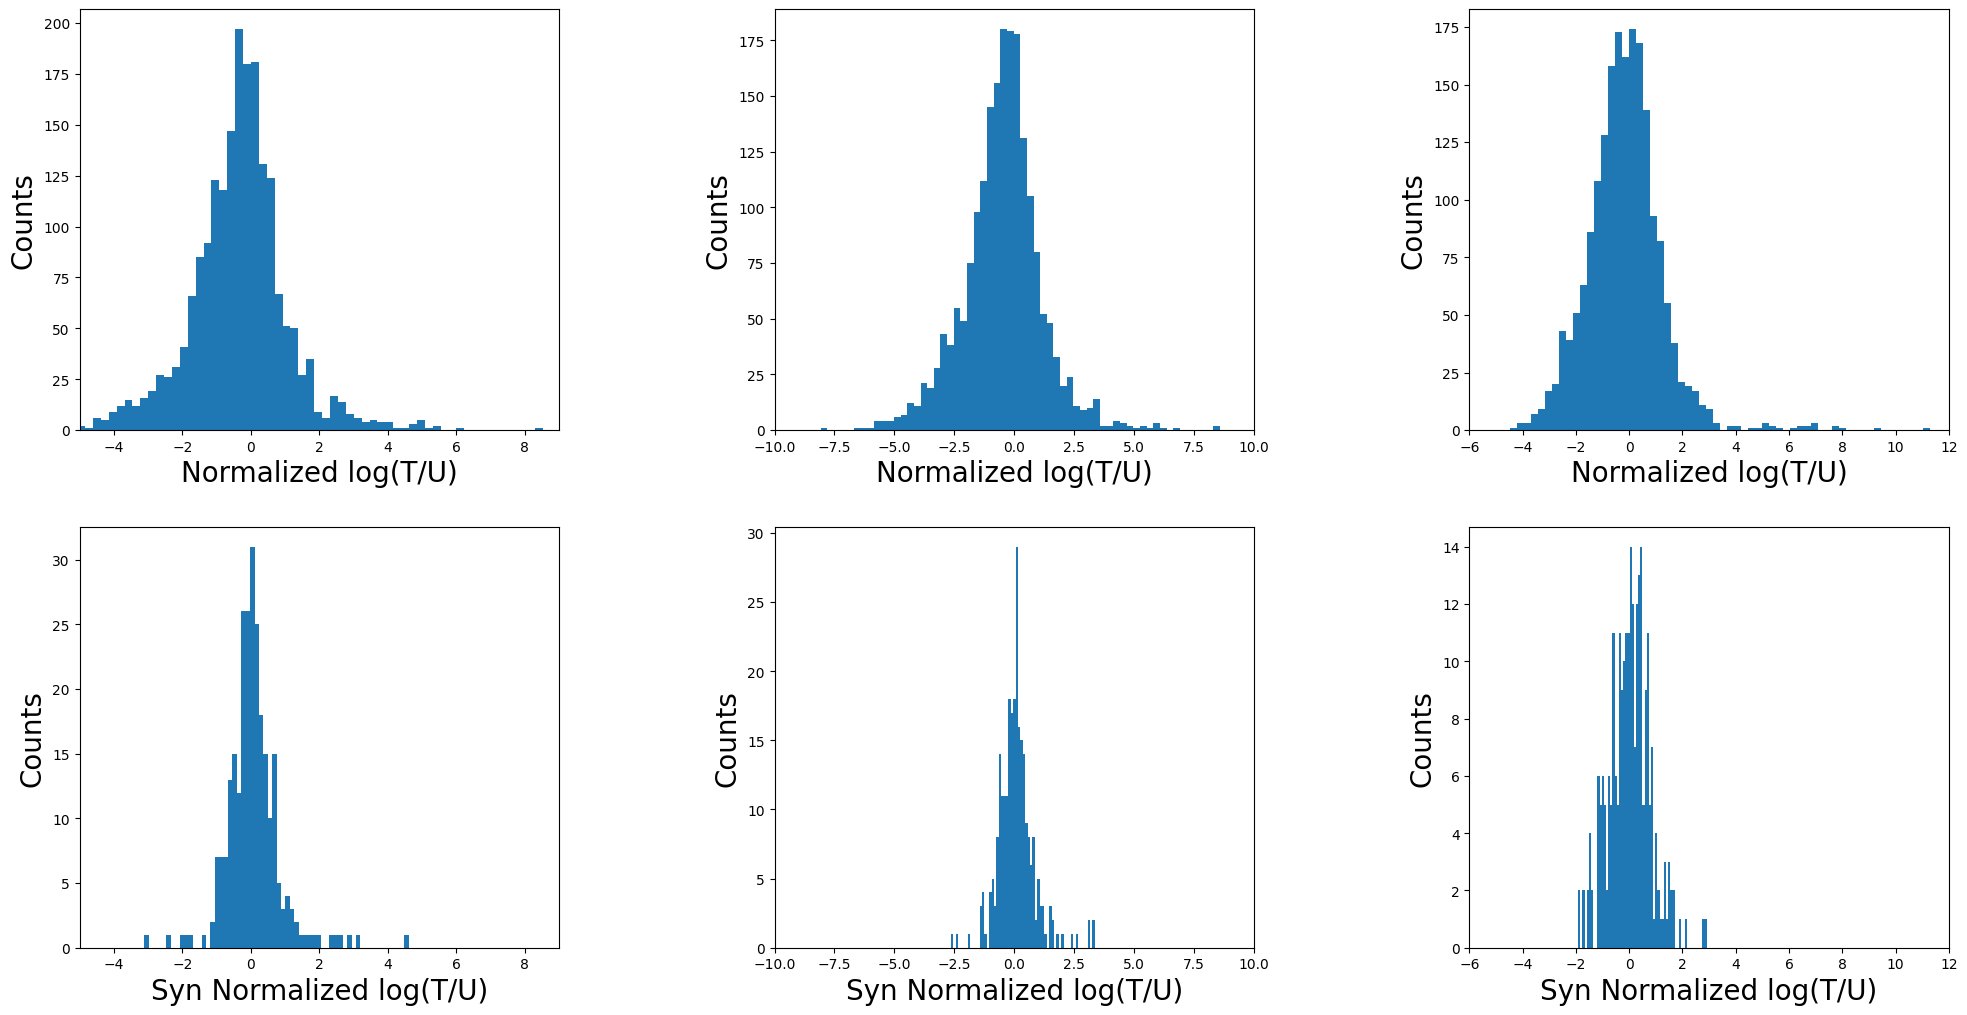

In [64]:
# Plot score distribution under each treatment
fig, axs = plt.subplots(2, 3)
datasets = [afa_scores, osi_scores, osi_T970M_scores]
xranges = ((-5, 9), (-10, 10), (-6, 12))
for i in range(len(datasets)):
    axs[0, i].hist(list(datasets[i].values()), bins=60)
    axs[0, i].set_xlabel("Normalized log(T/U)", size=20)
    axs[0, i].set_xlim(xranges[i])
    axs[0, i].set_ylabel("Counts", size=20)

    syn_scores = [datasets[i][key] for key in datasets[i] if key[0] == key[2]]
    axs[1, i].hist(list(syn_scores), bins=60)
    axs[1, i].set_xlabel("Syn Normalized log(T/U)", size=20)
    axs[1, i].set_xlim(xranges[i])
    axs[1, i].set_ylabel("Counts", size=20)
    print(f"Treatment {i} syn std, mean: {np.mean(syn_scores)}, {np.std(syn_scores)}")

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [65]:
# Save difference scores to output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
proteins = ["EGFR", "EGFR", "EGFR_T790M"]
treatments = ["Afa_3nM", "Osi_8nM", "Osi_8nM"]
for treat_i in range(len(datasets)):
    for wt, pos, mut in datasets[treat_i]:
        prot_col.append(proteins[treat_i])
        ligand_col.append(treatments[treat_i])
        wt_col.append(wt)
        pos_col.append(pos)
        mut_col.append(mut)
        score_col.append(datasets[treat_i][(wt, pos, mut)])

write_formatted_data("EGFR_Kim_2024.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"))

In [66]:
# Save the tails of the difference scores to an additional output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
proteins = ["EGFR", "EGFR", "EGFR_T790M"]
treatments = ["Afa_3nM", "Osi_8nM", "Osi_8nM"]
for treat_i in range(len(datasets)):
    diff_mean = np.mean(list(datasets[treat_i].values()))
    diff_std = np.std(list(datasets[treat_i].values()))
    print(f"Treatment {treat_i} mean, std: {diff_mean}, {diff_std}")
    
    for wt, pos, mut in datasets[treat_i]:
        if np.abs(np.mean(datasets[treat_i][(wt, pos, mut)]) - diff_mean) > diff_std:
            prot_col.append(proteins[treat_i])
            ligand_col.append(treatments[treat_i])
            wt_col.append(wt)
            pos_col.append(pos)
            mut_col.append(mut)
            score_col.append(datasets[treat_i][(wt, pos, mut)])

write_formatted_data("EGFR_Kim_2024_tail.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"),
                     directory=difference_tail_dir)

Treatment 0 mean, std: -0.3411631356219206, 1.4080092582450858
Treatment 1 mean, std: -0.49176823051483165, 1.6543882037449165
Treatment 2 mean, std: -0.16383284438493506, 1.431474943546364


## CDK4/6 Persky 2020

### CDK4

In [31]:
# Load CDK4 scores (treated and untreated) from Persky et al data
cdk4_persky_data = load_raw_data("CDK4-Persky-2020.csv", (0, 1, 2, 21, 25), header=2)
cdk4_persky_control = {}
cdk4_persky_control_minor = {}
cdk4_persky_treat = {}
cdk4_persky_treat_minor = {}
minor_aa = ('L', 'I', 'V')
for i in range(len(cdk4_persky_data[0])):
    aa_from = cdk4_persky_data[0][i]
    position = cdk4_persky_data[1][i]
    aa_to = cdk4_persky_data[2][i]
    
    cdk4_persky_control[(aa_from, position, aa_to)] = float(cdk4_persky_data[4][i])
    if aa_from in minor_aa and aa_to in minor_aa and abs(float(cdk4_persky_data[4][i])) < 0.4: 
        cdk4_persky_control_minor[(aa_from, position, aa_to)] = float(cdk4_persky_data[4][i])
        
    cdk4_persky_treat[(aa_from, position, aa_to)] = float(cdk4_persky_data[3][i])
    if aa_from in minor_aa and aa_to in minor_aa and float(cdk4_persky_data[3][i]) < 1: 
        cdk4_persky_treat_minor[(aa_from, position, aa_to)] = float(cdk4_persky_data[3][i])

cdk4_persky_control_minor_mean = np.mean(list(cdk4_persky_control_minor.values()))
cdk4_persky_treat_minor_mean = np.mean(list(cdk4_persky_treat_minor.values()))
print(f"CDK4 control mean, std: {np.mean(list(cdk4_persky_control.values()))}, {np.std(list(cdk4_persky_control.values()))}")
print(f"CDK4 control minor mean, std: {cdk4_persky_control_minor_mean}, {np.std(list(cdk4_persky_control_minor.values()))}")
print(f"CDK4 treat mean, std: {np.mean(list(cdk4_persky_treat.values()))}, {np.std(list(cdk4_persky_treat.values()))}")
print(f"CDK4 treat minor mean, std: {cdk4_persky_treat_minor_mean}, {np.std(list(cdk4_persky_treat_minor.values()))}")

CDK4 control mean, std: -0.01703379288035901, 0.3212751096315023
CDK4 control minor mean, std: -0.02367283122033899, 0.19512848926172696
CDK4 treat mean, std: -0.18821242328006274, 0.47178503620525525
CDK4 treat minor mean, std: -0.23838335307801417, 0.3441584015048172


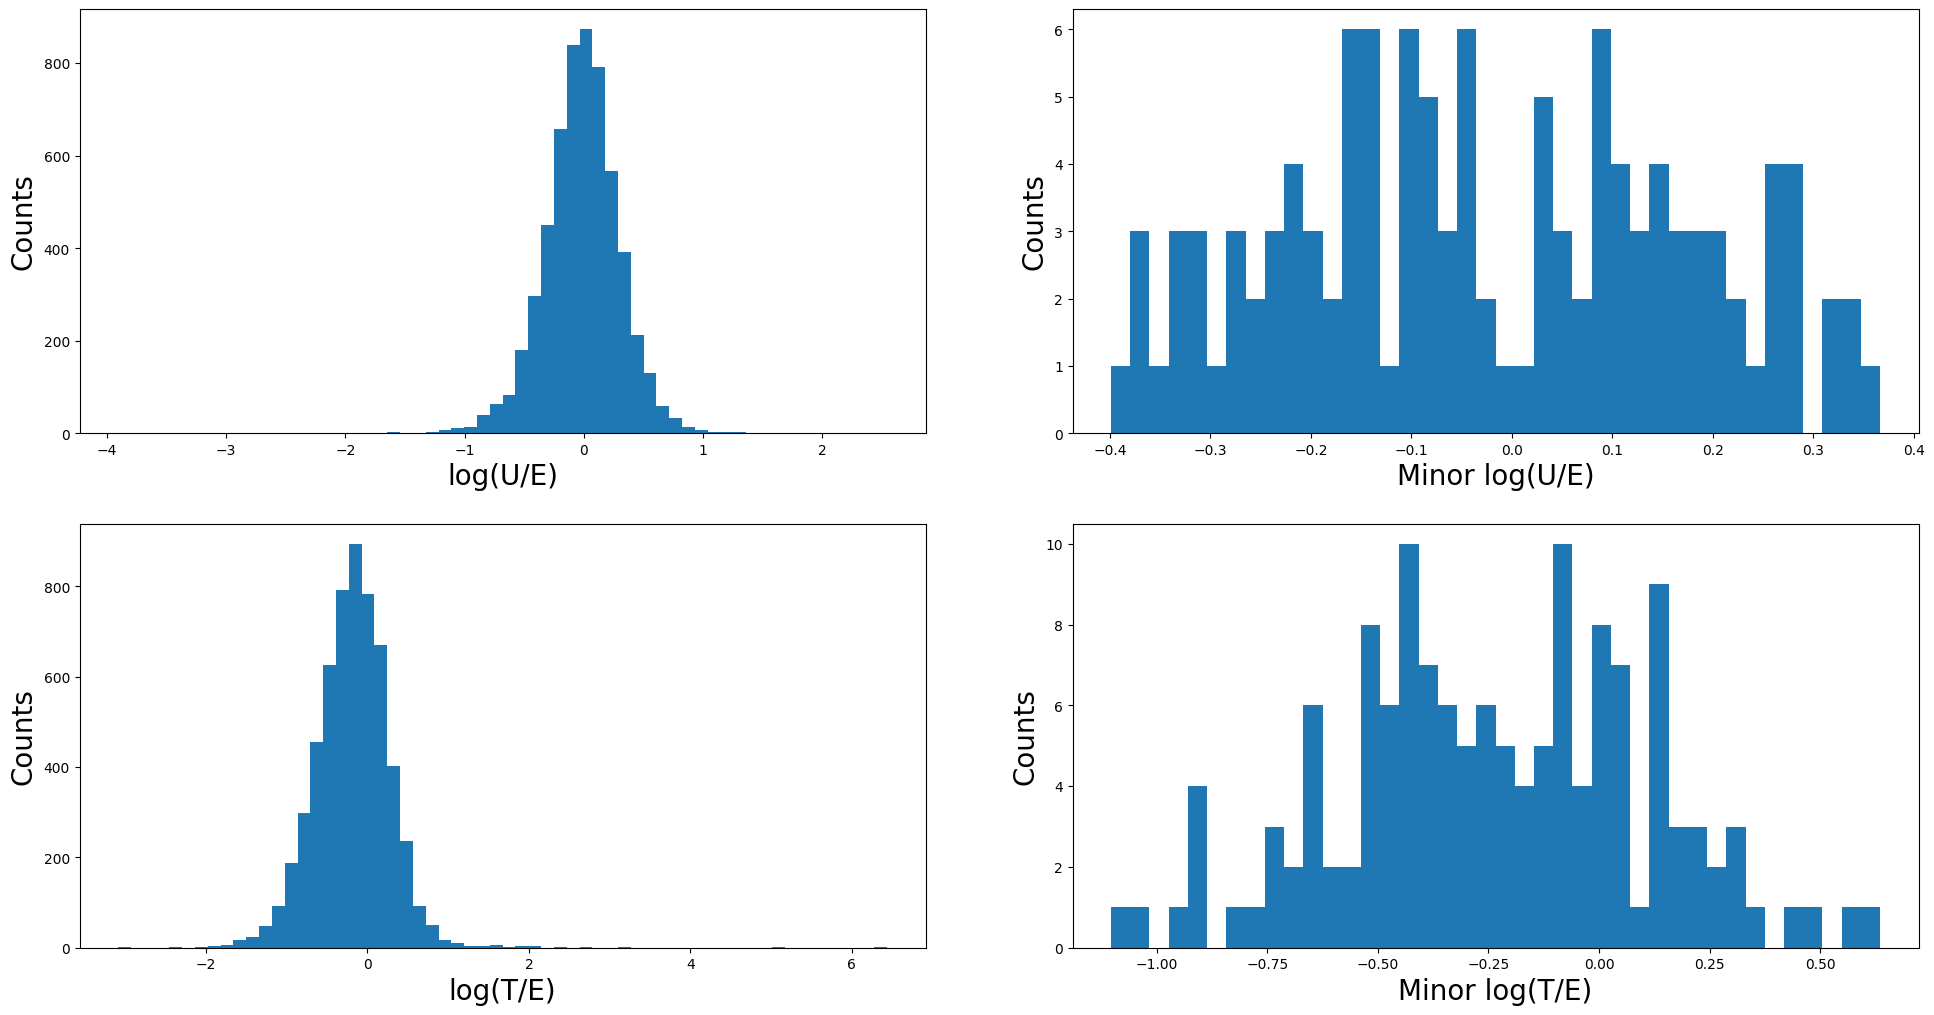

In [32]:
# Plot score distributions and minor mutation distributions
fig, axs = plt.subplots(2, 2)
axs[0, 0].hist(list(cdk4_persky_control.values()), bins=60)
axs[0, 0].set_xlabel("log(U/E)", size=20)
axs[0, 0].set_ylabel("Counts", size=20)
axs[0, 1].hist(list(cdk4_persky_control_minor.values()), bins=40)
axs[0, 1].set_xlabel("Minor log(U/E)", size=20)
axs[0, 1].set_ylabel("Counts", size=20)

axs[1, 0].hist(list(cdk4_persky_treat.values()), bins=60)
axs[1, 0].set_xlabel("log(T/E)", size=20)
axs[1, 0].set_ylabel("Counts", size=20)
axs[1, 1].hist(list(cdk4_persky_treat_minor.values()), bins=40)
axs[1, 1].set_xlabel("Minor log(T/E)", size=20)
axs[1, 1].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [33]:
# Normalize datasets by minor mutations (as replacement for wild type)
for key in cdk4_persky_control:
    cdk4_persky_control[key] = cdk4_persky_control[key] - cdk4_persky_control_minor_mean
for key in cdk4_persky_treat:
    cdk4_persky_treat[key] = cdk4_persky_treat[key] - cdk4_persky_treat_minor_mean

In [17]:
# Calculate score differences in treated and control conditions
cdk4_persky_diff = {}
for key in cdk4_persky_control:
    if key in cdk4_persky_treat:
        cdk4_persky_diff[key] = cdk4_persky_treat[key] - cdk4_persky_control[key]

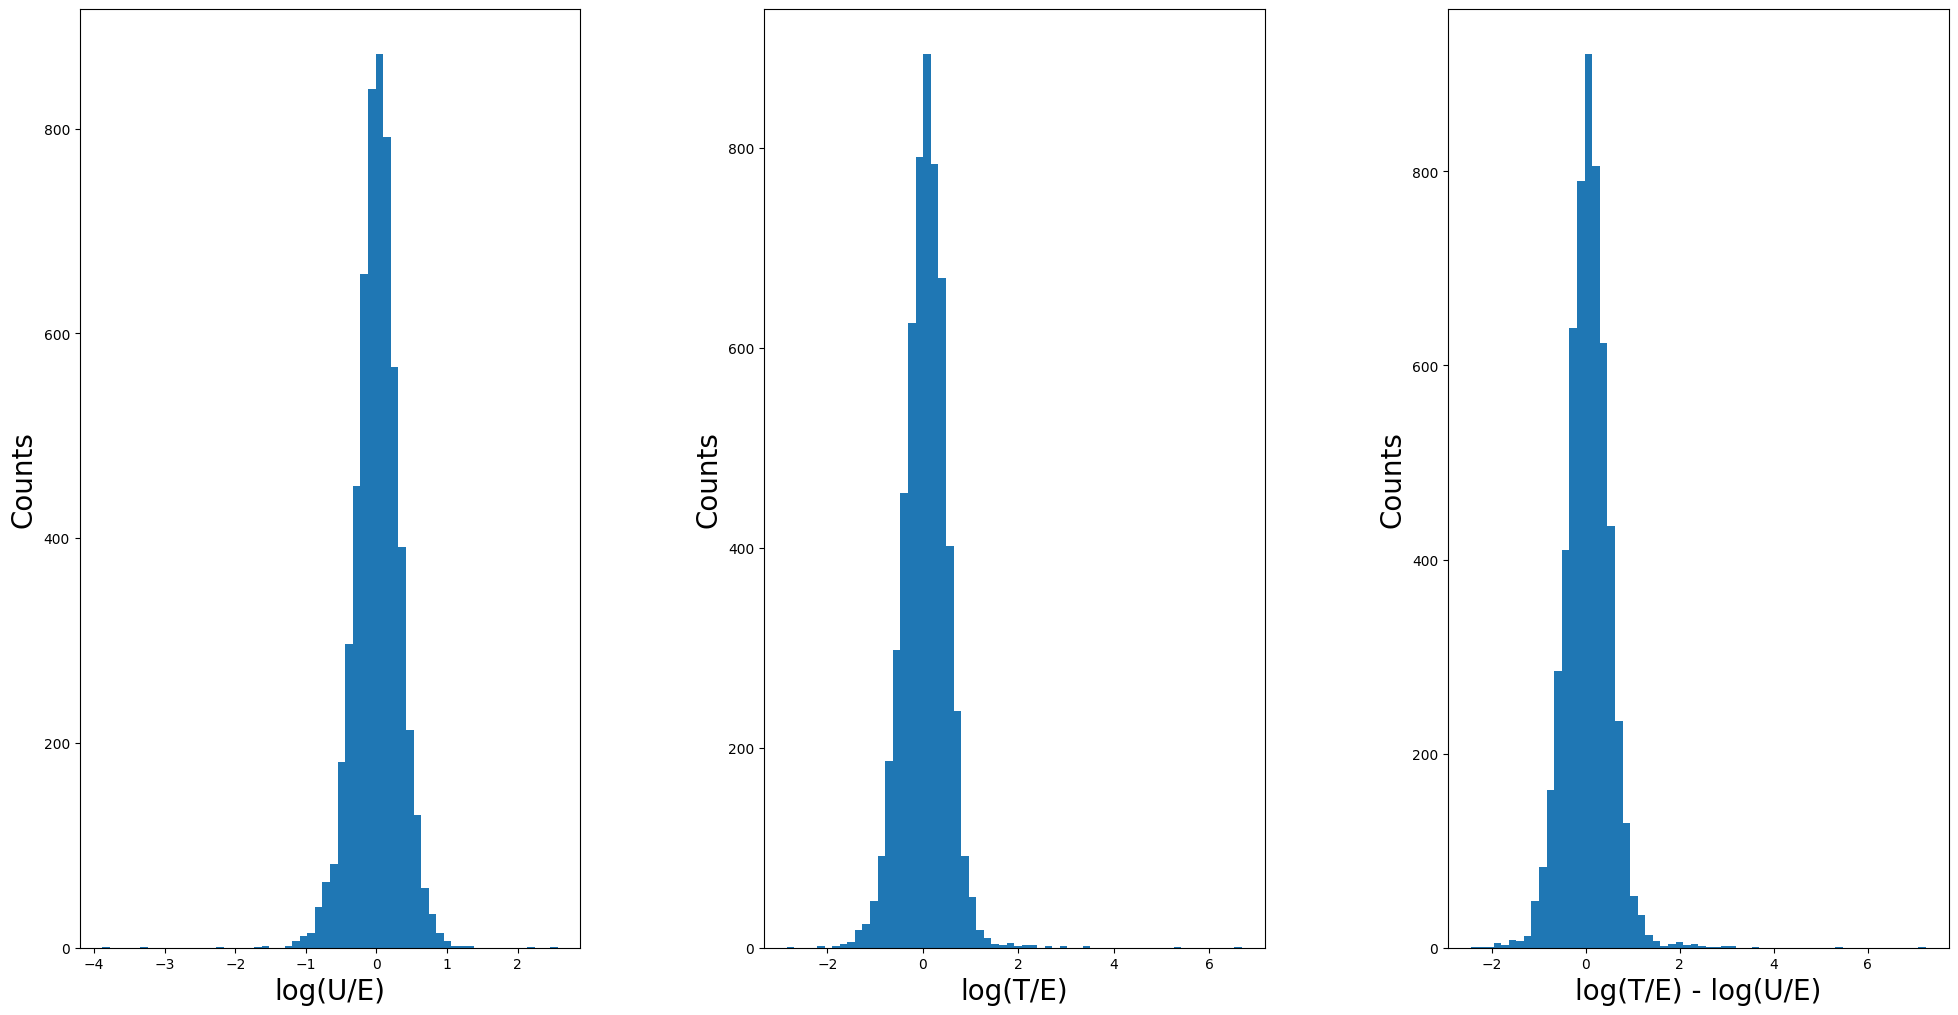

In [18]:
# Plot untreated, treated, and difference distributions
fig, axs = plt.subplots(1, 3)
datasets = [cdk4_persky_control, cdk4_persky_treat, cdk4_persky_diff]
for i in range(len(datasets)):
    axs[i].hist(list(datasets[i].values()), bins=60)
    if i == 0:
        axs[i].set_xlabel("log(U/E)", size=20)
    elif i == 1:
        axs[i].set_xlabel("log(T/E)", size=20)
    elif i == 2:
        axs[i].set_xlabel("log(T/E) - log(U/E)", size=20)
    axs[i].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

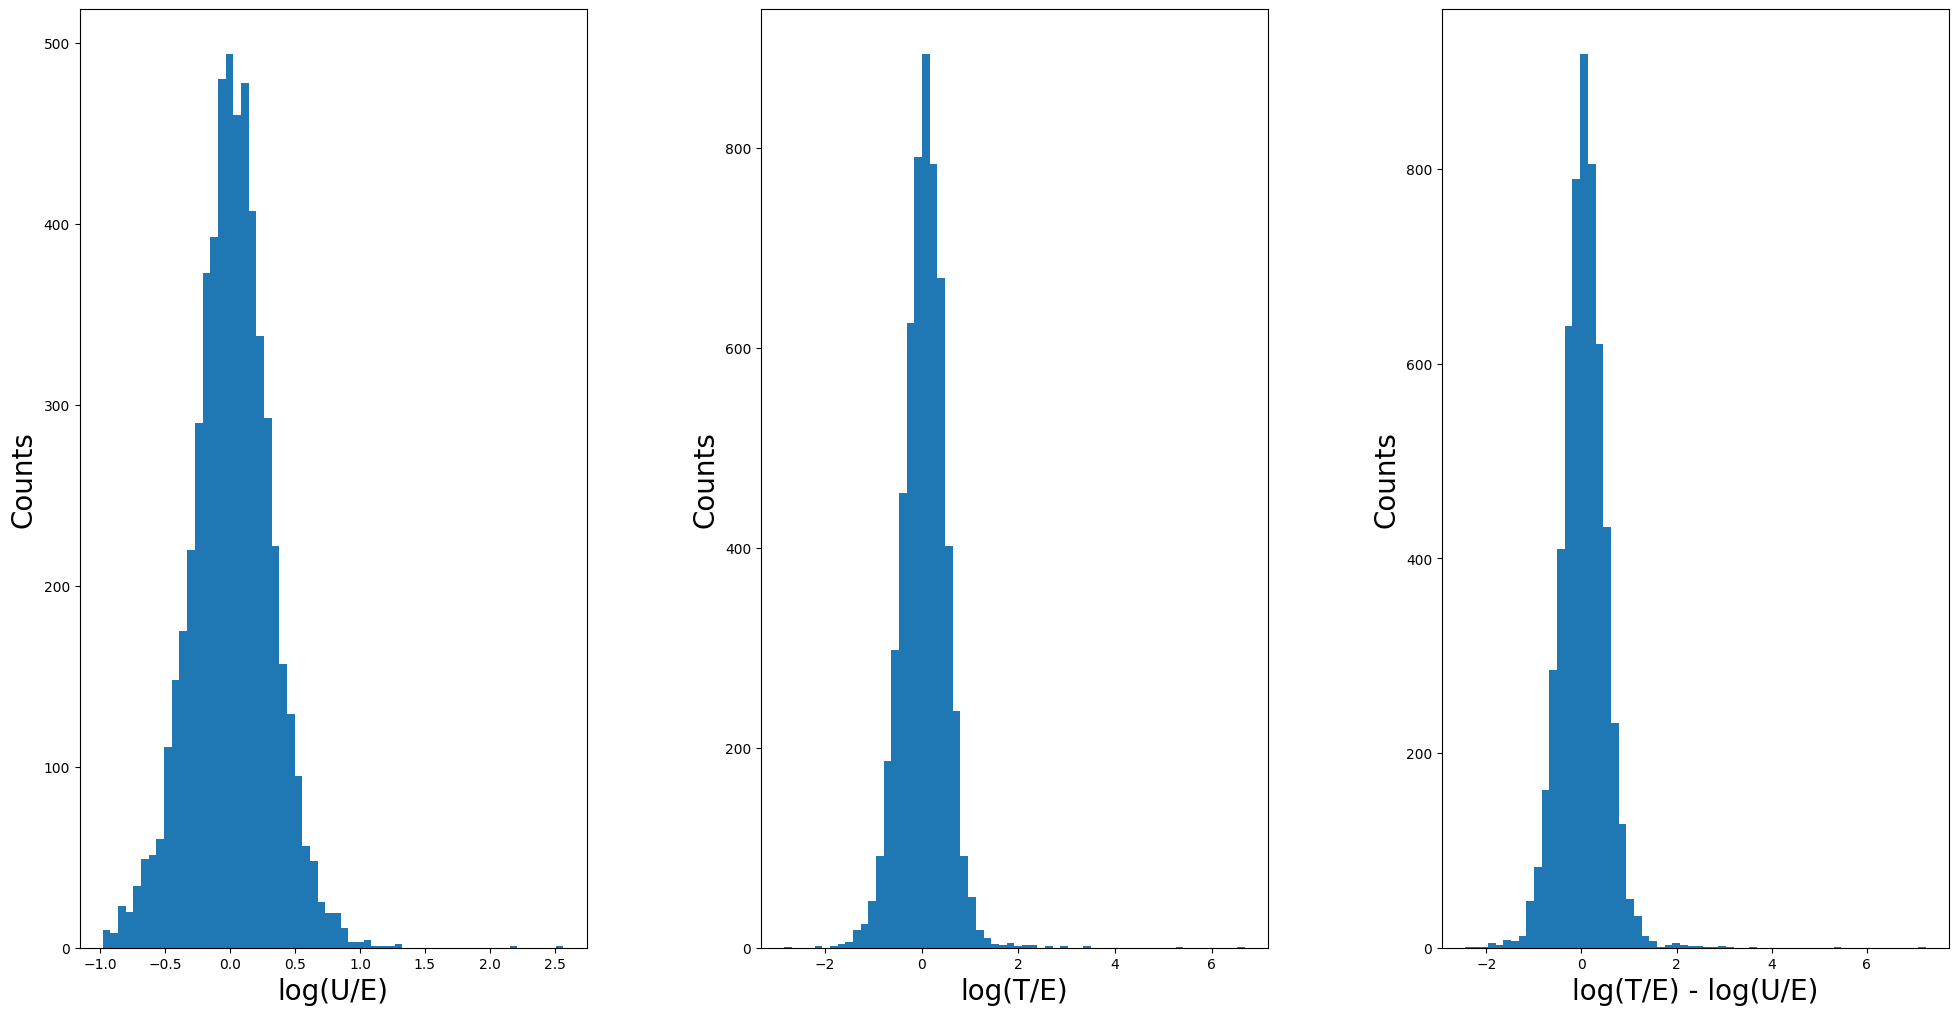

In [34]:
# Stop codons already excluded
# Remove extreme LoF scores below -1
cdk4_persky_control = {key: cdk4_persky_control[key] for key in cdk4_persky_control if cdk4_persky_control[key] > -1}
# Recalculate score differences and plot their distribution
cdk4_persky_diff = {}
for key in cdk4_persky_control:
    if key in cdk4_persky_treat:
        cdk4_persky_diff[key] = cdk4_persky_treat[key] - cdk4_persky_control[key]

fig, axs = plt.subplots(1, 3)
datasets = [cdk4_persky_control, cdk4_persky_treat, cdk4_persky_diff]
for i in range(len(datasets)):
    axs[i].hist(list(datasets[i].values()), bins=60)
    if i == 0:
        axs[i].set_xlabel("log(U/E)", size=20)
    elif i == 1:
        axs[i].set_xlabel("log(T/E)", size=20)
    elif i == 2:
        axs[i].set_xlabel("log(T/E) - log(U/E)", size=20)
    axs[i].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [36]:
# Save difference scores to output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

for wt, pos, mut in cdk4_persky_diff:
    prot_col.append("CDK4")
    ligand_col.append("Pal_2uM")
    wt_col.append(wt)
    pos_col.append(pos)
    mut_col.append(mut)
    score_col.append(cdk4_persky_diff[(wt, pos, mut)])

write_formatted_data("CDK4_Persky_2020.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"))

In [39]:
# Save the tails of difference scores to another output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

cdk4_persky_diff_mean = np.mean(list(cdk4_persky_diff.values()))
cdk4_persky_diff_std = np.std(list(cdk4_persky_diff.values()))
print(f"CDK4 score difference mean, std: {cdk4_persky_diff_mean}, {cdk4_persky_diff_std}")

for wt, pos, mut in cdk4_persky_diff:
    if np.abs(cdk4_persky_diff[(wt, pos, mut)] - cdk4_persky_diff_mean) > cdk4_persky_diff_std:
        prot_col.append("CDK4")
        ligand_col.append("Pal_2uM")
        wt_col.append(wt)
        pos_col.append(pos)
        mut_col.append(mut)
        score_col.append(cdk4_persky_diff[(wt, pos, mut)])

write_formatted_data("CDK4_Persky_2020_tail.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"),
                     directory=difference_tail_dir)

CDK4 score difference mean, std: 0.03947050879527364, 0.4816640995812212


### CDK6

In [44]:
# Load CDK6 scores (treated and untreated) from Persky et al data
cdk6_persky_data = load_raw_data("CDK6-Persky-2020.csv", (0, 1, 2, 21, 25), header=2)
cdk6_persky_control = {}
cdk6_persky_control_minor = {}
cdk6_persky_treat = {}
cdk6_persky_treat_minor = {}
minor_aa = ('L', 'I', 'V')
for i in range(len(cdk6_persky_data[0])):
    aa_from = cdk6_persky_data[0][i]
    position = cdk6_persky_data[1][i]
    aa_to = cdk6_persky_data[2][i]
    
    cdk6_persky_control[(aa_from, position, aa_to)] = float(cdk6_persky_data[4][i])
    if aa_from in minor_aa and aa_to in minor_aa and -0.75 < float(cdk6_persky_data[4][i]) < 0.6: 
        cdk6_persky_control_minor[(aa_from, position, aa_to)] = float(cdk6_persky_data[4][i])
        
    cdk6_persky_treat[(aa_from, position, aa_to)] = float(cdk6_persky_data[3][i])
    if aa_from in minor_aa and aa_to in minor_aa and -2.5 < float(cdk6_persky_data[3][i]) < 0.5: 
        cdk6_persky_treat_minor[(aa_from, position, aa_to)] = float(cdk6_persky_data[3][i])

cdk6_persky_control_minor_mean = np.mean(list(cdk6_persky_control_minor.values()))
cdk6_persky_treat_minor_mean = np.mean(list(cdk6_persky_treat_minor.values()))
print(f"CDK6 control mean, std: {np.mean(list(cdk6_persky_control.values()))}, {np.std(list(cdk6_persky_control.values()))}")
print(f"CDK6 control minor mean, std: {cdk6_persky_control_minor_mean}, {np.std(list(cdk6_persky_control_minor.values()))}")
print(f"CDK6 treat mean, std: {np.mean(list(cdk6_persky_treat.values()))}, {np.std(list(cdk6_persky_treat.values()))}")
print(f"CDK6 treat minor mean, std: {cdk6_persky_treat_minor_mean}, {np.std(list(cdk6_persky_treat_minor.values()))}")

CDK6 control mean, std: -0.11453984183935222, 0.4780289977230599
CDK6 control minor mean, std: -0.07800280229591837, 0.30491217969784096
CDK6 treat mean, std: -1.1218651876848582, 1.2417772437891659
CDK6 treat minor mean, std: -0.9692087008345865, 0.6470181770400001


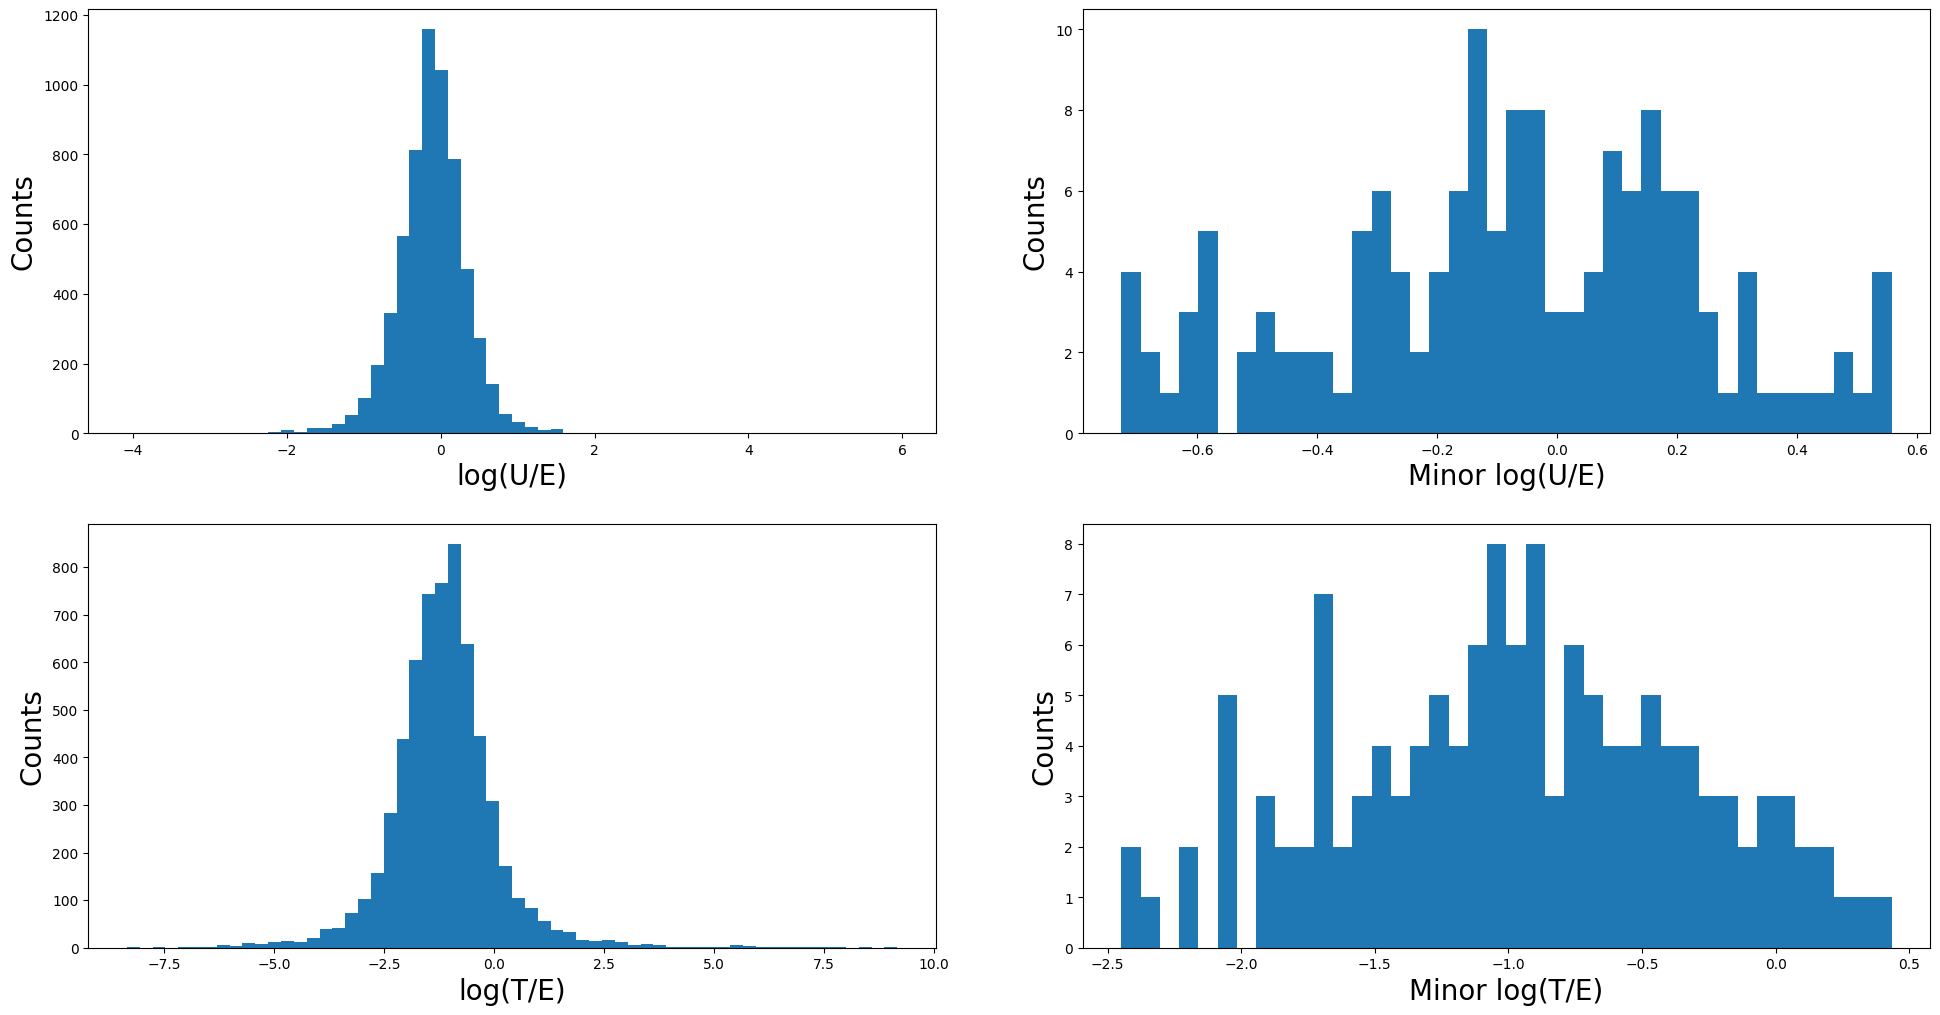

In [45]:
# Plot score distributions and minor mutation distributions
fig, axs = plt.subplots(2, 2)
axs[0, 0].hist(list(cdk6_persky_control.values()), bins=60)
axs[0, 0].set_xlabel("log(U/E)", size=20)
axs[0, 0].set_ylabel("Counts", size=20)
axs[0, 1].hist(list(cdk6_persky_control_minor.values()), bins=40)
axs[0, 1].set_xlabel("Minor log(U/E)", size=20)
axs[0, 1].set_ylabel("Counts", size=20)

axs[1, 0].hist(list(cdk6_persky_treat.values()), bins=60)
axs[1, 0].set_xlabel("log(T/E)", size=20)
axs[1, 0].set_ylabel("Counts", size=20)
axs[1, 1].hist(list(cdk6_persky_treat_minor.values()), bins=40)
axs[1, 1].set_xlabel("Minor log(T/E)", size=20)
axs[1, 1].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [46]:
# Normalize score distributions by minor mutations
for key in cdk6_persky_control:
    cdk6_persky_control[key] = cdk6_persky_control[key] - cdk6_persky_control_minor_mean
for key in cdk6_persky_treat:
    cdk6_persky_treat[key] = cdk6_persky_treat[key] - cdk6_persky_treat_minor_mean

In [47]:
# Calculate difference between treated and untreated scores
cdk6_persky_diff = {}
for key in cdk6_persky_control:
    if key in cdk6_persky_treat:
        cdk6_persky_diff[key] = cdk6_persky_treat[key] - cdk6_persky_control[key]

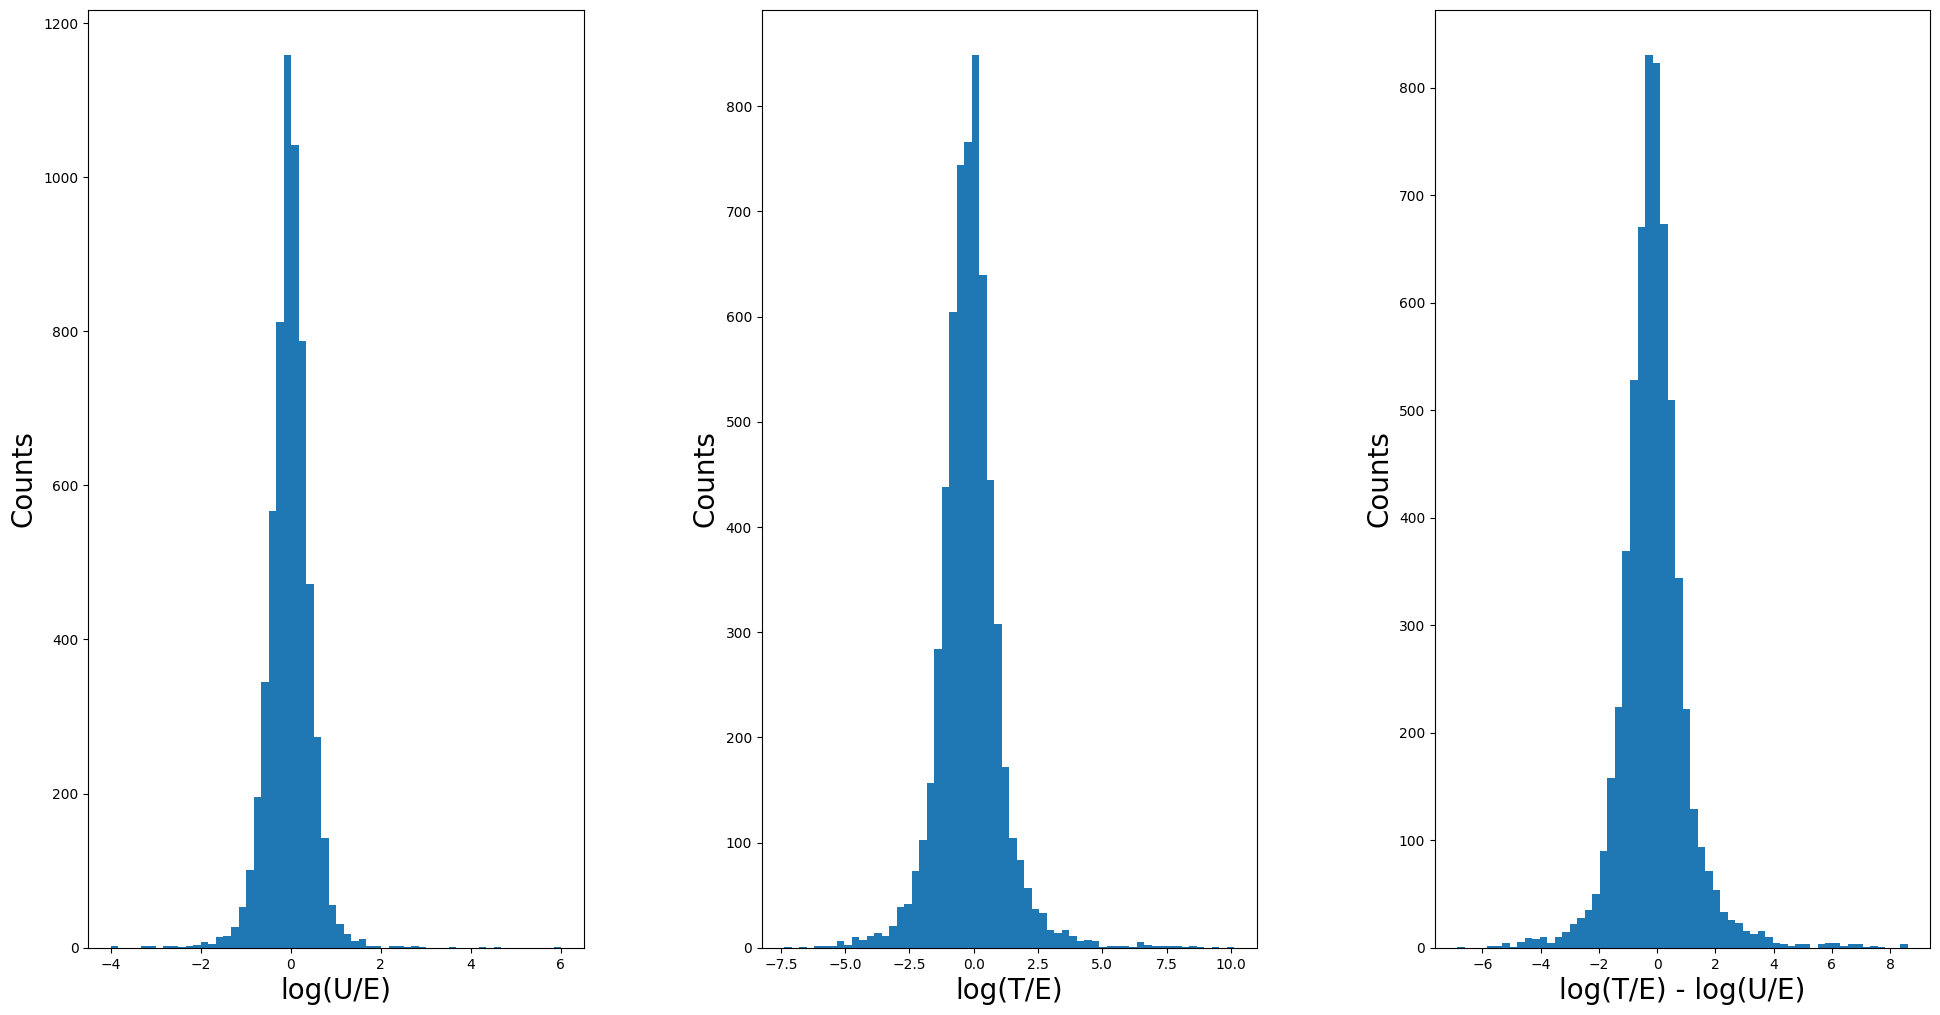

In [48]:
# Plot distribution of untreated, treated, and difference scores
fig, axs = plt.subplots(1, 3)
datasets = [cdk6_persky_control, cdk6_persky_treat, cdk6_persky_diff]
for i in range(len(datasets)):
    axs[i].hist(list(datasets[i].values()), bins=60)
    if i == 0:
        axs[i].set_xlabel("log(U/E)", size=20)
    elif i == 1:
        axs[i].set_xlabel("log(T/E)", size=20)
    elif i == 2:
        axs[i].set_xlabel("log(T/E) - log(U/E)", size=20)
    axs[i].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

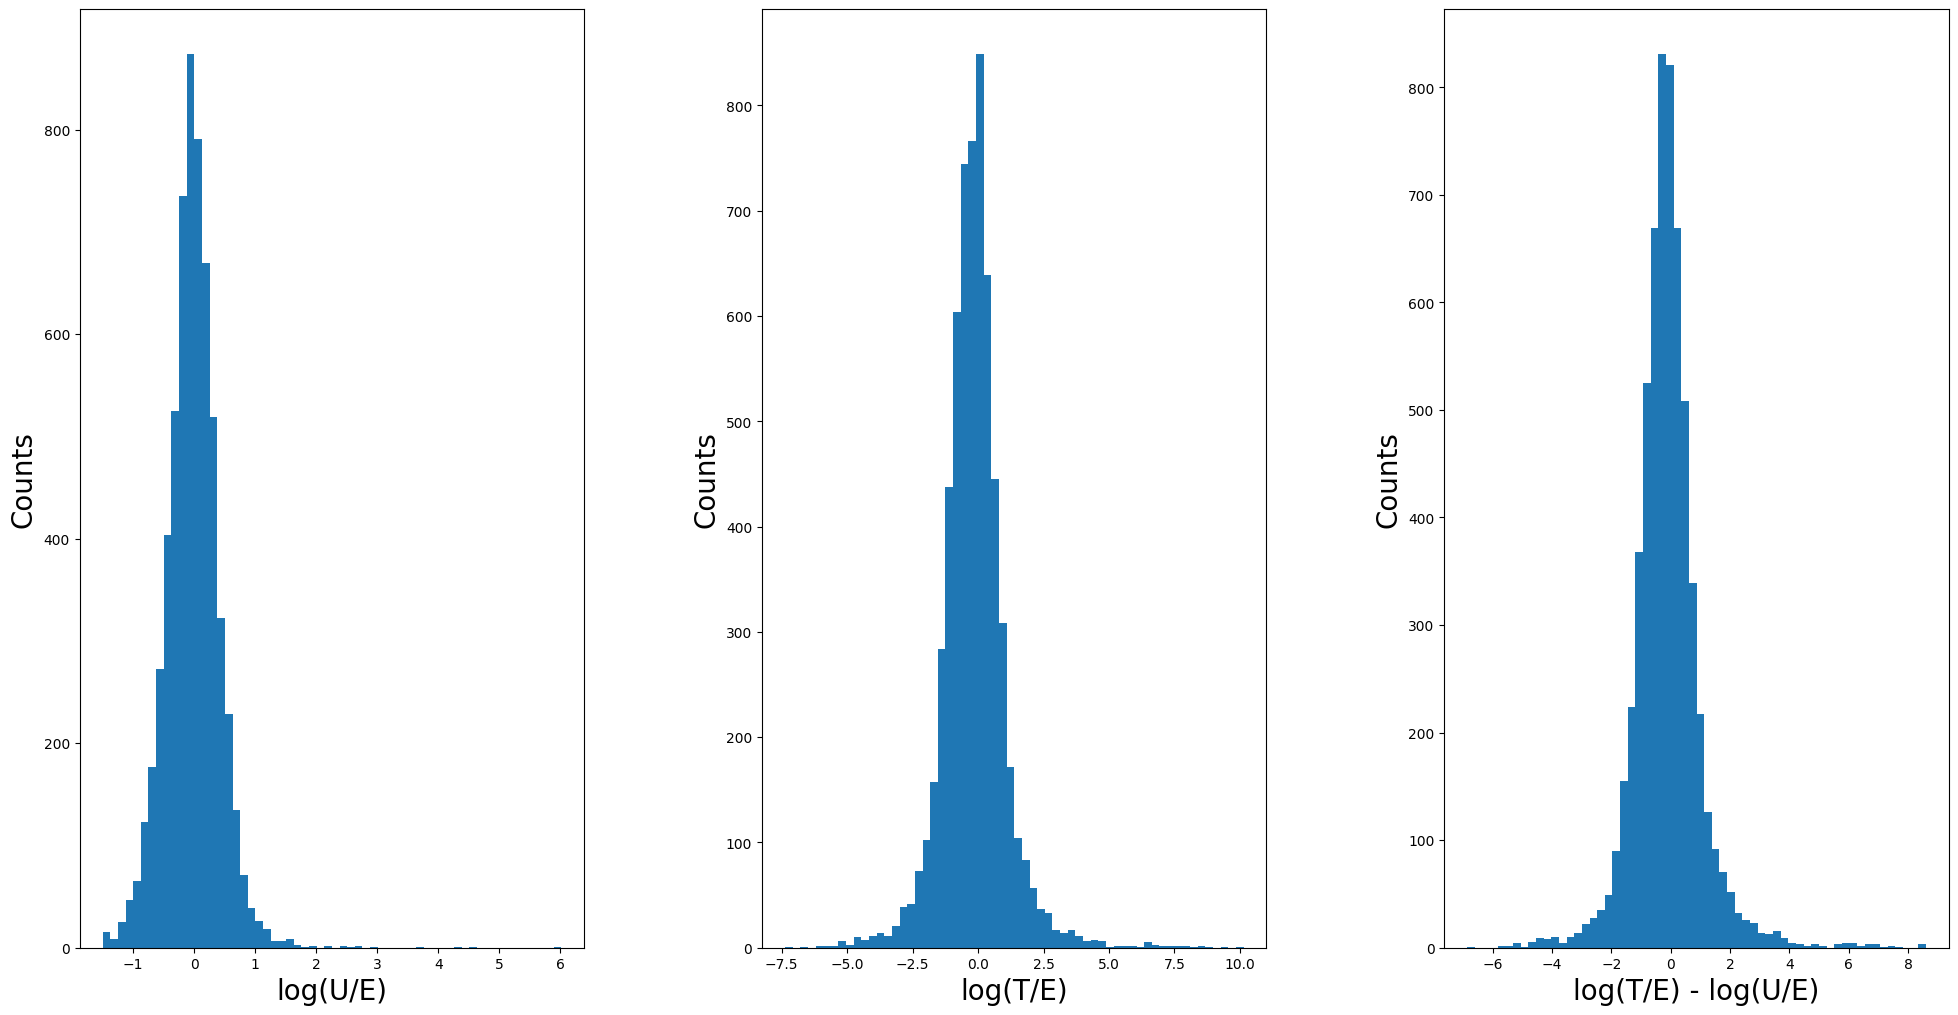

In [49]:
# Stop codons already excluded
# Remove extreme LoF scores below -1.5
cdk6_persky_control = {key: cdk6_persky_control[key] for key in cdk6_persky_control if cdk6_persky_control[key] > -1.5}
# Recalculate score differences
cdk6_persky_diff = {}
for key in cdk6_persky_control:
    if key in cdk6_persky_treat:
        cdk6_persky_diff[key] = cdk6_persky_treat[key] - cdk6_persky_control[key]

fig, axs = plt.subplots(1, 3)
datasets = [cdk6_persky_control, cdk6_persky_treat, cdk6_persky_diff]
for i in range(len(datasets)):
    axs[i].hist(list(datasets[i].values()), bins=60)
    if i == 0:
        axs[i].set_xlabel("log(U/E)", size=20)
    elif i == 1:
        axs[i].set_xlabel("log(T/E)", size=20)
    elif i == 2:
        axs[i].set_xlabel("log(T/E) - log(U/E)", size=20)
    axs[i].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [51]:
# Save difference scores to output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

for wt, pos, mut in cdk6_persky_diff:
    prot_col.append("CDK6")
    ligand_col.append("Pal_2uM")
    wt_col.append(wt)
    pos_col.append(pos)
    mut_col.append(mut)
    score_col.append(cdk6_persky_diff[(wt, pos, mut)])

write_formatted_data("CDK6_Persky_2020.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"))

In [53]:
# Save the tails of difference scores to another output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

cdk6_persky_diff_mean = np.mean(list(cdk6_persky_diff.values()))
cdk6_persky_diff_std = np.std(list(cdk6_persky_diff.values()))
print(f"CDK6 score difference mean, std: {cdk6_persky_diff_mean}, {cdk6_persky_diff_std}")

for wt, pos, mut in cdk6_persky_diff:
    if np.abs(cdk6_persky_diff[(wt, pos, mut)] - cdk6_persky_diff_mean) > cdk6_persky_diff_std:
        prot_col.append("CDK6")
        ligand_col.append("Pal_2uM")
        wt_col.append(wt)
        pos_col.append(pos)
        mut_col.append(mut)
        score_col.append(cdk6_persky_diff[(wt, pos, mut)])

write_formatted_data("CDK6_Persky_2020_tail.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"),
                     directory=difference_tail_dir)

CDK6 score difference mean, std: -0.12112048443459127, 1.1383701331816731


## SRC Chakraborty 2024

In [54]:
# Load the relevant datasets
SRC_Ahler_control = load_raw_data("SRC-Ahler-2019-CD-control.csv", (0, 4), header=3,
                                  directory=raw_data_dir, sep=",")
SRC_Ahler_control_dict = {}
for i in range(len(SRC_Ahler_control[0])):
    wt = aa3to1[SRC_Ahler_control[0][i][2:5].upper()]
    pos = SRC_Ahler_control[0][i][5:-3]
    mut = aa3to1[SRC_Ahler_control[0][i][-3:].upper()]
    SRC_Ahler_control_dict[(wt, pos, mut)] = float(SRC_Ahler_control[1][i])

SRC_Chakraborty_Dis_25uM = load_raw_data("SRC-Chakraborty-2024-dasatinib25uM.csv", (1, 2, 3, 4), header=2)
SRC_Chakraborty_Dis_25uM_dict = {}
for i in range(len(SRC_Chakraborty_Dis_25uM[0])):
    wt = aa3to1[SRC_Chakraborty_Dis_25uM[1][i].upper()]
    pos = SRC_Chakraborty_Dis_25uM[2][i]
    mut = aa3to1[SRC_Chakraborty_Dis_25uM[3][i].upper()]
    SRC_Chakraborty_Dis_25uM_dict[(wt, pos, mut)] = float(SRC_Chakraborty_Dis_25uM[0][i])

SRC_Chakraborty_Dis_100uM = load_raw_data("SRC-Chakraborty-2024-dasatinib100uM.csv", (1, 2, 3, 4), header=2)
SRC_Chakraborty_Dis_100uM_dict = {}
for i in range(len(SRC_Chakraborty_Dis_100uM[0])):
    wt = aa3to1[SRC_Chakraborty_Dis_100uM[0][i].upper()]
    pos = SRC_Chakraborty_Dis_100uM[1][i]
    mut = aa3to1[SRC_Chakraborty_Dis_100uM[2][i].upper()]
    if SRC_Chakraborty_Dis_100uM[3][i] != "":
        SRC_Chakraborty_Dis_100uM_dict[(wt, pos, mut)] = float(SRC_Chakraborty_Dis_100uM[3][i])

SRC_Chakraborty_I1 = load_raw_data("SRC-Chakraborty-2024-inhibitor1.csv", (1, 2, 3, 4), header=2)
SRC_Chakraborty_I1_dict = {}
for i in range(len(SRC_Chakraborty_I1[0])):
    wt = aa3to1[SRC_Chakraborty_I1[0][i].upper()]
    pos = SRC_Chakraborty_I1[1][i]
    mut = aa3to1[SRC_Chakraborty_I1[2][i].upper()]
    SRC_Chakraborty_I1_dict[(wt, pos, mut)] = float(SRC_Chakraborty_I1[3][i])

SRC_Chakraborty_I2 = load_raw_data("SRC-Chakraborty-2024-inhibitor2.csv", (1, 2, 3, 4), header=2)
SRC_Chakraborty_I2_dict = {}
for i in range(len(SRC_Chakraborty_I2[0])):
    wt = aa3to1[SRC_Chakraborty_I2[0][i].upper()]
    pos = SRC_Chakraborty_I2[1][i]
    mut = aa3to1[SRC_Chakraborty_I2[2][i].upper()]
    SRC_Chakraborty_I2_dict[(wt, pos, mut)] = float(SRC_Chakraborty_I2[3][i])

SRC_Chakraborty_I4 = load_raw_data("SRC-Chakraborty-2024-inhibitor4.csv", (1, 2, 3, 4), header=2)
SRC_Chakraborty_I4_dict = {}
for i in range(len(SRC_Chakraborty_I4[0])):
    wt = aa3to1[SRC_Chakraborty_I4[0][i].upper()]
    pos = SRC_Chakraborty_I4[1][i]
    mut = aa3to1[SRC_Chakraborty_I4[2][i].upper()]
    SRC_Chakraborty_I4_dict[(wt, pos, mut)] = float(SRC_Chakraborty_I4[3][i])

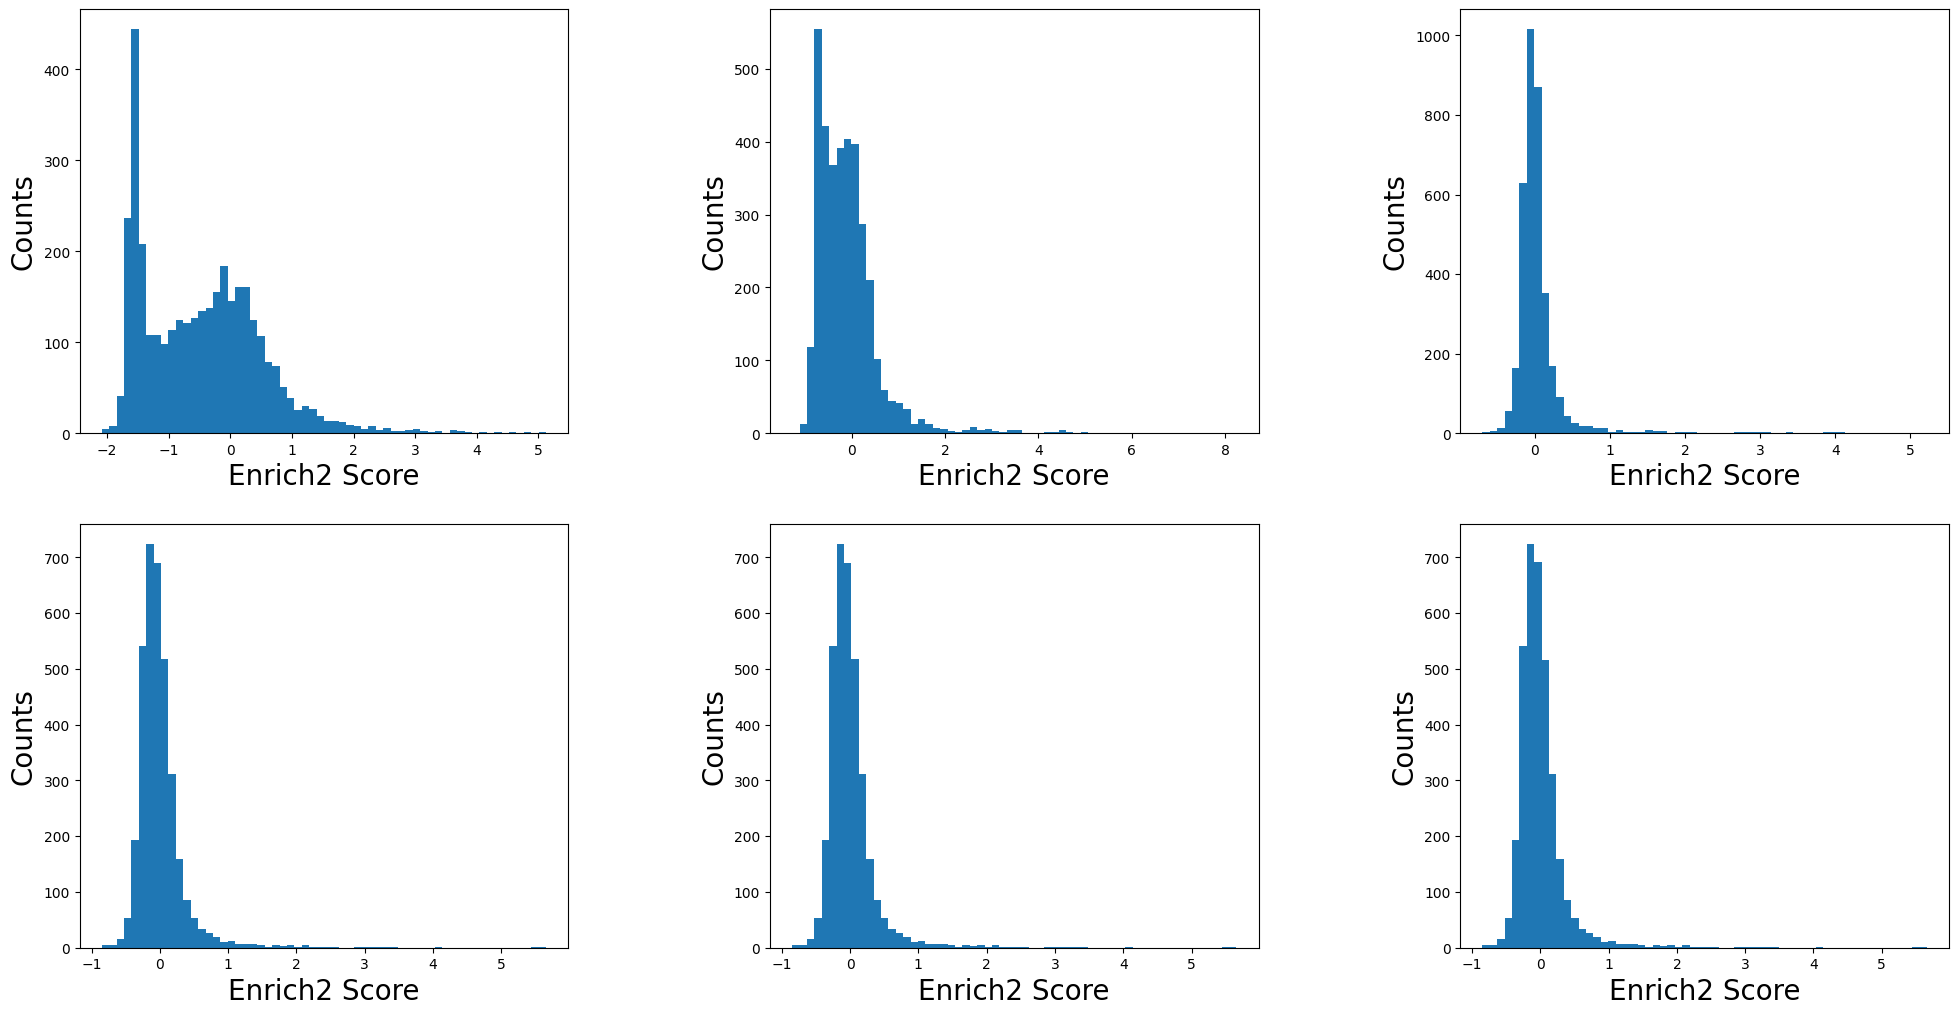

In [61]:
# Plot Enrich2 score distribution under each treatment
fig, axs = plt.subplots(2, 3)
datasets = [SRC_Ahler_control_dict, SRC_Chakraborty_Dis_25uM_dict, SRC_Chakraborty_Dis_100uM_dict,
            SRC_Chakraborty_I1_dict, SRC_Chakraborty_I2_dict, SRC_Chakraborty_I4_dict]
for i in range(len(datasets)):
    axs[i // 3, i % 3].hist(list(datasets[i].values()), bins=60)
    axs[i // 3, i % 3].set_xlabel("Enrich2 Score", size=20)
    axs[i // 3, i % 3].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

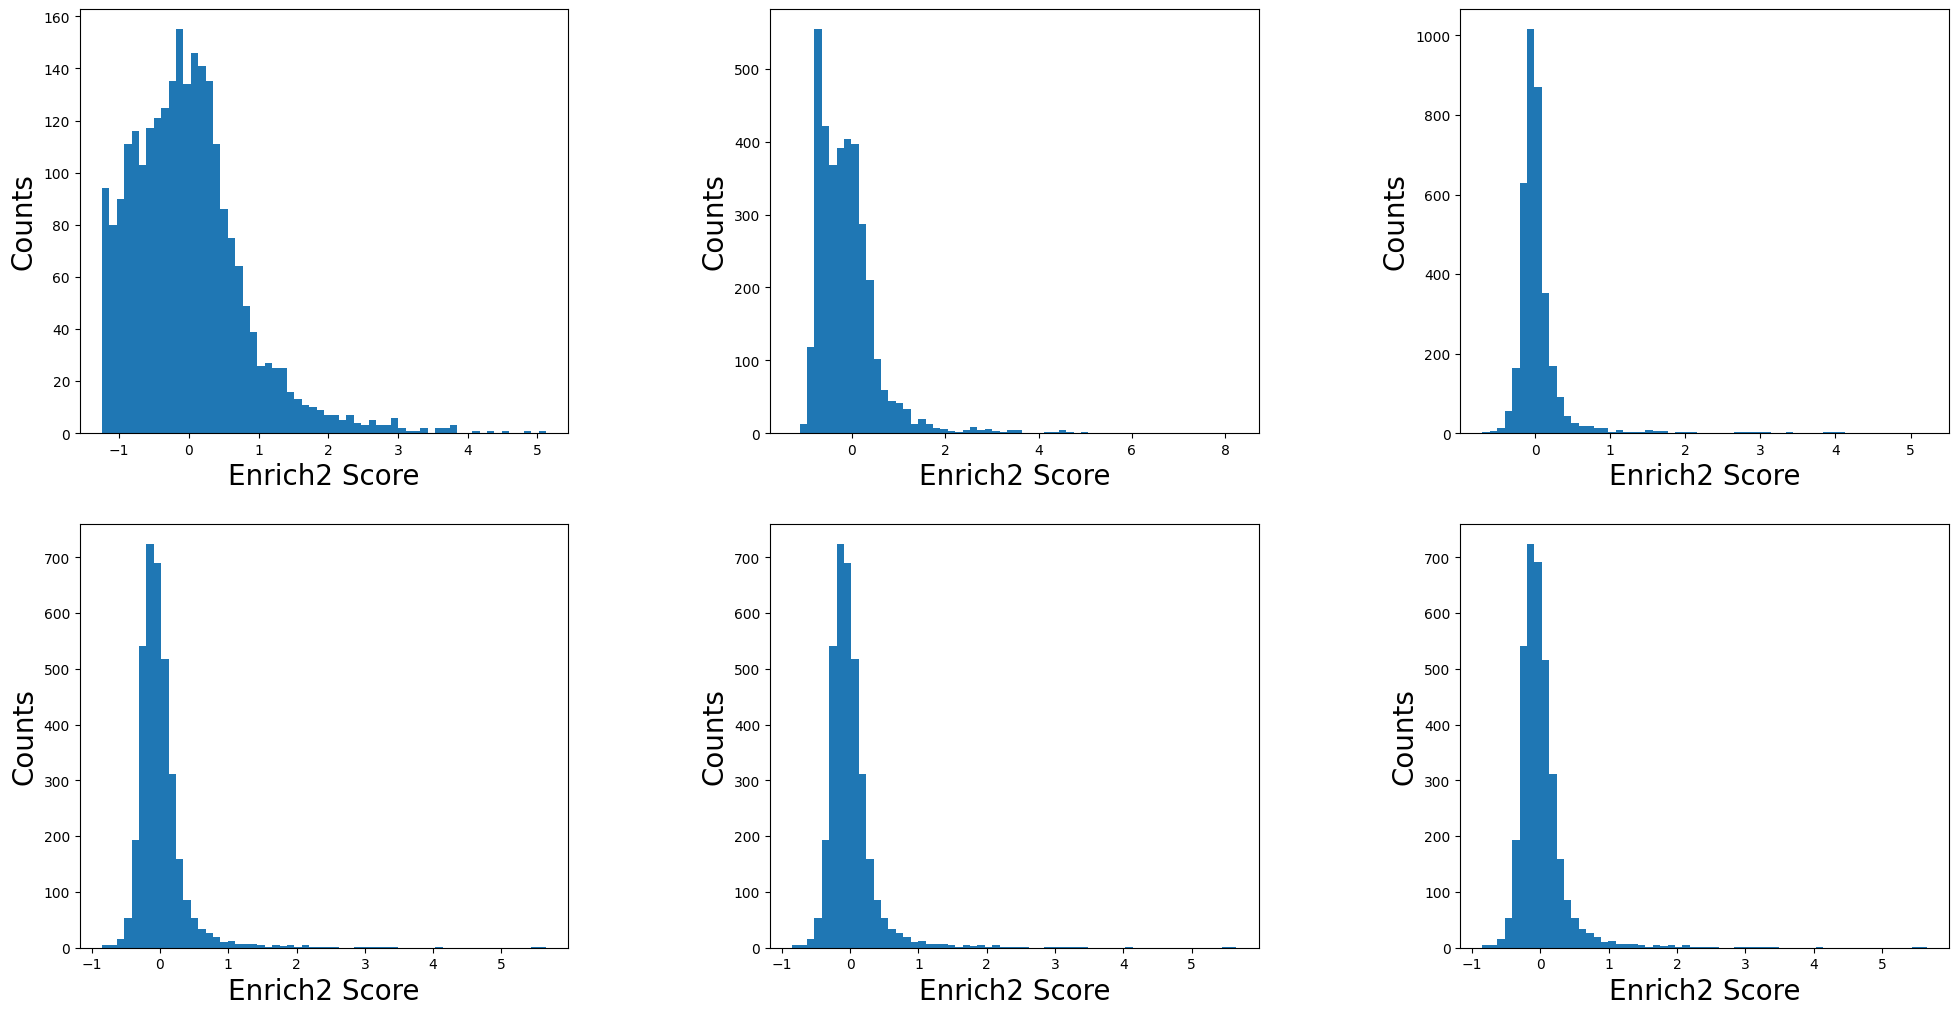

In [62]:
# Remove loss-of-function mutations and mutations with score under -1.25 from the control dataset
SRC_Ahler_control_dict = {key: SRC_Ahler_control_dict[key] for key in SRC_Ahler_control_dict 
                          if key[2] != "*" and SRC_Ahler_control_dict[key] > -1.25}
# Plot distributions
fig, axs = plt.subplots(2, 3)
datasets = [SRC_Ahler_control_dict, SRC_Chakraborty_Dis_25uM_dict, SRC_Chakraborty_Dis_100uM_dict,
            SRC_Chakraborty_I1_dict, SRC_Chakraborty_I2_dict, SRC_Chakraborty_I4_dict]
for i in range(len(datasets)):
    axs[i // 3, i % 3].hist(list(datasets[i].values()), bins=60)
    axs[i // 3, i % 3].set_xlabel("Enrich2 Score", size=20)
    axs[i // 3, i % 3].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

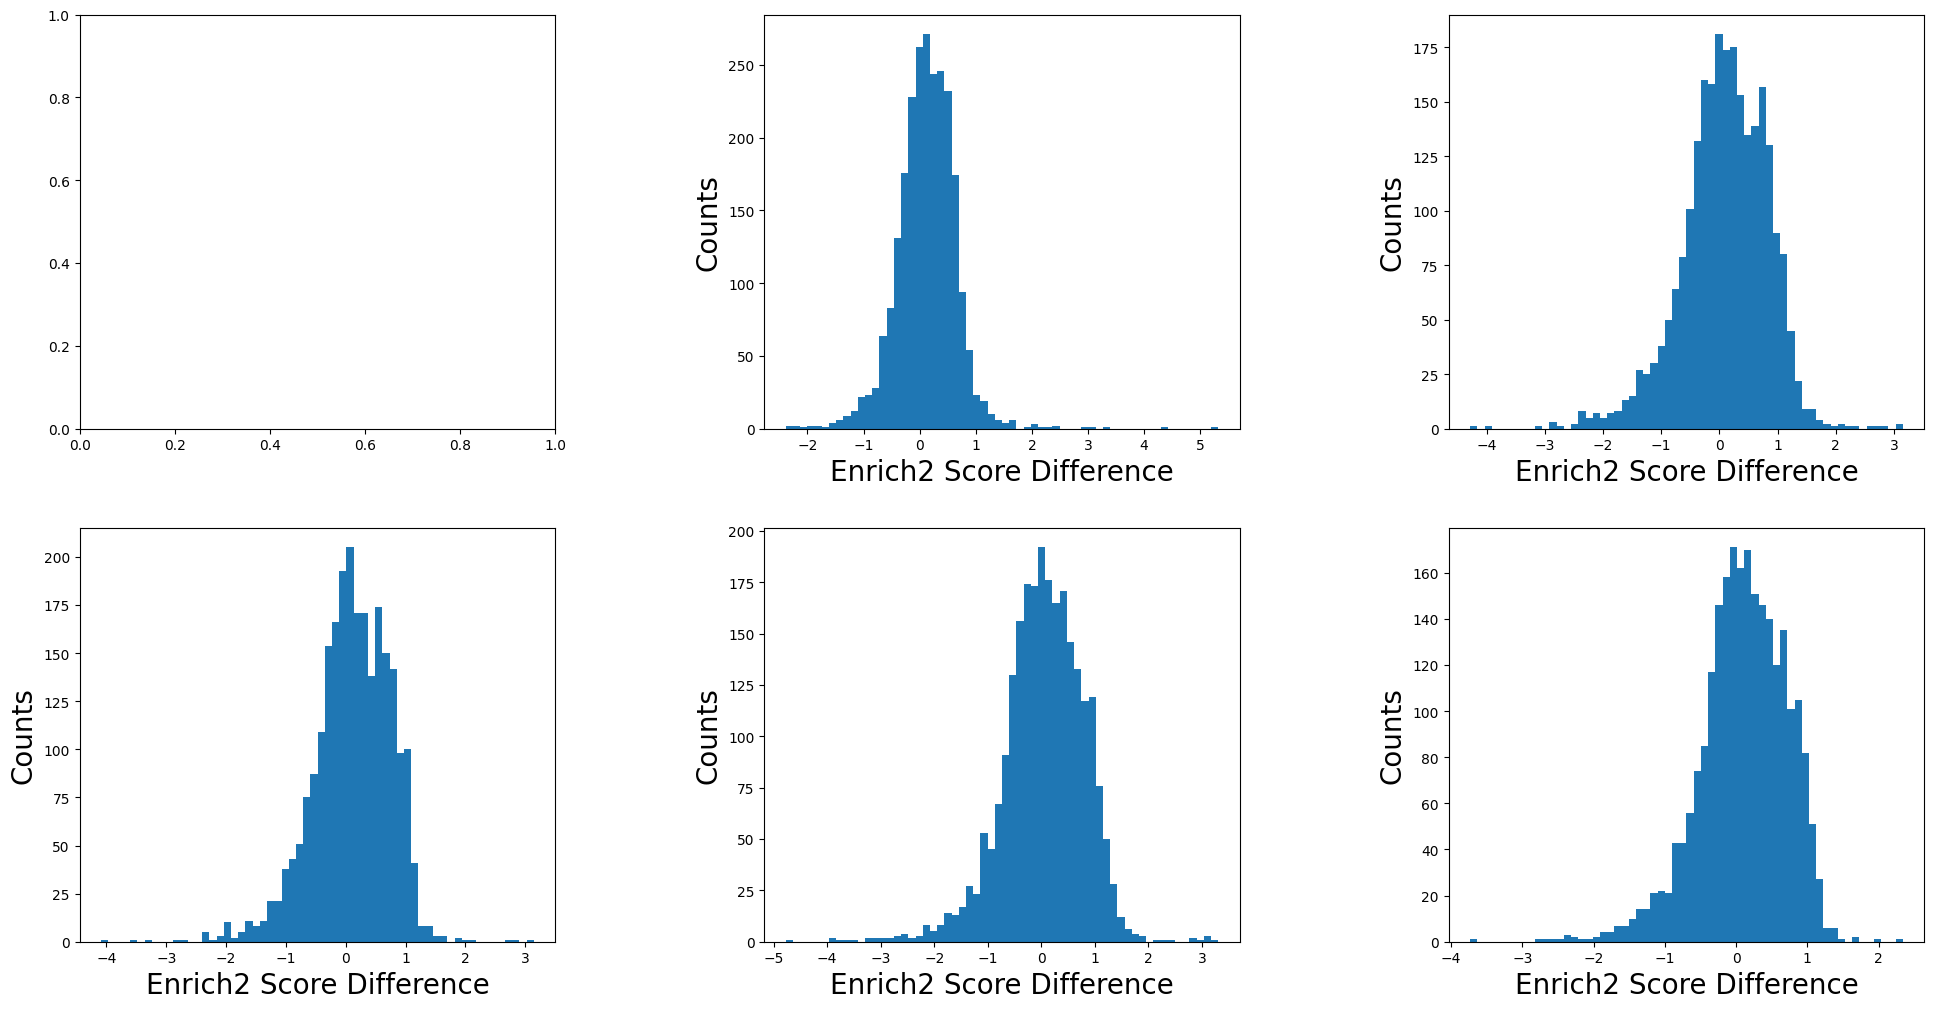

In [63]:
# Plot difference in Enrich2 score distribution under each treatment
score_differences = []
for i in range(1, len(datasets)):
    score_difference = {}
    for key in datasets[i]:
        if key in datasets[0]:
            score_difference[key] = datasets[i][key] - datasets[0][key]
    score_differences.append(score_difference)

fig, axs = plt.subplots(2, 3)
for i in range(1, len(datasets)):
    axs[i // 3, i % 3].hist(list(score_differences[i - 1].values()), bins=60)
    axs[i // 3, i % 3].set_xlabel("Enrich2 Score Difference", size=20)
    axs[i // 3, i % 3].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [64]:
# Save difference scores to output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
treatments = ["Dis_25uM", "Dis_100uM", "Inhib1_8uM", "Inhib2_2uM", "Inhib4_0.8uM"]
for treat_i in range(len(score_differences)):
    for wt, pos, mut in score_differences[treat_i]:
        prot_col.append("SRC")
        ligand_col.append(treatments[treat_i])
        wt_col.append(wt)
        pos_col.append(pos)
        mut_col.append(mut)
        score_col.append(score_differences[treat_i][(wt, pos, mut)])

write_formatted_data("SRC_Chakraborty_2024.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"))

In [65]:
# Save the tails of difference scores to another output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
treatments = ["Dis_25uM", "Dis_100uM", "Inhib1_8uM", "Inhib2_2uM", "Inhib4_0.8uM"]
for treat_i in range(len(score_differences)):
    treat_mean = np.mean(list(score_differences[treat_i].values()))
    treat_std = np.std(list(score_differences[treat_i].values()))
    print(f"Treatment {treat_i} mean, std: {treat_mean}, {treat_std}")
    
    for wt, pos, mut in score_differences[treat_i]:
        if np.abs(score_differences[treat_i][(wt, pos, mut)] - treat_mean) > treat_std:
            prot_col.append("SRC")
            ligand_col.append(treatments[treat_i])
            wt_col.append(wt)
            pos_col.append(pos)
            mut_col.append(mut)
            score_col.append(score_differences[treat_i][(wt, pos, mut)])

write_formatted_data("SRC_Chakraborty_2024_tail.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"),
                     directory=difference_tail_dir)

Treatment 0 mean, std: 0.124023797399348, 0.5326262295393531
Treatment 1 mean, std: 0.08966413977605862, 0.7407382071958026
Treatment 2 mean, std: 0.10625220568539787, 0.6556493876690287
Treatment 3 mean, std: 0.04199124051517639, 0.7752807627970528
Treatment 4 mean, std: 0.09943332940730107, 0.6144327128275668


## MET Estevam 2024

### MET WT

In [33]:
# Load relevant data from file
MET_Estevam_wt_rosace = load_raw_data("MET-Estevam-2024-WT-Rosace.tsv", (1, 2, 6), header=1,
                                   directory=raw_data_dir, sep="\t")

treatments = ["DMSO", "A458", "Crizo", "Camp", "Tepo", "Tiv", "Glu", "Savo", "NVP", "Cabo", "Mere", "Gle"]
treatments_dict = {treatments[i]: i for i in range(len(treatments))}
scores_by_treat = [{} for _ in range(len(treatments))]

for i in range(len(MET_Estevam_wt_rosace[0])):
    if MET_Estevam_wt_rosace[0][i] not in treatments_dict:
        raise Exception(f"Error: Unknown treatment {MET_Estevam_wt_rosace[0][i]}")
    scores = scores_by_treat[treatments_dict[MET_Estevam_wt_rosace[0][i]]]
    if (MET_Estevam_wt_rosace[1][i][3], MET_Estevam_wt_rosace[1][i][4:-2], MET_Estevam_wt_rosace[1][i][-2]) in scores:
        raise Exception(f"Error: Duplicate entry {(MET_Estevam_wt_rosace[1][i][3], MET_Estevam_wt_rosace[1][i][4:-2], MET_Estevam_wt_rosace[1][i][-2])}")
    scores[(MET_Estevam_wt_rosace[1][i][3], MET_Estevam_wt_rosace[1][i][4:-2], MET_Estevam_wt_rosace[1][i][-2])] = float(MET_Estevam_wt_rosace[2][i])

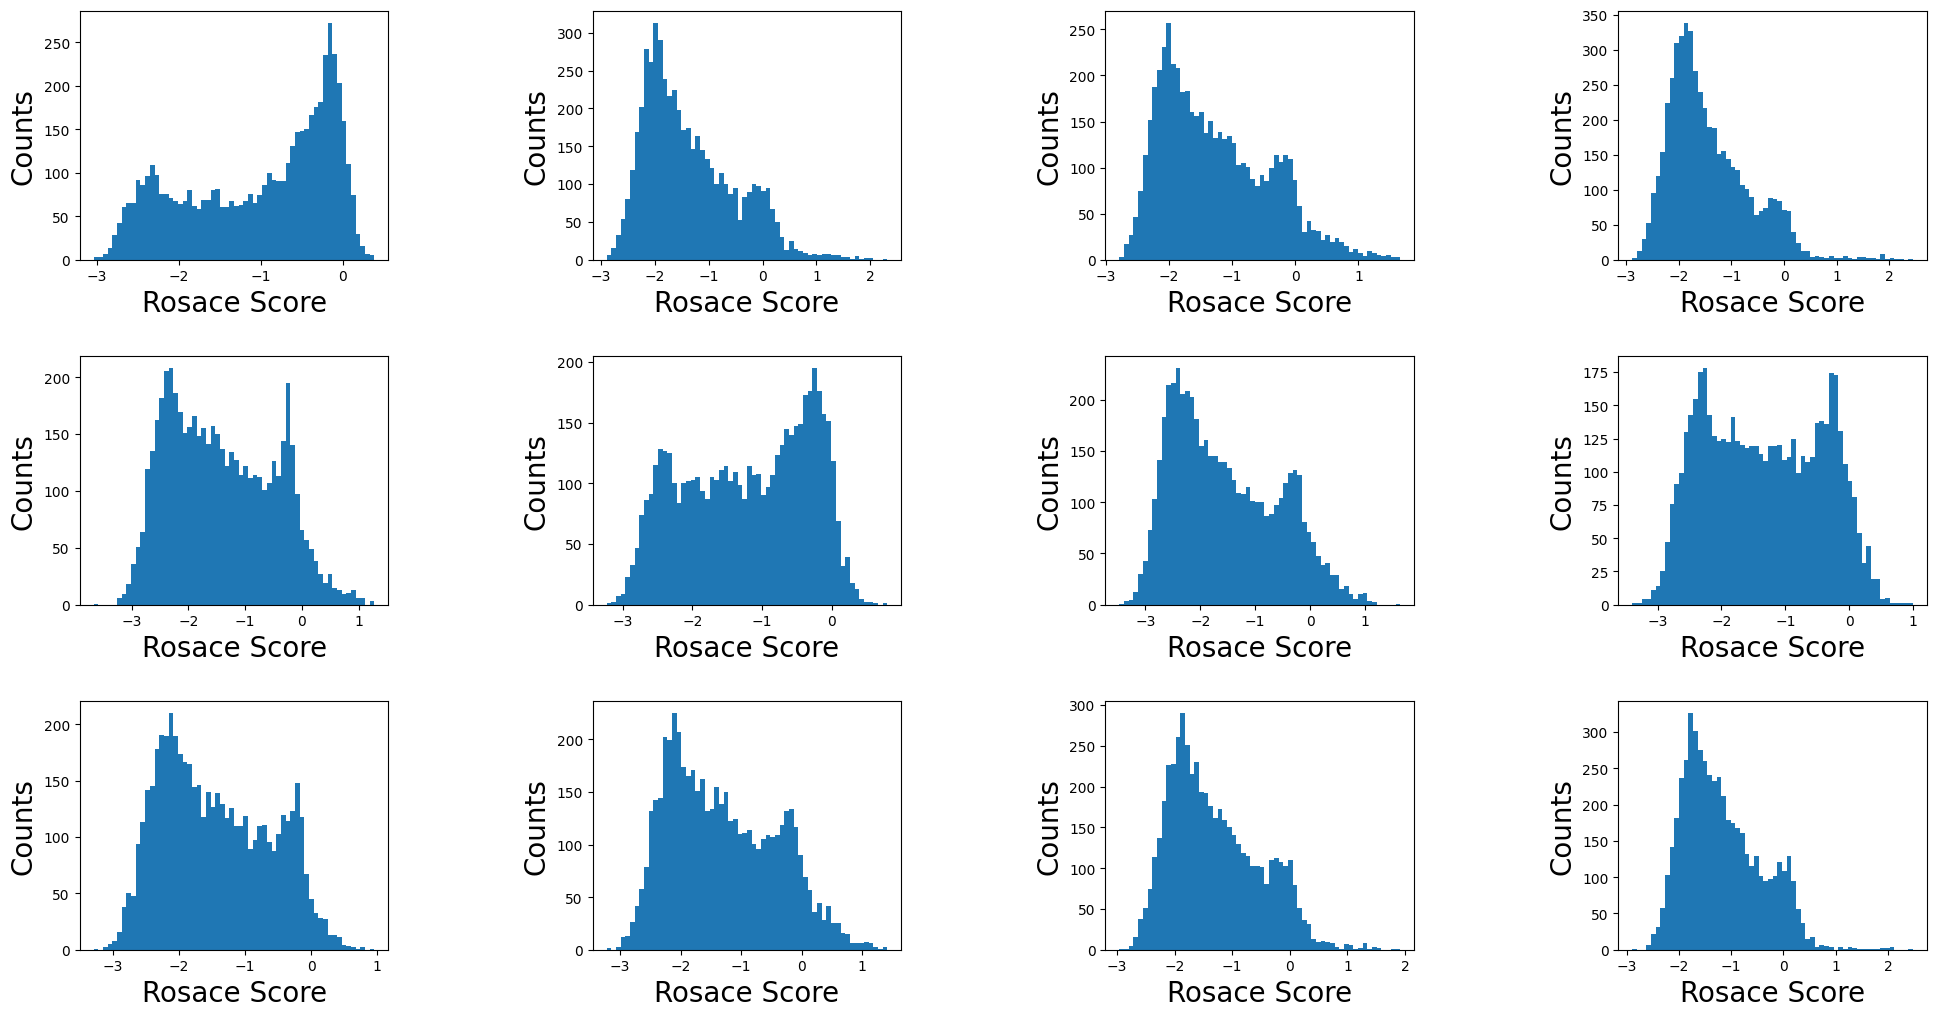

In [34]:
# Plot Rosace score distribution under each treatment
fig, axs = plt.subplots(3, 4)
for i in range(len(scores_by_treat)):
    axs[i // 4, i % 4].hist(list(scores_by_treat[i].values()), bins=60)
    axs[i // 4, i % 4].set_xlabel("Rosace Score", size=20)
    axs[i // 4, i % 4].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

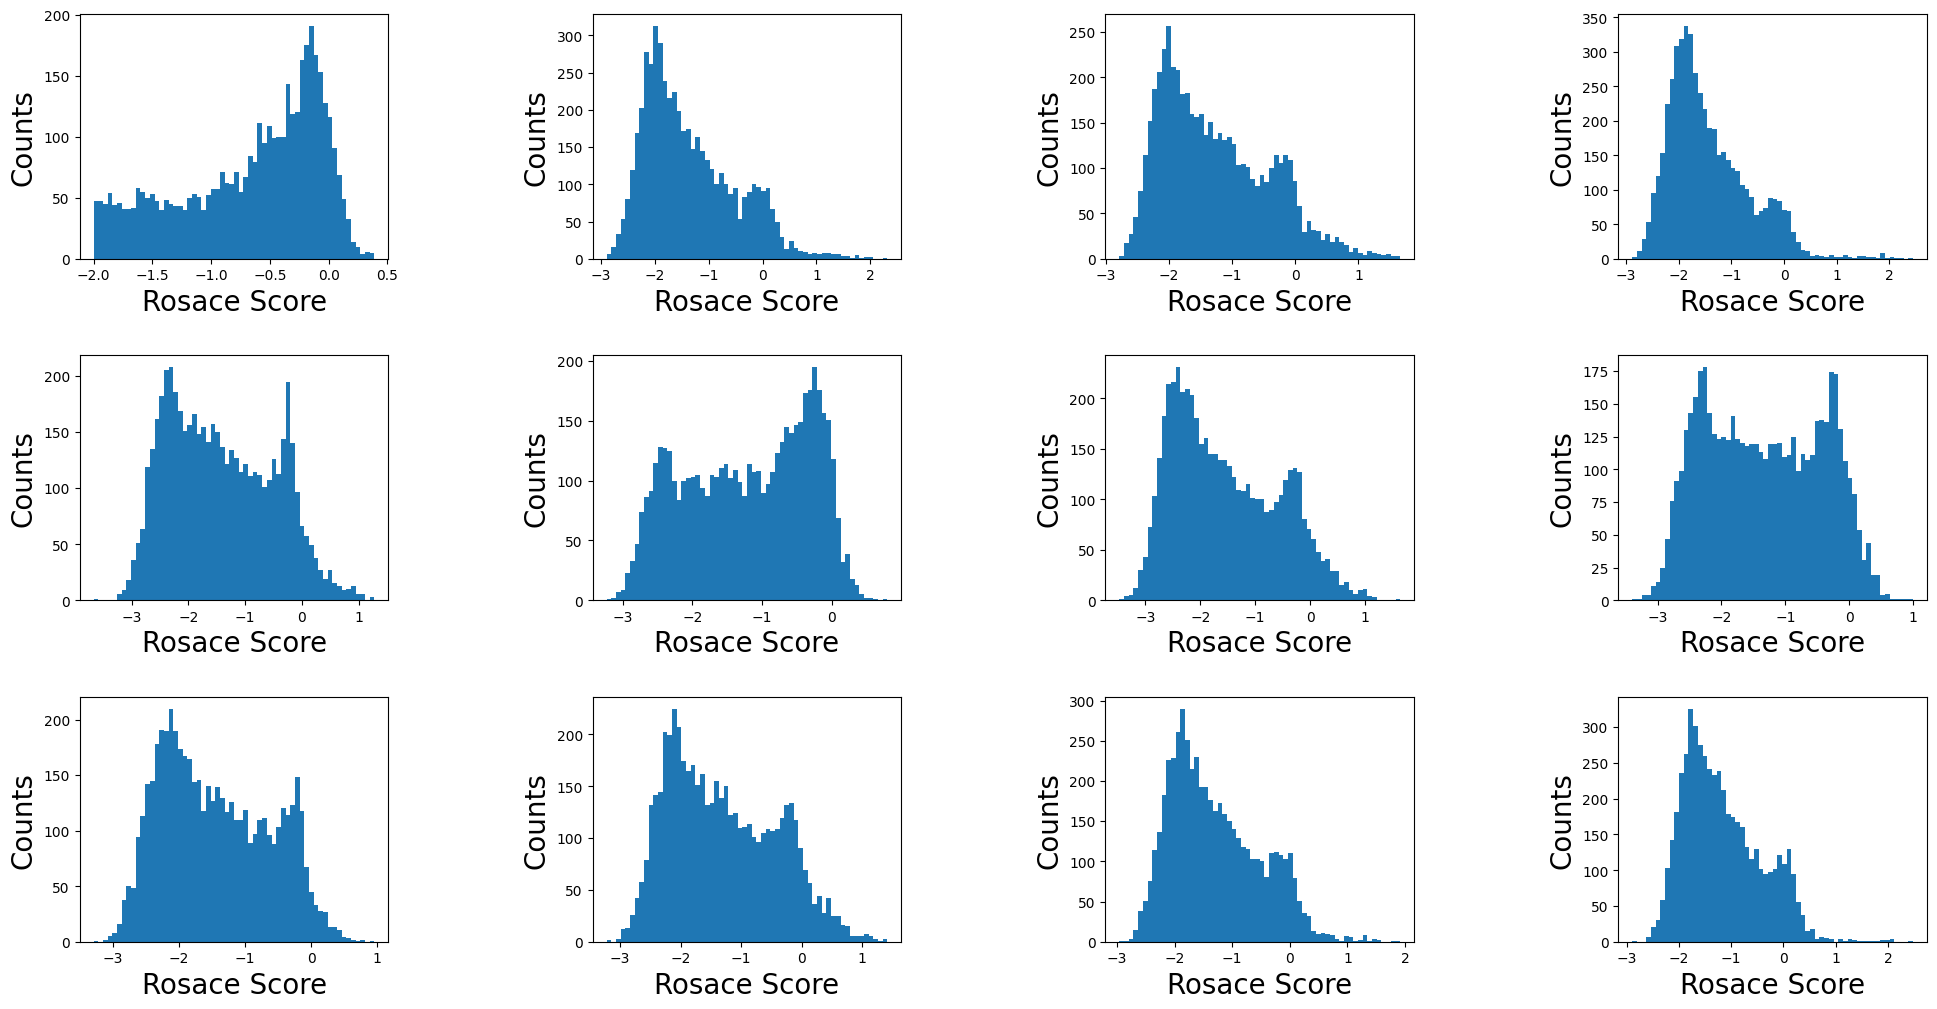

In [35]:
# Remove nonsense mutants and extreme LoF mutants with score < -2
scores_by_treat[0] = {key: scores_by_treat[0][key] for key in scores_by_treat[0] 
                      if key[2] != "X" and scores_by_treat[0][key] > -2}

fig, axs = plt.subplots(3, 4)
for i in range(len(scores_by_treat)):
    axs[i // 4, i % 4].hist(list(scores_by_treat[i].values()), bins=60)
    axs[i // 4, i % 4].set_xlabel("Rosace Score", size=20)
    axs[i // 4, i % 4].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

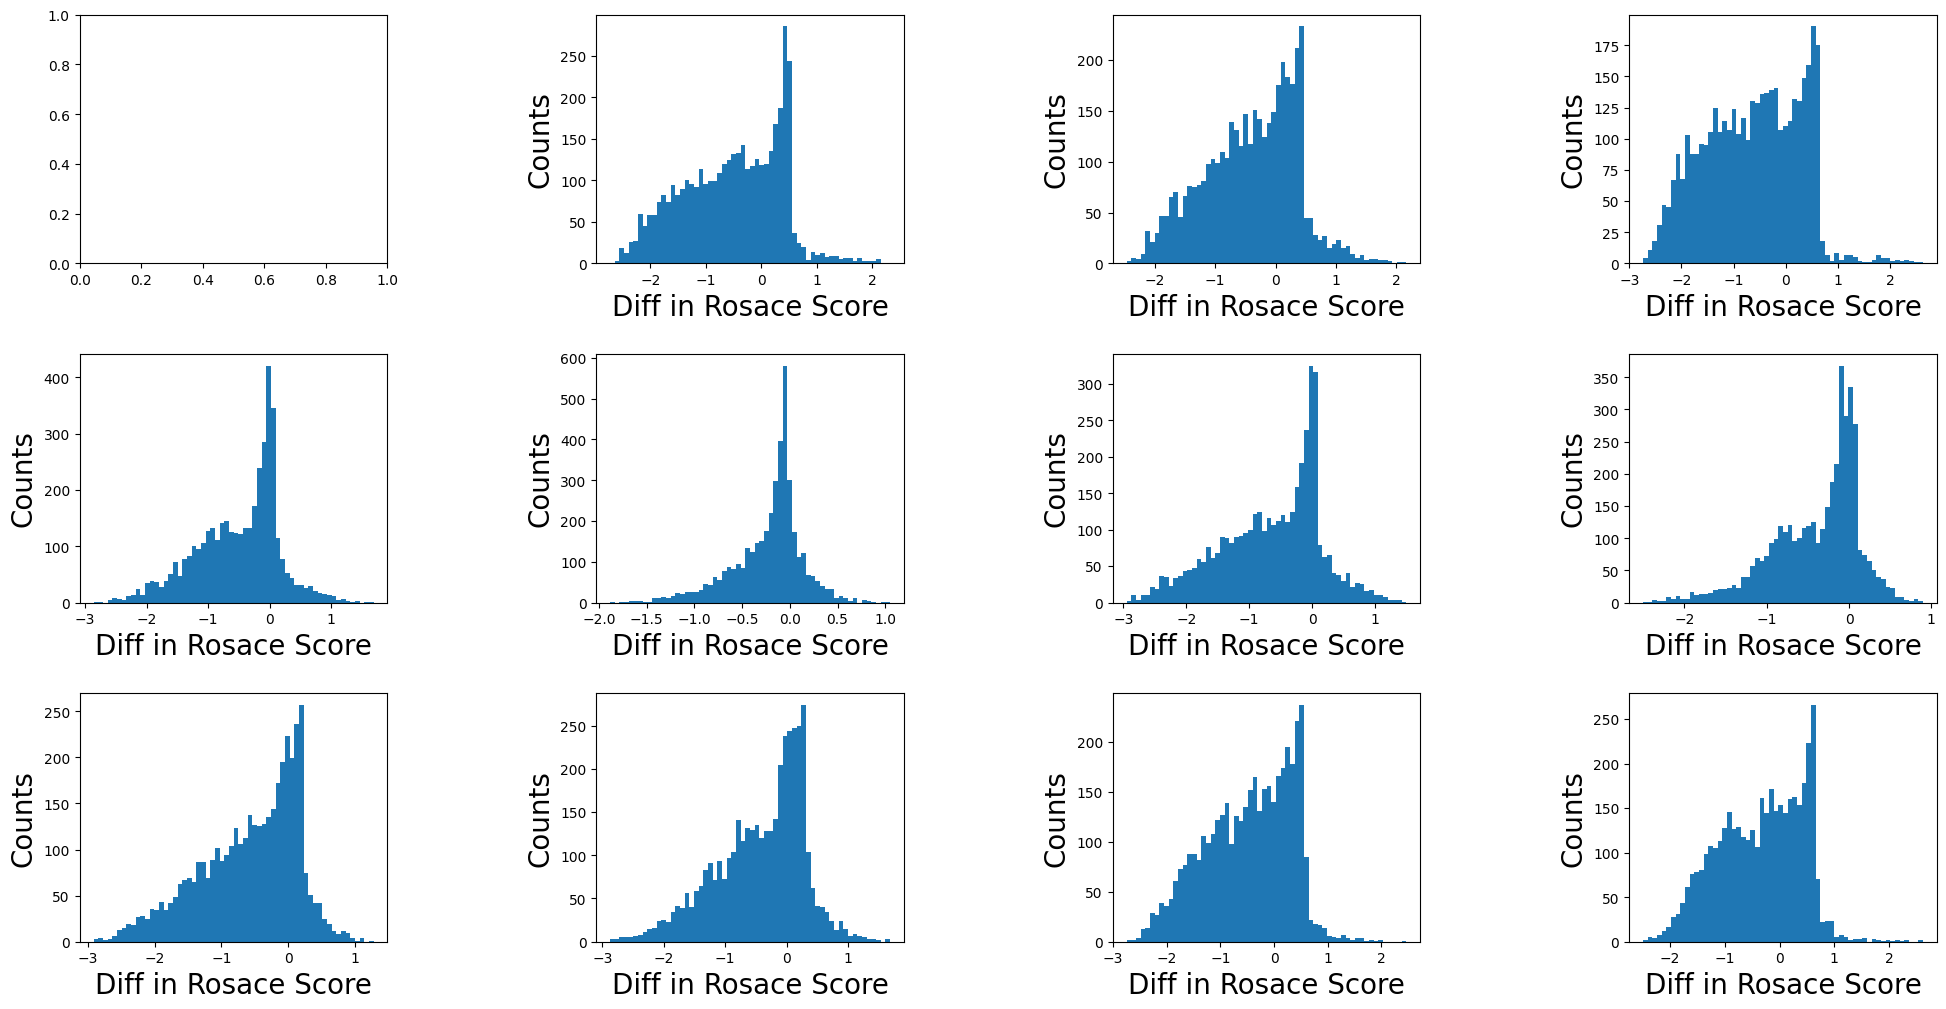

In [36]:
# Plot distribution in difference in Rosace scores from treatment to DMSO
scores_diff_by_treat = [{} for _ in range(len(scores_by_treat) - 1)]
for i in range(1, len(scores_by_treat)):
    for key in scores_by_treat[i]:
        if key in scores_by_treat[0]:
            scores_diff_by_treat[i - 1][key] = scores_by_treat[i][key] - scores_by_treat[0][key]

fig, axs = plt.subplots(3, 4)
for i in range(len(scores_by_treat)):
    if i > 0:
        axs[i // 4, i % 4].hist(list(scores_diff_by_treat[i - 1].values()), bins=60)
        axs[i // 4, i % 4].set_xlabel("Diff in Rosace Score", size=20)
        axs[i // 4, i % 4].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [41]:
# Save difference scores to output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
treatments = ["DMSO", "A458_534nM", "Crizo_21.9nM", "Camp_6.70nM", "Tepo_1.74nM", "Tiv_2.55uM", "Glu_31.3nM",
              "Savo_1.51nM", "NVP_45.1nM", "Cabo_71nM", "Mere_47.3nM", "Gle_324nM"]
for treat_i in range(len(scores_diff_by_treat)):
    for wt, pos, mut in scores_diff_by_treat[treat_i]:
        prot_col.append("MET_WT")
        ligand_col.append(treatments[treat_i + 1])
        wt_col.append(wt)
        pos_col.append(str(int(pos) + 1058))
        mut_col.append(mut)
        score_col.append(scores_diff_by_treat[treat_i][(wt, pos, mut)])

write_formatted_data("MET_Estevam_2024_WT.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"))

In [42]:
# Save the tails of difference scores to another output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
treatments = ["DMSO", "A458_534nM", "Crizo_21.9nM", "Camp_6.70nM", "Tepo_1.74nM", "Tiv_2.55uM", "Glu_31.3nM",
              "Savo_1.51nM", "NVP_45.1nM", "Cabo_71nM", "Mere_47.3nM", "Gle_324nM"]
for treat_i in range(len(scores_diff_by_treat)):
    treat_mean = np.mean(list(scores_diff_by_treat[treat_i].values()))
    treat_std = np.std(list(scores_diff_by_treat[treat_i].values()))
    print(f"Treatment {treat_i} mean, std: {treat_mean}, {treat_std}")
    
    for wt, pos, mut in scores_diff_by_treat[treat_i]:
        if np.abs(scores_diff_by_treat[treat_i][(wt, pos, mut)] - treat_mean) > treat_std:
            prot_col.append("MET_WT")
            ligand_col.append(treatments[treat_i + 1])
            wt_col.append(wt)
            pos_col.append(str(int(pos) + 1058))
            mut_col.append(mut)
            score_col.append(scores_diff_by_treat[treat_i][(wt, pos, mut)])

write_formatted_data("MET_Estevam_2024_WT_tail.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"),
                     directory=difference_tail_dir)

Treatment 0 mean, std: -0.5117112824443358, 0.8826111340715465
Treatment 1 mean, std: -0.39862757812145017, 0.7629868109071
Treatment 2 mean, std: -0.6305360926979506, 0.9157187328982789
Treatment 3 mean, std: -0.4975822481727505, 0.6739641385997509
Treatment 4 mean, std: -0.22128351940631208, 0.36927320900379845
Treatment 5 mean, std: -0.6364159677534513, 0.7979330351372953
Treatment 6 mean, std: -0.3906211628364212, 0.530875784553936
Treatment 7 mean, std: -0.5787476685202854, 0.7359880280929365
Treatment 8 mean, std: -0.41312810582671344, 0.722563927594021
Treatment 9 mean, std: -0.471018815413739, 0.8056957577753404
Treatment 10 mean, std: -0.34076974910439034, 0.7708941153988424


## MET delEx14

In [57]:
# Load relevant data from file
MET_Estevam_dEx14_rosace = load_raw_data("MET-Estevam-2024-dEx14-Rosace.tsv", (1, 2, 6), header=1,
                                   directory=raw_data_dir, sep="\t")

treatments = ["DMSO", "A458", "Crizo", "Camp", "Tepo", "Tiv", "Glu", "Savo", "NVP", "Cabo", "Mere", "Gle"]
treatments_dict = {treatments[i]: i for i in range(len(treatments))}
scores_by_treat = [{} for _ in range(len(treatments))]

for i in range(len(MET_Estevam_dEx14_rosace[0])):
    if MET_Estevam_dEx14_rosace[0][i] not in treatments_dict:
        raise Exception(f"Error: Unknown treatment {MET_Estevam_dEx14_rosace[0][i]}")
    scores = scores_by_treat[treatments_dict[MET_Estevam_dEx14_rosace[0][i]]]
    if (MET_Estevam_dEx14_rosace[1][i][3], MET_Estevam_dEx14_rosace[1][i][4:-2], MET_Estevam_dEx14_rosace[1][i][-2]) in scores:
        raise Exception(f"Error: Duplicate entry {(MET_Estevam_dEx14_rosace[1][i][3], MET_Estevam_dEx14_rosace[1][i][4:-2], MET_Estevam_dEx14_rosace[1][i][-2])}")
    scores[(MET_Estevam_dEx14_rosace[1][i][3], MET_Estevam_dEx14_rosace[1][i][4:-2], MET_Estevam_dEx14_rosace[1][i][-2])] = float(MET_Estevam_dEx14_rosace[2][i])

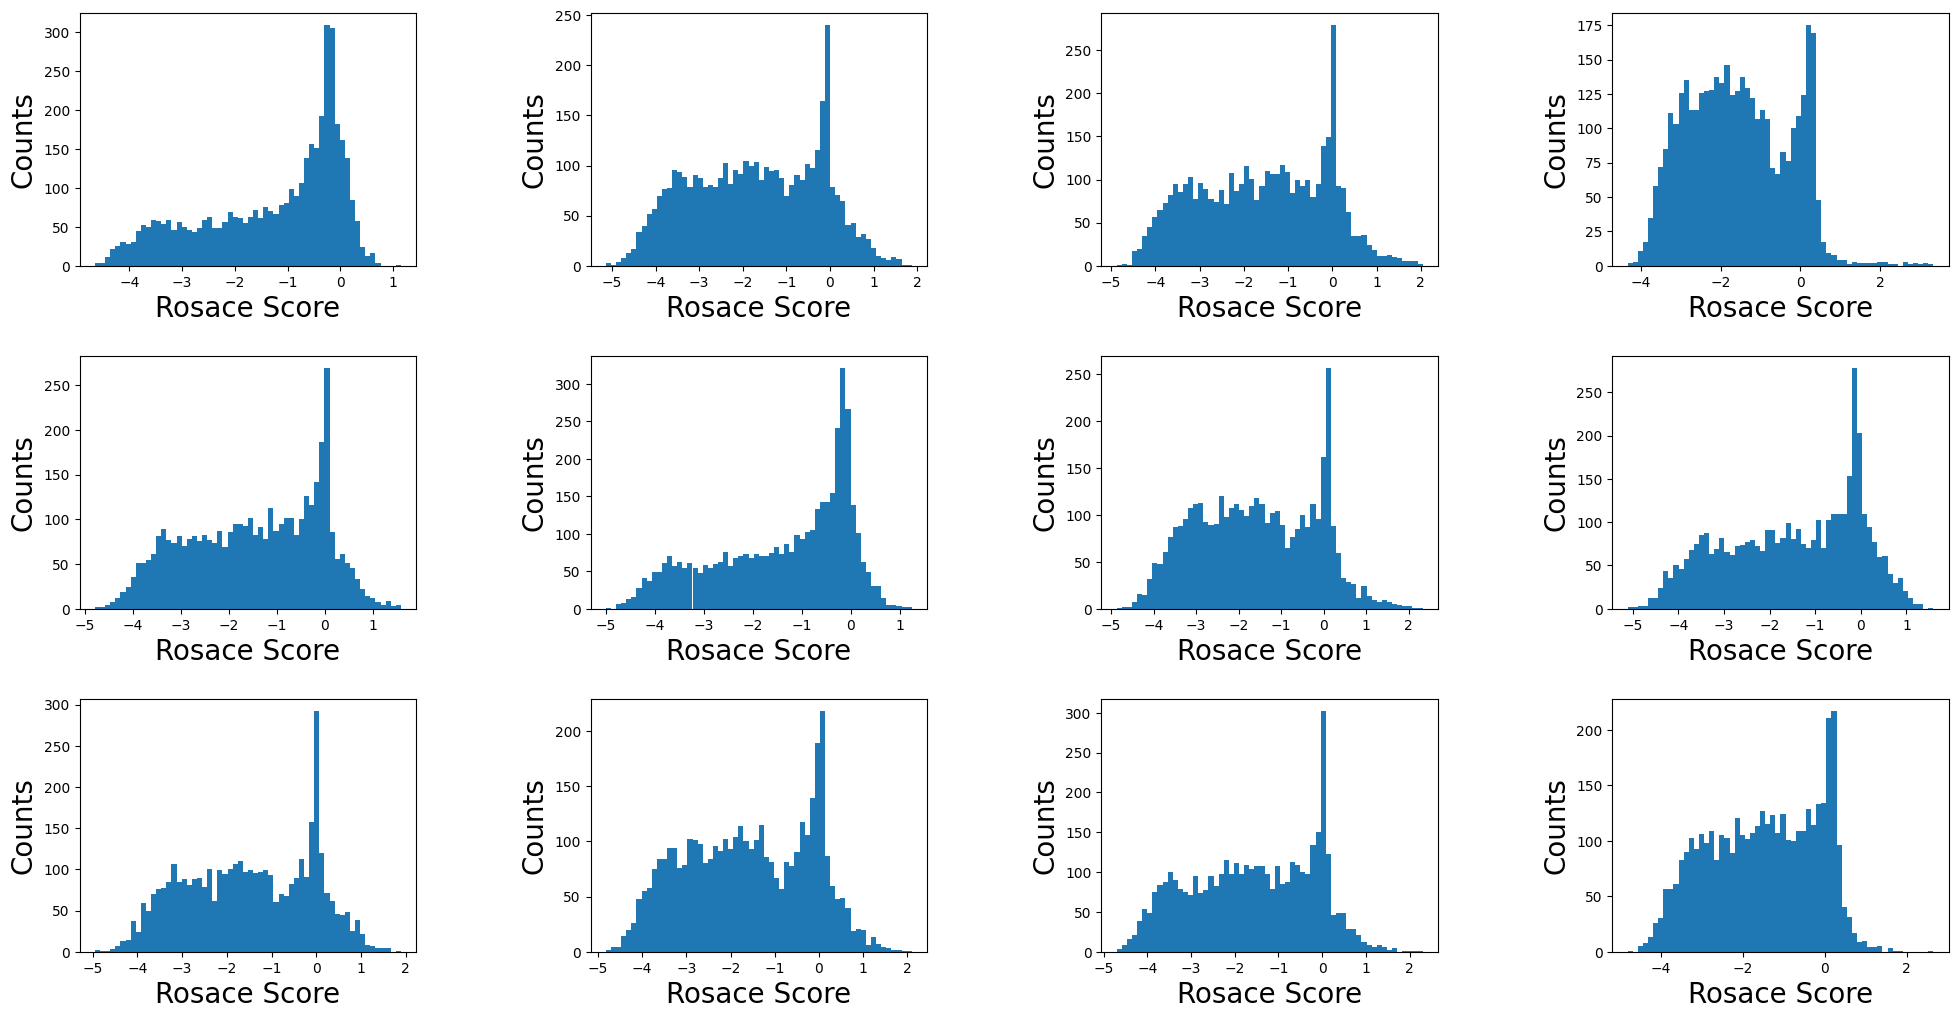

In [58]:
# Plot Rosace score distribution under each treatment
fig, axs = plt.subplots(3, 4)
for i in range(len(scores_by_treat)):
    axs[i // 4, i % 4].hist(list(scores_by_treat[i].values()), bins=60)
    axs[i // 4, i % 4].set_xlabel("Rosace Score", size=20)
    axs[i // 4, i % 4].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

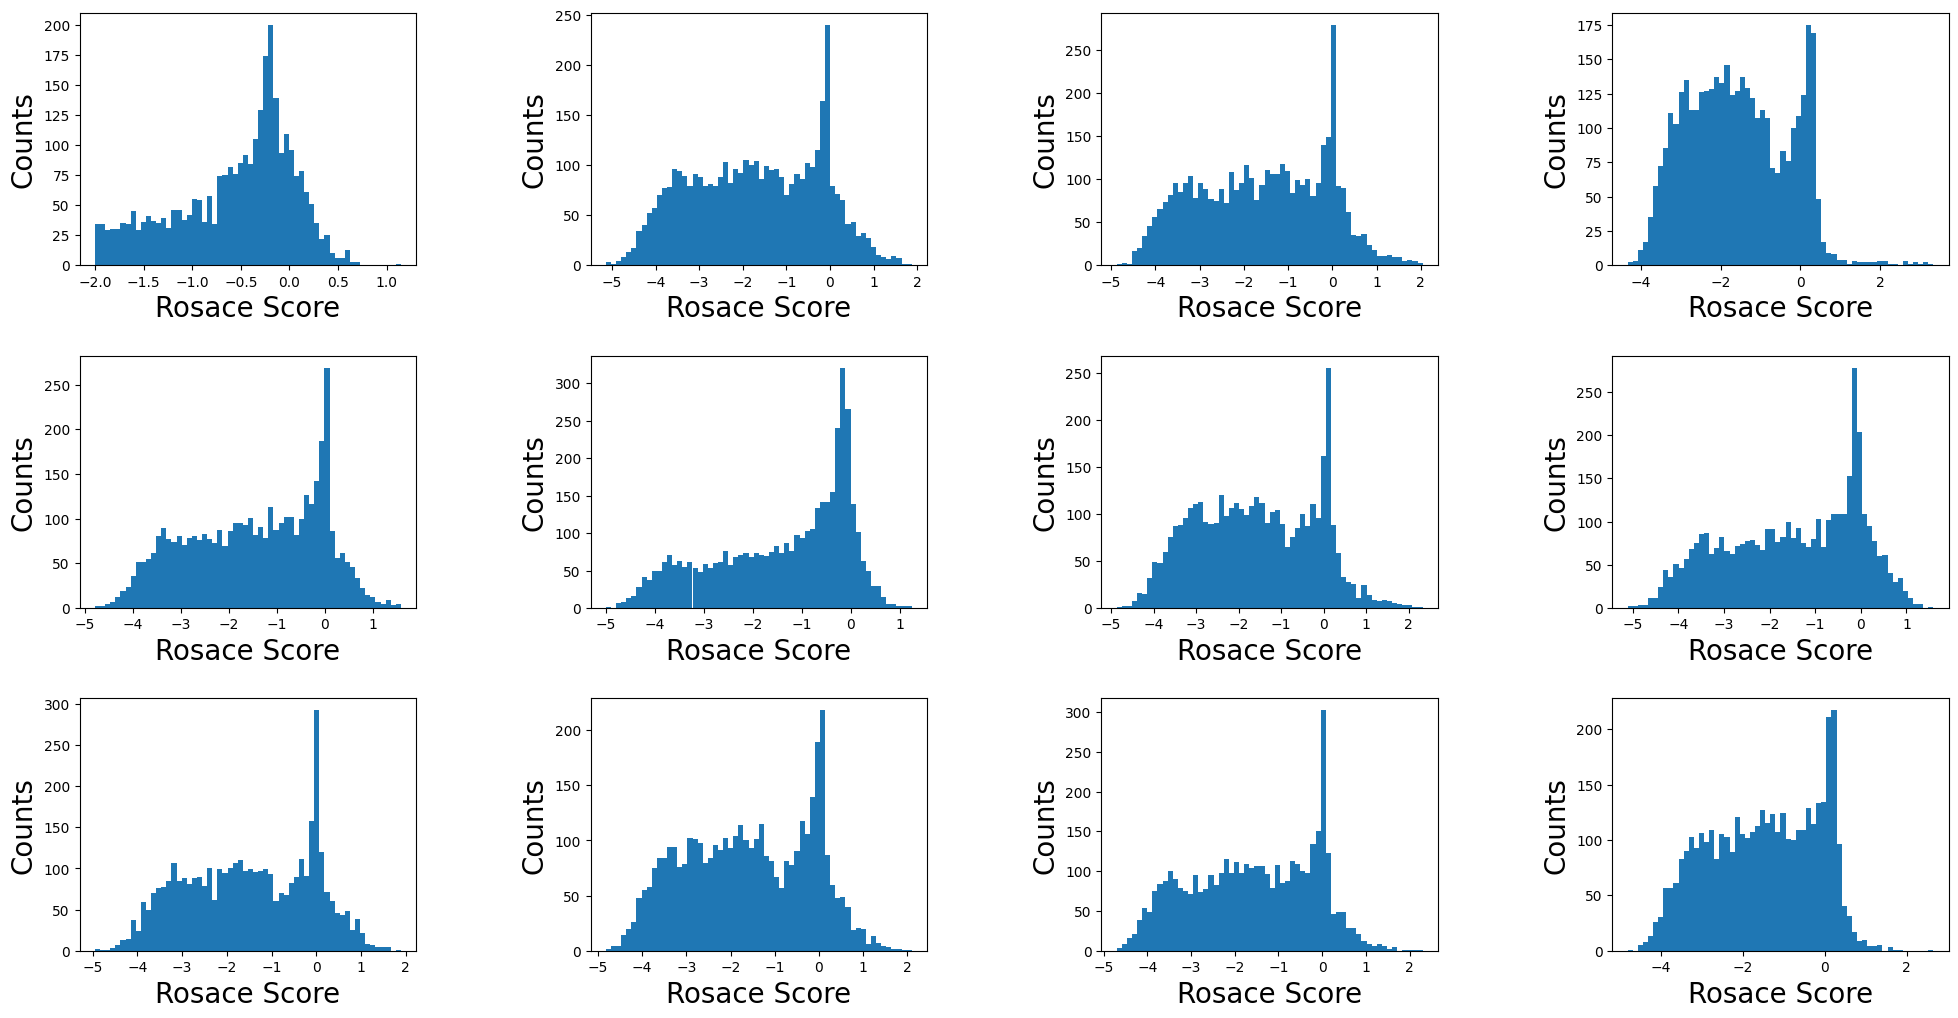

In [59]:
# Remove nonsense mutants and extreme LoF mutants with score < -2
scores_by_treat[0] = {key: scores_by_treat[0][key] for key in scores_by_treat[0] 
                      if key[2] != "X" and scores_by_treat[0][key] > -2}

fig, axs = plt.subplots(3, 4)
for i in range(len(scores_by_treat)):
    axs[i // 4, i % 4].hist(list(scores_by_treat[i].values()), bins=60)
    axs[i // 4, i % 4].set_xlabel("Rosace Score", size=20)
    axs[i // 4, i % 4].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

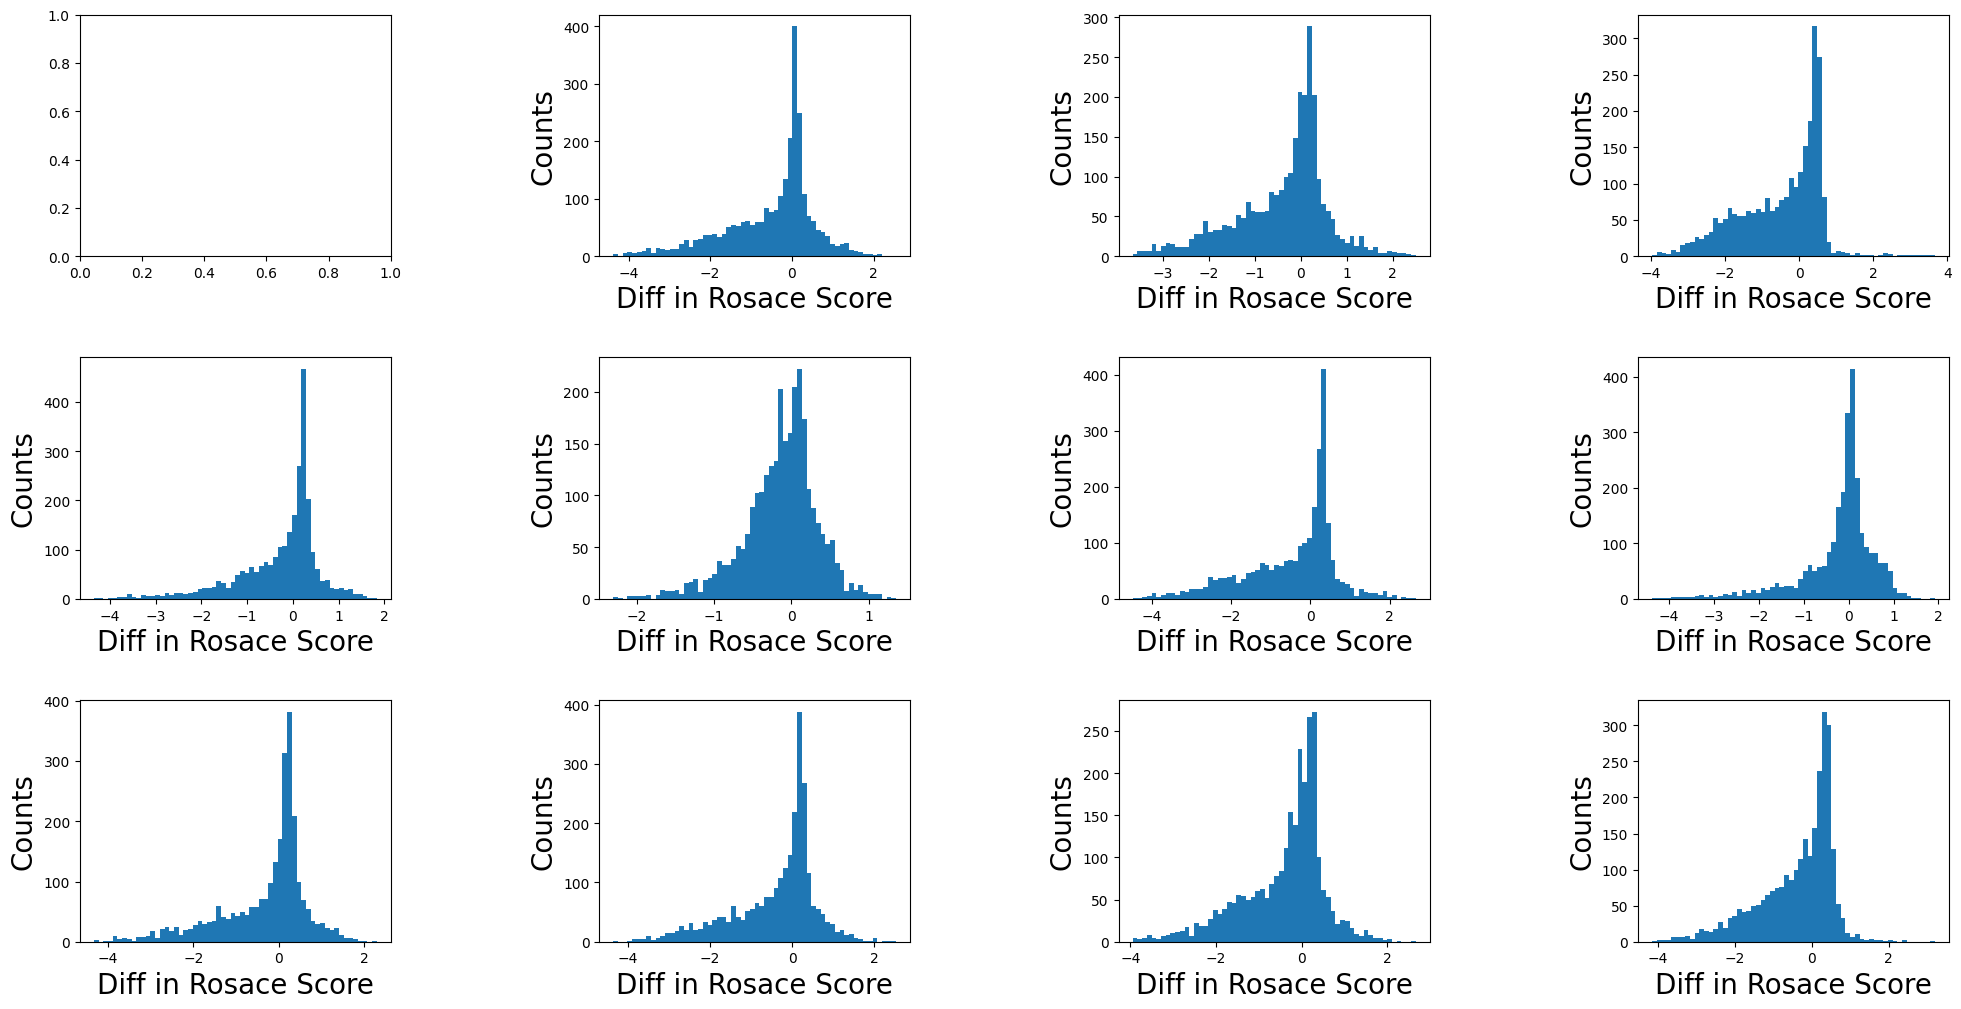

In [60]:
# Plot distribution in difference in Rosace scores from treatment to DMSO
scores_diff_by_treat = [{} for _ in range(len(scores_by_treat) - 1)]
for i in range(1, len(scores_by_treat)):
    for key in scores_by_treat[i]:
        if key in scores_by_treat[0]:
            scores_diff_by_treat[i - 1][key] = scores_by_treat[i][key] - scores_by_treat[0][key]

fig, axs = plt.subplots(3, 4)
for i in range(len(scores_by_treat)):
    if i > 0:
        axs[i // 4, i % 4].hist(list(scores_diff_by_treat[i - 1].values()), bins=60)
        axs[i // 4, i % 4].set_xlabel("Diff in Rosace Score", size=20)
        axs[i // 4, i % 4].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [61]:
# Save difference scores to output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
treatments = ["DMSO", "A458_534nM", "Crizo_21.9nM", "Camp_6.70nM", "Tepo_1.74nM", "Tiv_2.55uM", "Glu_31.3nM",
              "Savo_1.51nM", "NVP_45.1nM", "Cabo_71nM", "Mere_47.3nM", "Gle_324nM"]
for treat_i in range(len(scores_diff_by_treat)):
    for wt, pos, mut in scores_diff_by_treat[treat_i]:
        key = (wt, pos, mut)
        prot_col.append("MET_dEx14")
        ligand_col.append(treatments[treat_i + 1])
        wt_col.append(wt)
        pos = int(pos) + 1058
        if pos >= 956:
            if pos <= 1010:
                raise Exception(f"Position {pos} in MET_dEx14")
            pos -= 55
        pos_col.append(str(pos))
        mut_col.append(mut)
        score_col.append(scores_diff_by_treat[treat_i][key])

write_formatted_data("MET_Estevam_2024_dEx14.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"))

In [62]:
# Save difference scores to output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
treatments = ["DMSO", "A458_534nM", "Crizo_21.9nM", "Camp_6.70nM", "Tepo_1.74nM", "Tiv_2.55uM", "Glu_31.3nM",
              "Savo_1.51nM", "NVP_45.1nM", "Cabo_71nM", "Mere_47.3nM", "Gle_324nM"]
for treat_i in range(len(scores_diff_by_treat)):
    treat_mean = np.mean(list(scores_diff_by_treat[treat_i].values()))
    treat_std = np.std(list(scores_diff_by_treat[treat_i].values()))
    print(f"Treatment {treat_i} mean, std: {treat_mean}, {treat_std}")
    
    for wt, pos, mut in scores_diff_by_treat[treat_i]:
        if np.abs(scores_diff_by_treat[treat_i][(wt, pos, mut)] - treat_mean) > treat_std:
            key = (wt, pos, mut)
            prot_col.append("MET_dEx14")
            ligand_col.append(treatments[treat_i + 1])
            wt_col.append(wt)
            pos = int(pos) + 1058
            if pos >= 956:
                if pos <= 1010:
                    raise Exception(f"Position {pos} in MET_dEx14")
                pos -= 55
            pos_col.append(str(pos))
            mut_col.append(mut)
            score_col.append(scores_diff_by_treat[treat_i][key])

write_formatted_data("MET_Estevam_2024_dEx14_tail.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"), 
                     directory=difference_tail_dir)

Treatment 0 mean, std: -0.4894918336027677, 1.0893873713382365
Treatment 1 mean, std: -0.3825099268278228, 1.0086266119669276
Treatment 2 mean, std: -0.47929070776837196, 1.122306974800069
Treatment 3 mean, std: -0.275829490311375, 0.9129984601205594
Treatment 4 mean, std: -0.14664732369914985, 0.49200201057728904
Treatment 5 mean, std: -0.45746190147594057, 1.1600852738413903
Treatment 6 mean, std: -0.22257874679329348, 0.8462940728758191
Treatment 7 mean, std: -0.3113342681701197, 1.028046184045332
Treatment 8 mean, std: -0.39553067324558394, 1.026100322545304
Treatment 9 mean, std: -0.40030793446636953, 0.9708652651072357
Treatment 10 mean, std: -0.37321052069306404, 0.972649164873669


## EGFR An 2022 - You probably don't need to run this

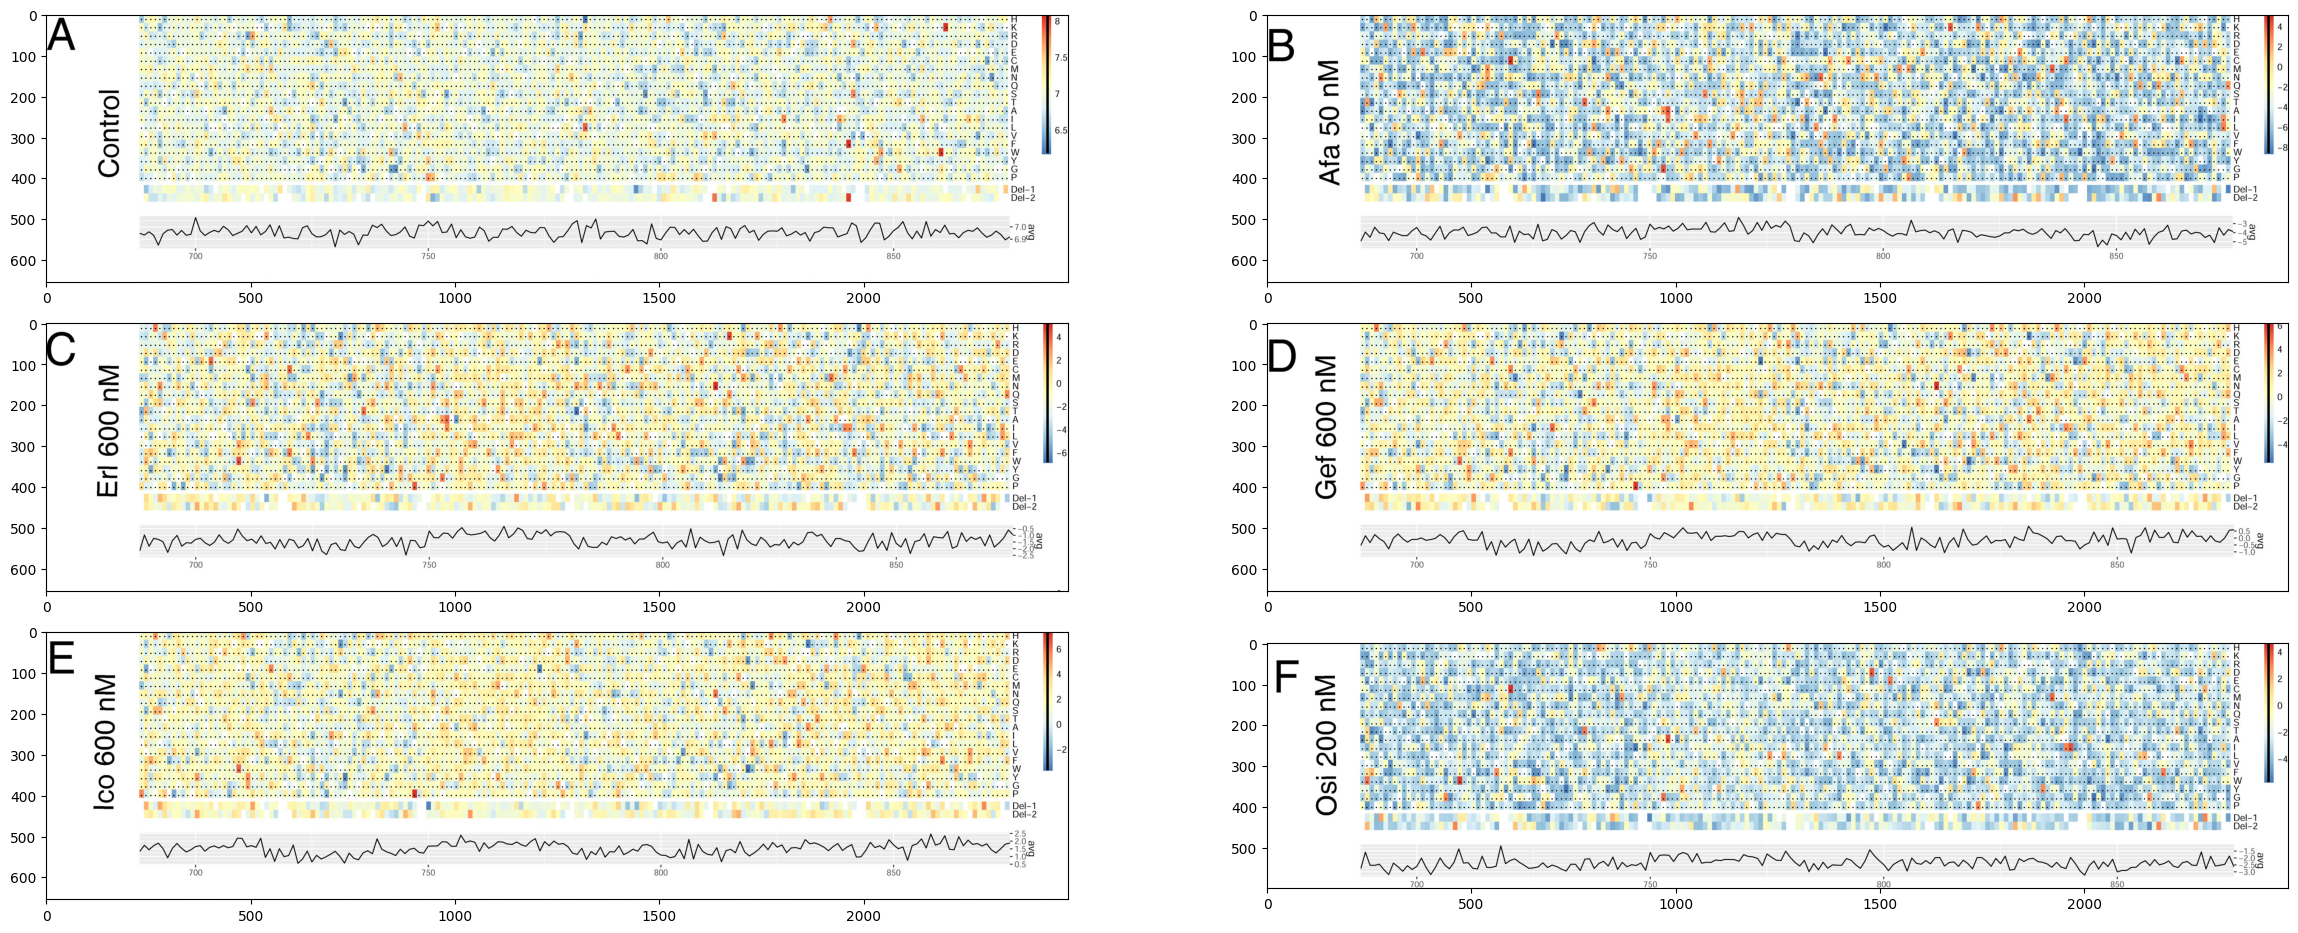

In [23]:
fig3 = np.array(Image.open(raw_data_dir / "EGFR-An-2022.jpg"))
# 645 evenly divides
fig3_panels = [np.array(fig3[(654 * i):(654 * (i+1)), :, :], dtype=np.float64) / 255.0 for i in range(6)]
fig3_panels_annotated = [np.array(fig3[(654 * i):(654 * (i+1)), :, :], dtype=np.float64) / 255.0 for i in range(6)]


# Check positions of heatmap cells
for panel in fig3_panels_annotated:
    for row in range(20):
        for col in range(188):
            for x_shift in range(-1, 2):
                for y_shift in range(-1, 2):
                    for channel in range(3):
                        panel[round(13 + 20.4 * row + x_shift), round(233 + 11.32 * col + y_shift), channel] = 0

# Check labelling of color bar
for panel in fig3_panels_annotated:
    for row in range(2, 340):
        for col in range(2447, 2453):
            for channel in range(3):
                panel[row, col, channel] = 0

# Code used to test pixel locations in the control panel heatmap legend
# for col in range(2447, 2453):
#    for channel in range(3):
#         fig3c_panels_annotated[0][283, col, channel] = 1.0

fig, axs = plt.subplots(3, 2)
for i in range(6):
    axs[i // 2, i % 2].imshow(fig3_panels_annotated[i])

fig.tight_layout()
fig.set_figwidth(25)
fig.set_figheight(10)

# plt.imsave(raw_data_dir / "panel.png", fig3c_panels_annotated[0])

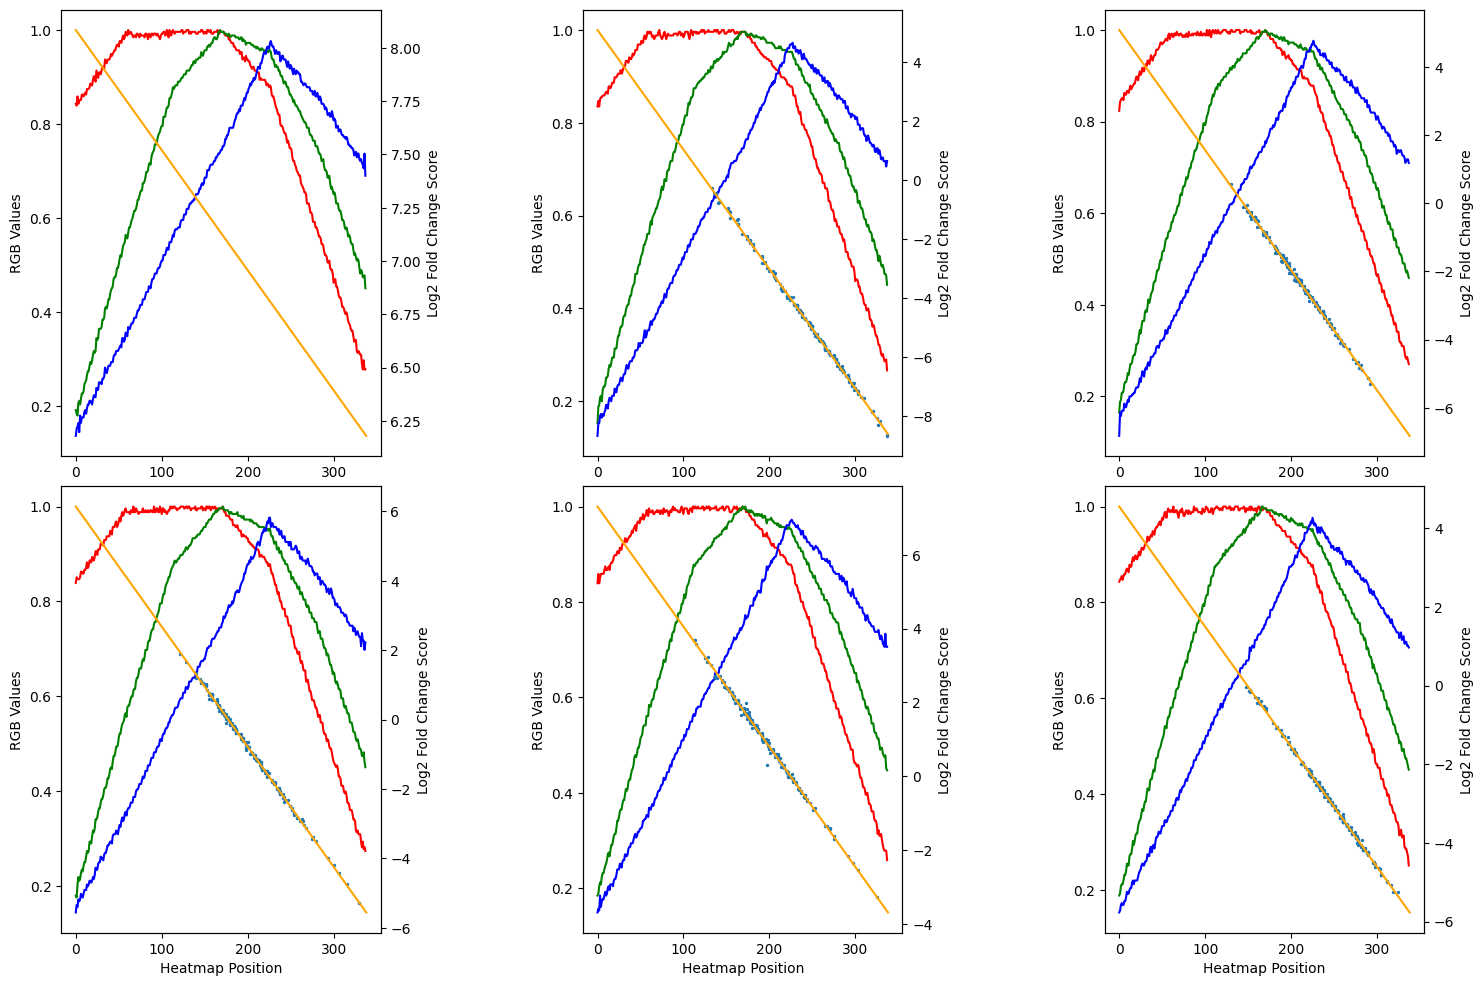

In [24]:
row_aas = ['H', 'K', 'R', 'D', 'E', 'C', 'M', 'N', 'Q', 'S', 'T', 'A', 'I', 'L', 'V', 'F', 'W', 'Y', 'G', 'P']
aas_to_row = {aa: row for row, aa in enumerate(row_aas)}
egfr_an_sup = load_raw_data("EGFR-An-2022-SupTab5.csv", (0, 1, 2, 3, 4, 5, 6), header=1)

egfr_an_mutations = [(int(egfr_an_sup[0][i]) - 688, aas_to_row[egfr_an_sup[1][i]]) for i in range(len(egfr_an_sup))]
egfr_an_mutation_scores_all_panel = []
egfr_an_mutation_heatmap_i_all_panel = []
for panel_i, panel in enumerate(fig3_panels[1:]):
    egfr_an_mutation_scores = []
    egfr_an_mutation_heatmap_i = []
    heatmap_colors = panel[2:340, 2450, :]
    for mutation_i in range(len(egfr_an_sup[0])):
        mutation_row = aas_to_row[egfr_an_sup[1][mutation_i]]
        mutation_col = int(egfr_an_sup[0][mutation_i]) - 688
        egfr_an_mutation_color = panel[round(13 + 20.4 * mutation_row), round(233 + 11.32 * mutation_col), :]
        mutation_heatmap_color_diff = np.sum((heatmap_colors - egfr_an_mutation_color) ** 2, axis=1)
        egfr_an_mutation_heatmap_i.append(np.argmin(mutation_heatmap_color_diff))
        egfr_an_mutation_scores.append(float(egfr_an_sup[panel_i + 2][mutation_i]))
        if np.argmin(mutation_heatmap_color_diff) < 100:
            print(f"Panel {panel_i}: mutation {egfr_an_sup[0][mutation_i]}{egfr_an_sup[1][mutation_i]} has color {255.0 * egfr_an_mutation_color}, score {float(egfr_an_sup[panel_i + 2][mutation_i])}, assigned location {np.argmin(mutation_heatmap_color_diff)}")
    egfr_an_mutation_scores_all_panel.append(egfr_an_mutation_scores)
    egfr_an_mutation_heatmap_i_all_panel.append(egfr_an_mutation_heatmap_i)

# Plot colors in color bar
egfr_an_heatmap_score_params = [(-0.005630516384295408, 8.08331642487572)] # control slope calculated manually
fig, axs = plt.subplots(2, 3)
for i, panel in enumerate(fig3_panels):
    # Plot the RGB values
    axs[i // 3, i % 3].plot(panel[2:340, 2450, 0], color='r')
    axs[i // 3, i % 3].plot(panel[2:340, 2450, 1], color='g')
    axs[i // 3, i % 3].plot(panel[2:340, 2450, 2], color='b')
    axs[i // 3, i % 3].set_xlabel("Heatmap Position")
    axs[i // 3, i % 3].set_ylabel("RGB Values")

    # Plot the supplemental scores if known and the interpolated heatmap
    axs_scatter = axs[i // 3, i % 3].twinx()
    if (i > 0):
        axs_scatter.scatter(egfr_an_mutation_heatmap_i_all_panel[i - 1], egfr_an_mutation_scores_all_panel[i - 1], s=2)
        m, b = np.polyfit(egfr_an_mutation_heatmap_i_all_panel[i - 1], egfr_an_mutation_scores_all_panel[i - 1], deg=1)
        egfr_an_heatmap_score_params.append((m, b))
    m, b = egfr_an_heatmap_score_params[-1]
    axs_scatter.plot([m * i + b for i in range(339)], color='orange')
    axs_scatter.set_ylabel("Log2 Fold Change Score")

fig.tight_layout(pad=-2)
fig.set_figwidth(15)
fig.set_figheight(9)

In [25]:
all_scores_by_treatment = []
for panel_i, panel in enumerate(fig3_panels):
    scores = {}
    m, b = egfr_an_heatmap_score_params[panel_i]
    heatmap_colors = panel[2:340, 2450, :]
    for row in range(20):
        for col in range(188):
            mutation_color = panel[round(13 + 20.4 * row), round(233 + 11.32 * col), :]
            mutation_heatmap_color_diff = np.sum((heatmap_colors - mutation_color) ** 2, axis=1)
            if np.min(mutation_heatmap_color_diff) > 0.05:
                print(f"Warning: bad match in {panel_i}, {row_aas[row]}, {col}")
            mutation_heatmap_i = np.argmin(mutation_heatmap_color_diff)
            mutation_score = m * mutation_heatmap_i + b
            scores[(col + 687, row_aas[row])] = mutation_score
    all_scores_by_treatment.append(scores)

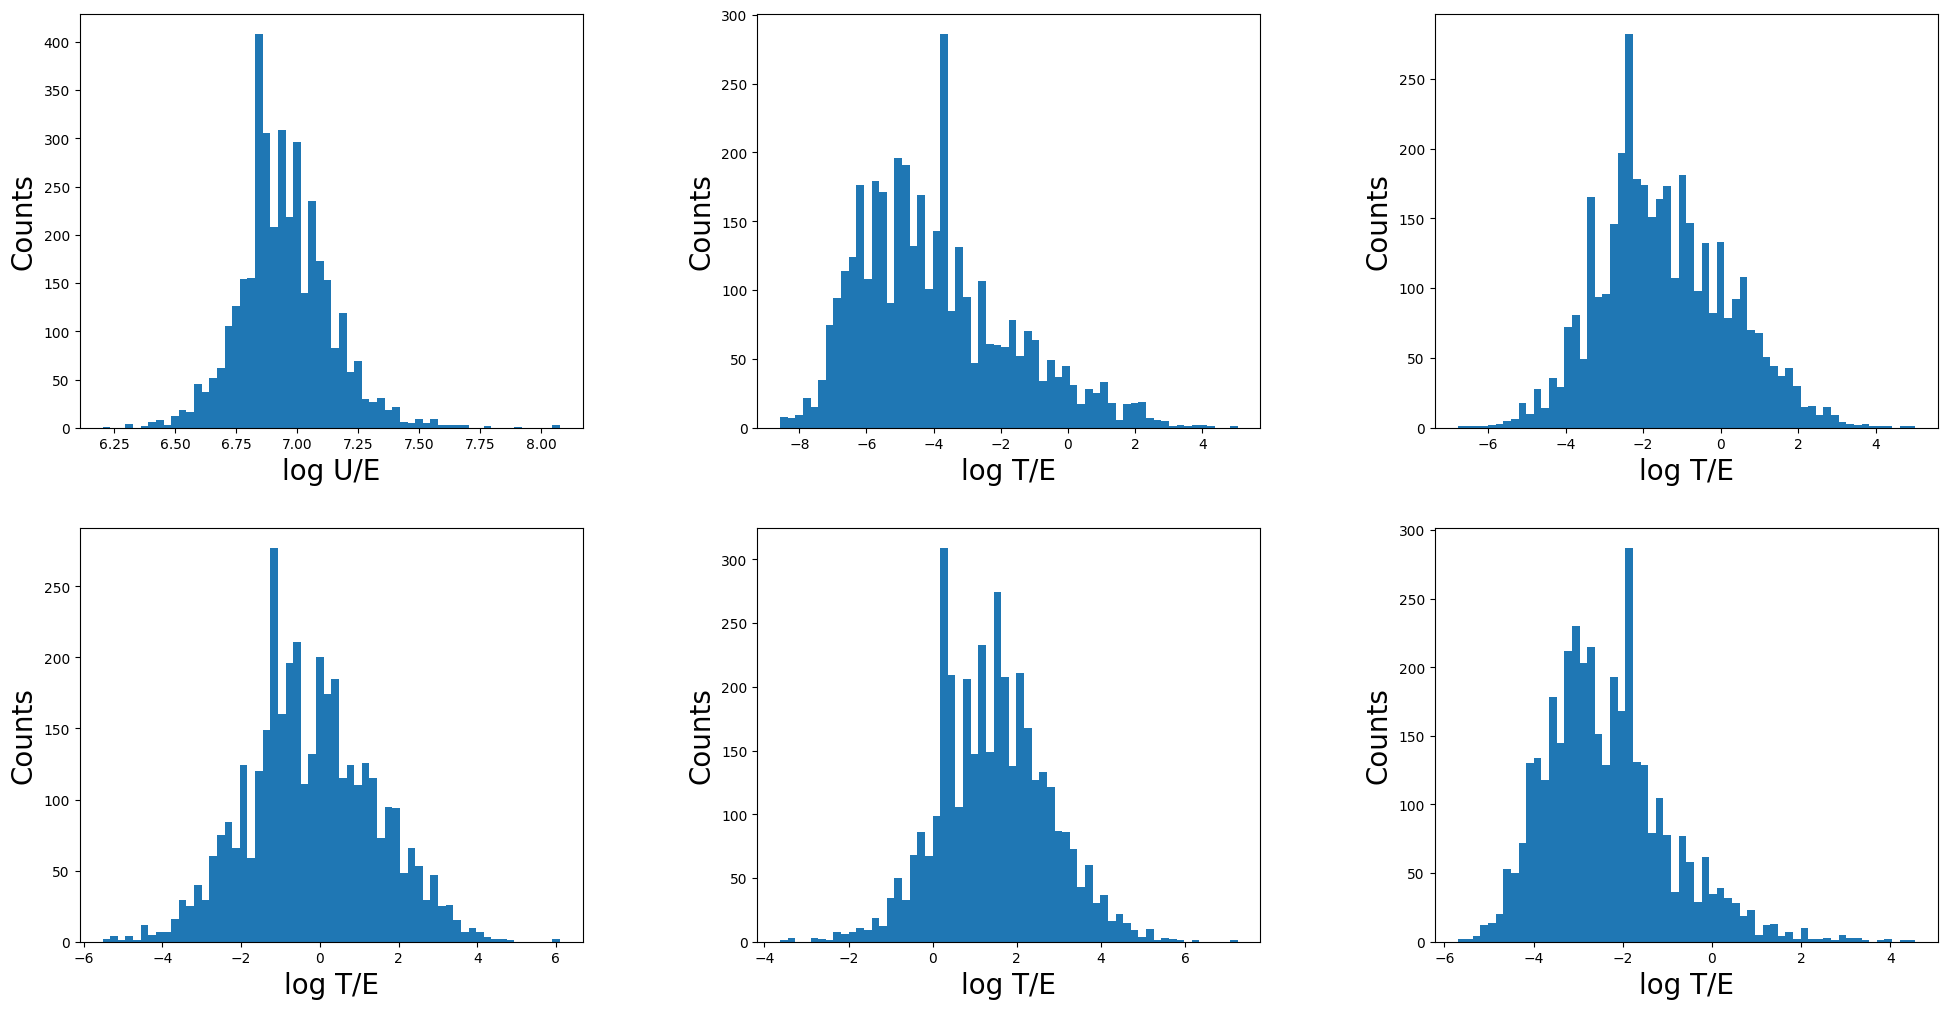

In [26]:
# Plot distribution of all mutations
fig, axs = plt.subplots(2, 3)
for i in range(len(all_scores_by_treatment)):
    axs[i // 3, i % 3].hist(list(all_scores_by_treatment[i].values()), bins=60)
    if i == 0:
        axs[i // 3, i % 3].set_xlabel("log U/E", size=20)
    else:
        axs[i // 3, i % 3].set_xlabel("log T/E", size=20)
    axs[i // 3, i % 3].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

Panel 0 mean: 6.933209367641484
Panel 1 mean: -4.246086527319972
Panel 2 mean: -2.31262719334648
Panel 3 mean: -1.1616796742377673
Panel 4 mean: 0.2324786073296413
Panel 5 mean: -1.8597366708783565


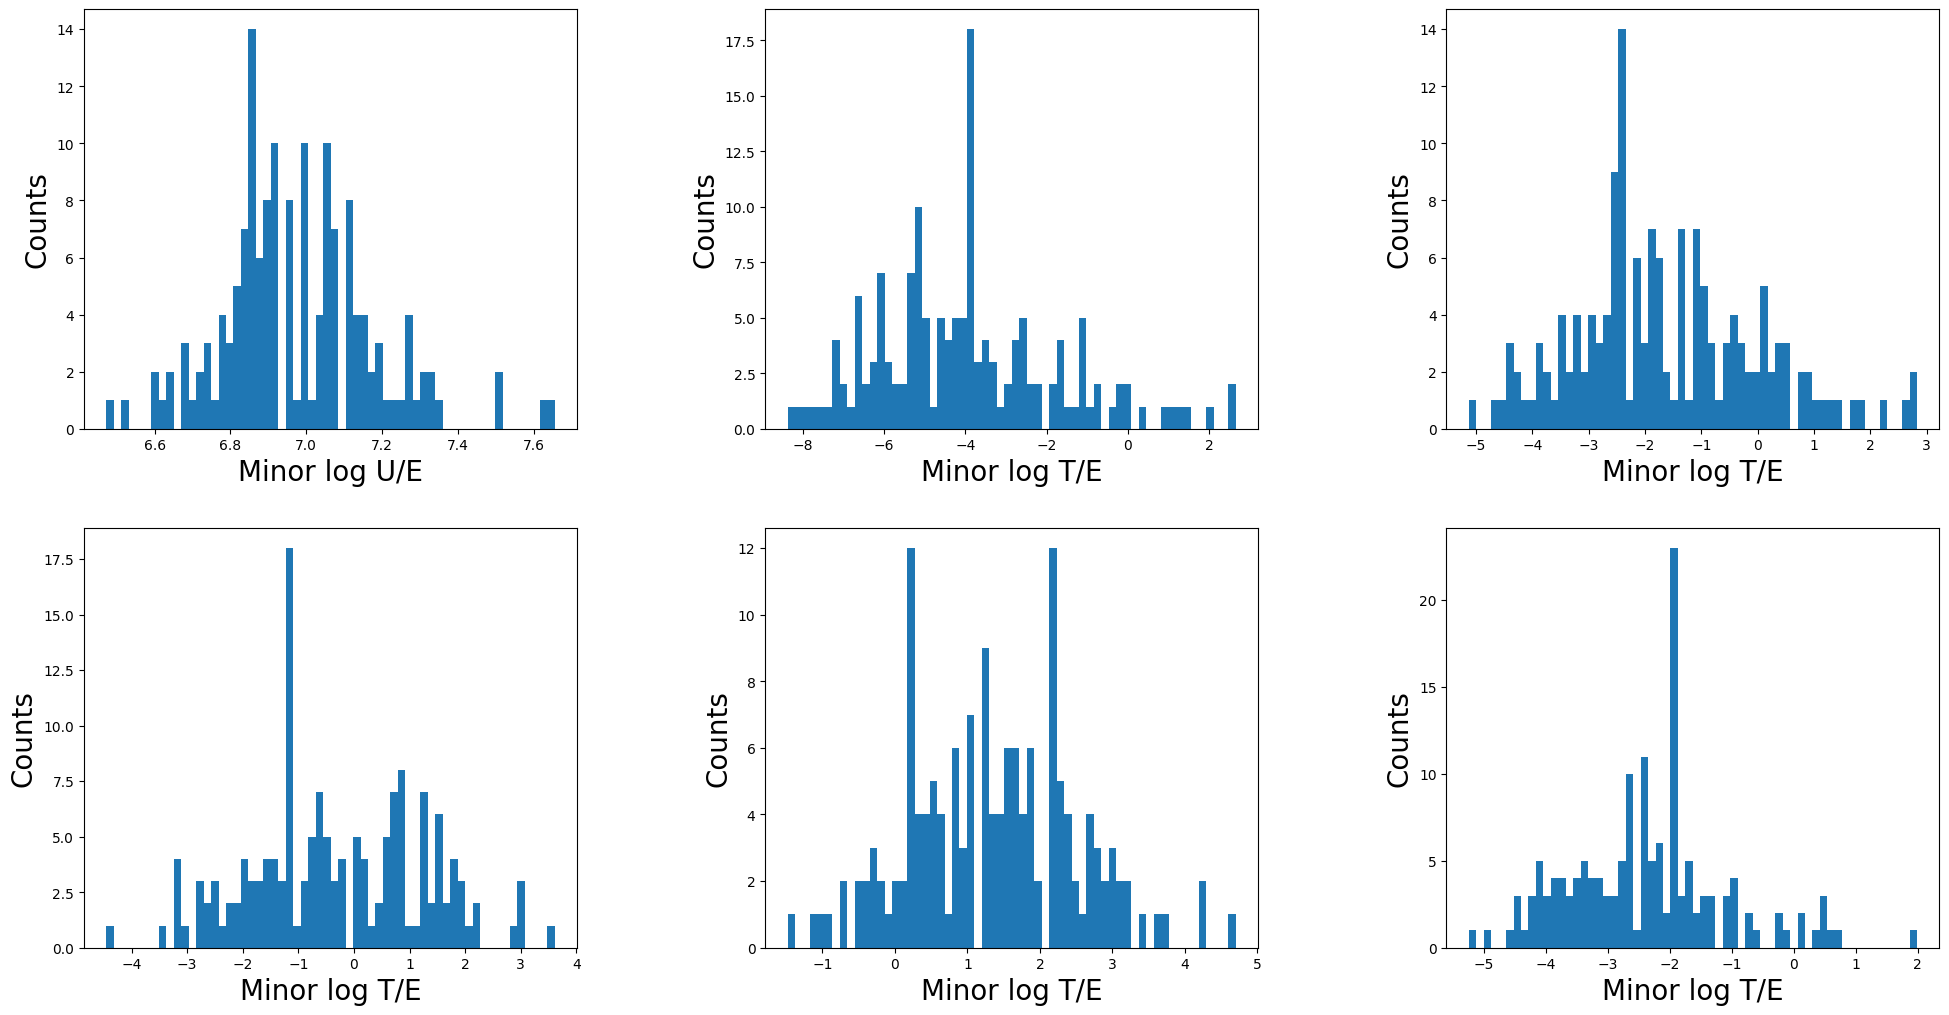

In [27]:
# Plot distribution of minor mutations
minor_aa = ('L', 'I', 'V')
egfr_seq = "MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFEDHFLSLQRMFNNCEVVLGNLEITYVQRNYDLSFLKTIQEVAGYVLIALNTVERIPLENLQIIRGNMYYENSYALAVLSNYDANKTGLKELPMRNLQEILHGAVRFSNNPALCNVESIQWRDIVSSDFLSNMSMDFQNHLGSCQKCDPSCPNGSCWGAGEENCQKLTKIICAQQCSGRCRGKSPSDCCHNQCAAGCTGPRESDCLVCRKFRDEATCKDTCPPLMLYNPTTYQMDVNPEGKYSFGATCVKKCPRNYVVTDHGSCVRACGADSYEMEEDGVRKCKKCEGPCRKVCNGIGIGEFKDSLSINATNIKHFKNCTSISGDLHILPVAFRGDSFTHTPPLDPQELDILKTVKEITGFLLIQAWPENRTDLHAFENLEIIRGRTKQHGQFSLAVVSLNITSLGLRSLKEISDGDVIISGNKNLCYANTINWKKLFGTSGQKTKIISNRGENSCKATGQVCHALCSPEGCWGPEPRDCVSCRNVSRGRECVDKCNLLEGEPREFVENSECIQCHPECLPQAMNITCTGRGPDNCIQCAHYIDGPHCVKTCPAGVMGENNTLVWKYADAGHVCHLCHPNCTYGCTGPGLEGCPTNGPKIPSIATGMVGALLLLLVVALGIGLFMRRRHIVRKRTLRRLLQERELVEPLTPSGEAPNQALLRILKETEFKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDNPHVCRLLGICLTSTVQLITQLMPFGCLLDYVREHKDNIGSQYLLNWCVQIAKGMNYLEDRRLVHRDLAARNVLVKTPQHVKITDFGLAKLLGAEEKEYHAEGGKVPIKWMALESILHRIYTHQSDVWSYGVTVWELMTFGSKPYDGIPASEISSILEKGERLPQPPICTIDVYMIMVKCWMIDADSRPKFRELIIEFSKMARDPQRYLVIQGDERMHLPSPTDSNFYRALMDEEDMDDVVDADEYLIPQQGFFSSPSTSRTPLLSSLSATSNNSTVACIDRNGLQSCPIKEDSFLQRYSSDPTGALTEDSIDDTFLPVPEYINQSVPKRPAGSVQNPVYHNQPLNPAPSRDPHYQDPHSTAVGNPEYLNTVQPTCVNSTFDSPAHWAQKGSHQISLDNPDYQQDFFPKEAKPNGIFKGSTAENAEYLRVAPQSSEFIGA"
minor_ranges = ((6.6, 7.2), (-8, 0), (-4.5, -0.5), (-2, -0.5), (-1, 1), (-2, -1.5))

minor_mutation_means = []
fig, axs = plt.subplots(2, 3)
for i in range(len(all_scores_by_treatment)):
    minor_mutation_scores = [all_scores_by_treatment[i][key] for key in all_scores_by_treatment[i] if egfr_seq[key[0] - 1] in minor_aa and key[1] in minor_aa]
    axs[i // 3, i % 3].hist(list(minor_mutation_scores), bins=60)
    if i == 0:
        axs[i // 3, i % 3].set_xlabel("Minor log U/E", size=20)
    else:
        axs[i // 3, i % 3].set_xlabel("Minor log T/E", size=20)
    axs[i // 3, i % 3].set_ylabel("Counts", size=20)

    minor_mutation_means.append(np.mean([score for score in minor_mutation_scores if minor_ranges[i][0] < score < minor_ranges[i][1]]))
    print(f"Panel {i} mean: {minor_mutation_means[-1]}")

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

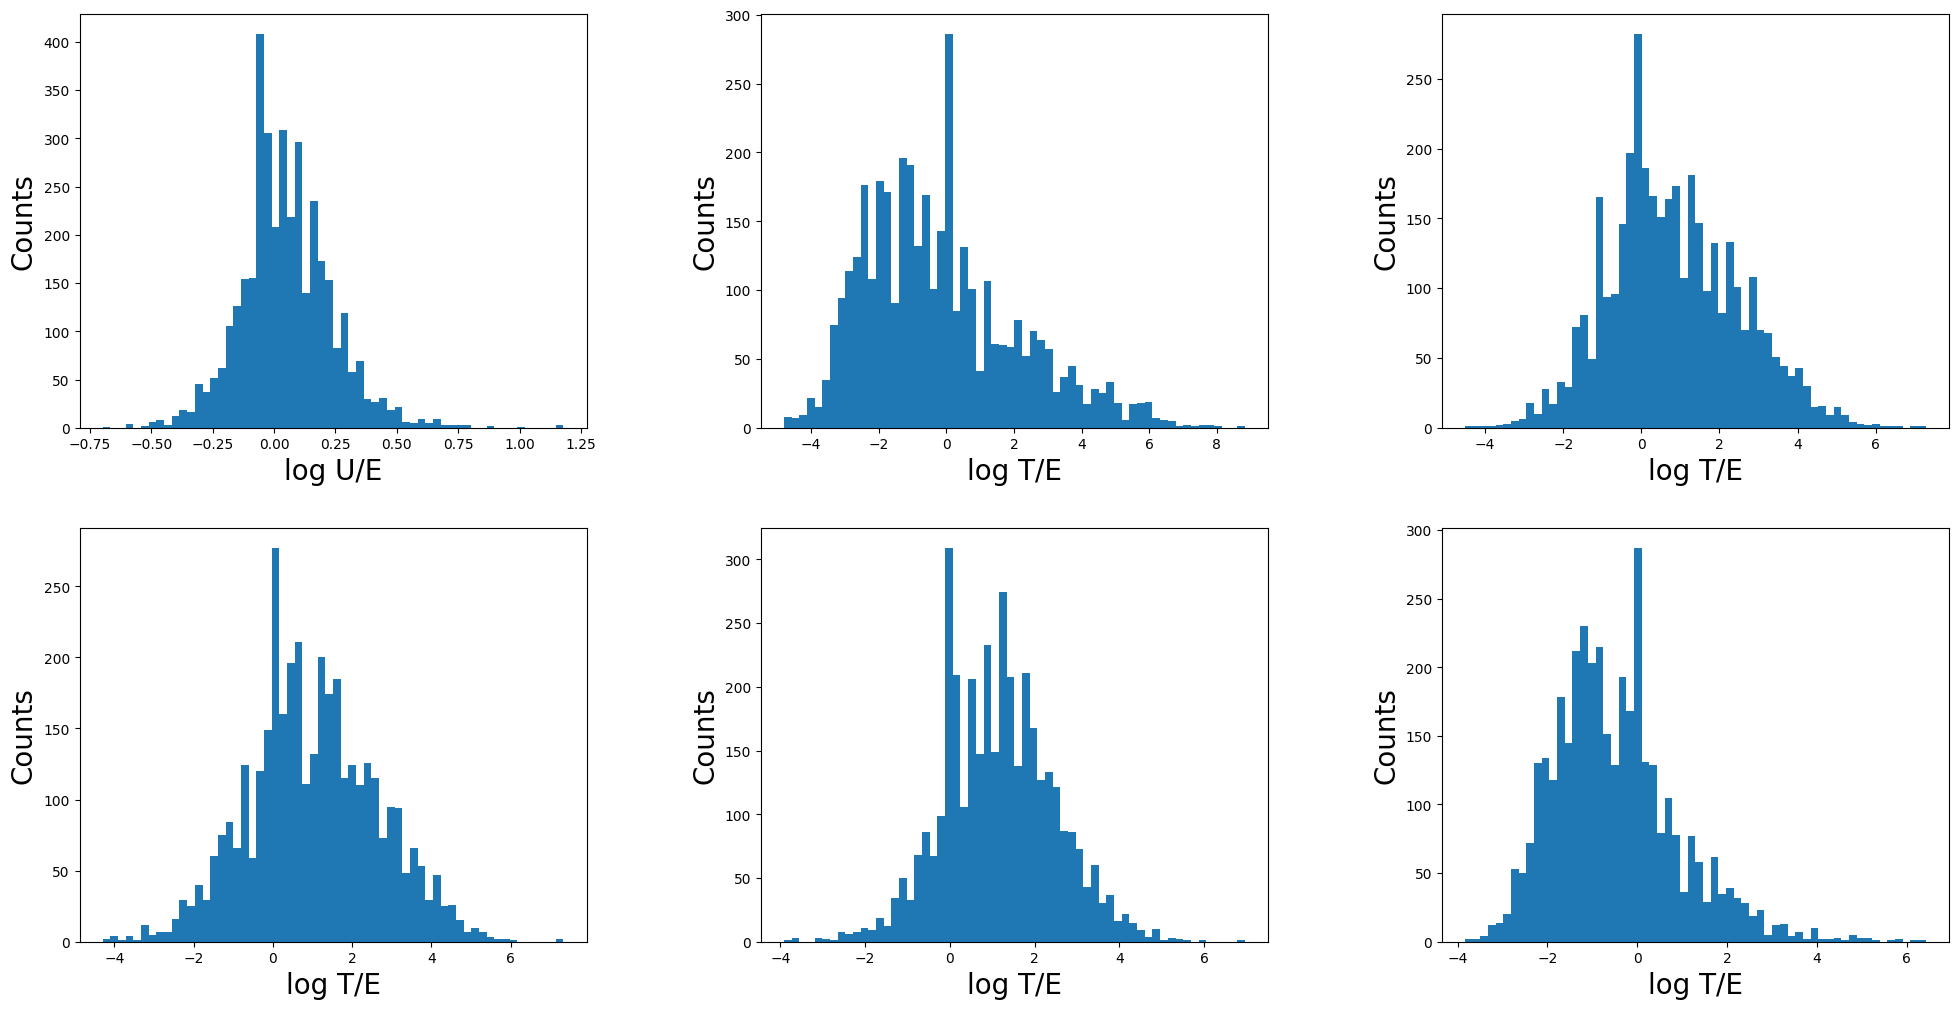

In [28]:
# Normalize scores by WT
minor_mutation_means = (6.90, -3.77, -2.27, -1.23, 0.29, -1.87)
for i in range(len(all_scores_by_treatment)):
    for key in all_scores_by_treatment[i]:
        all_scores_by_treatment[i][key] = all_scores_by_treatment[i][key] - minor_mutation_means[i]

# Plot distribution of shifted mutations
fig, axs = plt.subplots(2, 3)
for i in range(len(all_scores_by_treatment)):
    axs[i // 3, i % 3].hist(list(all_scores_by_treatment[i].values()), bins=60)
    if i == 0:
        axs[i // 3, i % 3].set_xlabel("log U/E", size=20)
    else:
        axs[i // 3, i % 3].set_xlabel("log T/E", size=20)
    axs[i // 3, i % 3].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

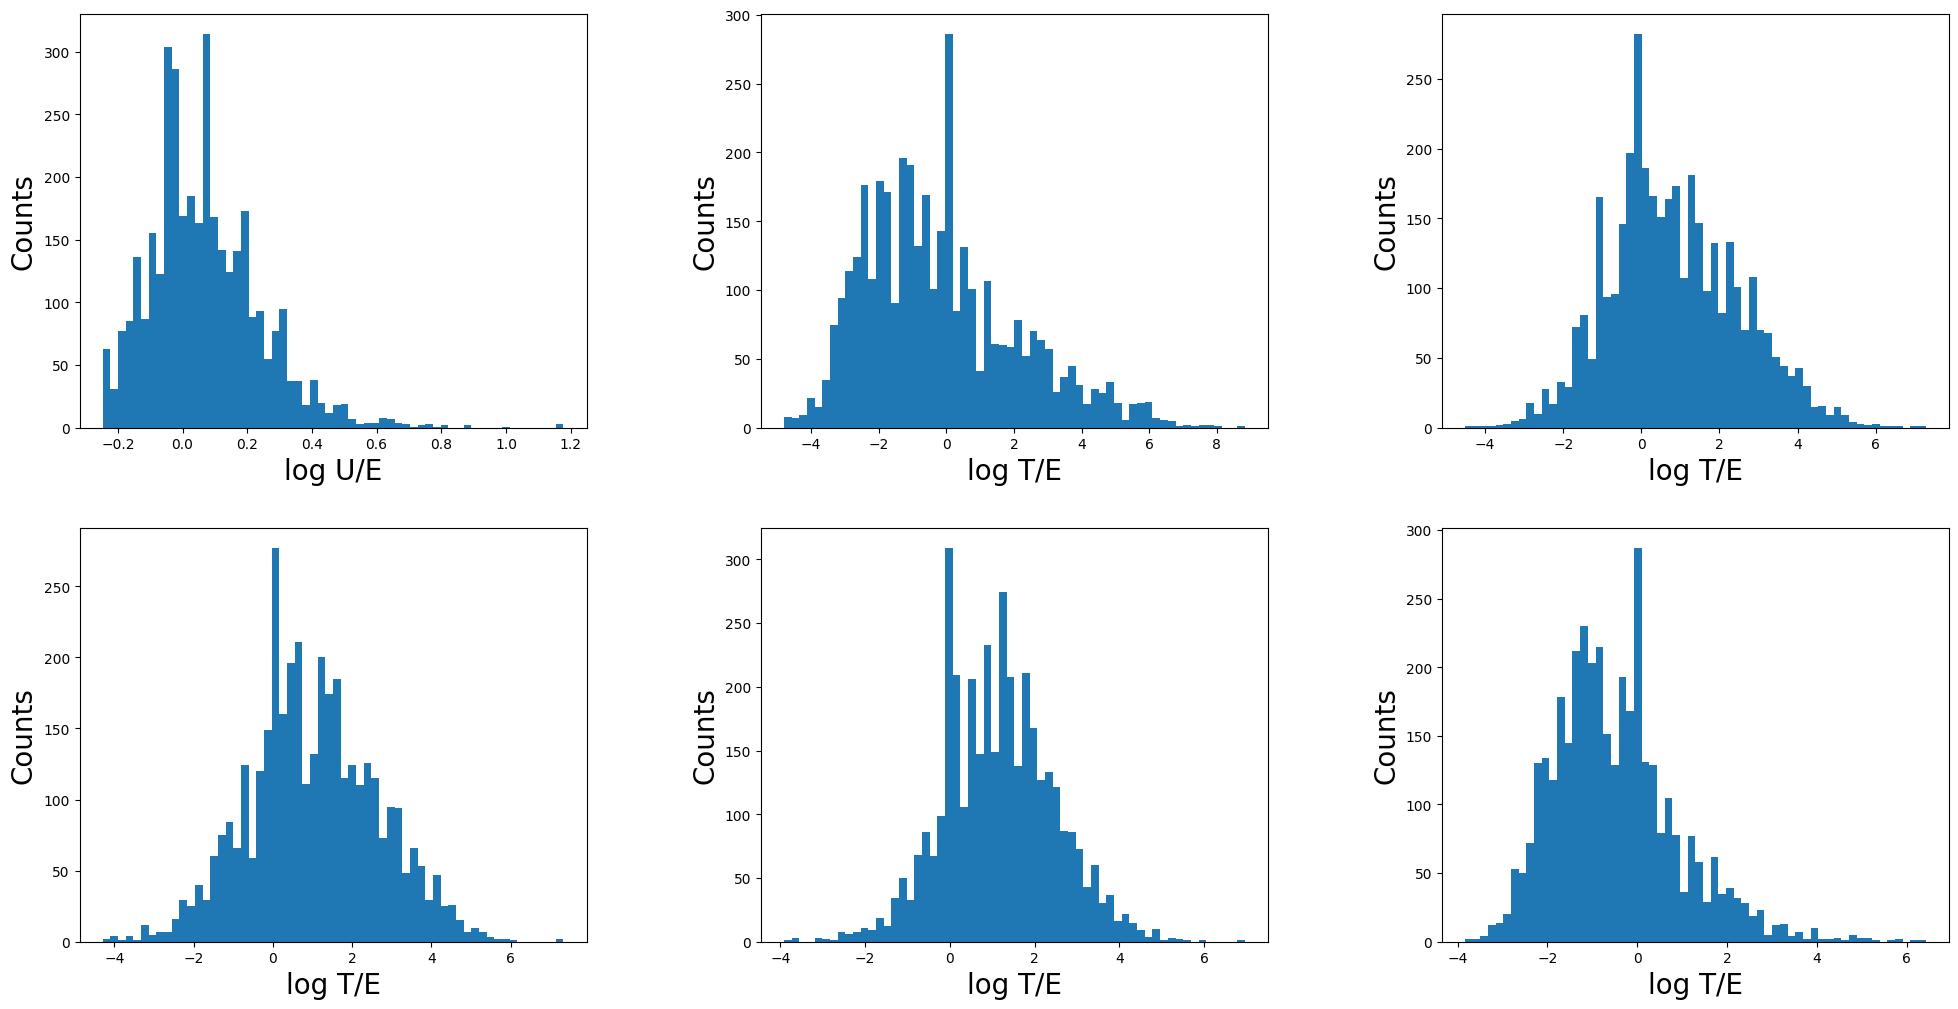

In [29]:
# Stop codons are already excluded
# Remove the second small LoF mode in the untreated scores below -0.25
all_scores_by_treatment[0] = {key: all_scores_by_treatment[0][key] for key in all_scores_by_treatment[0]
                              if all_scores_by_treatment[0][key] >= -0.25}

# Re-plot distributions
fig, axs = plt.subplots(2, 3)
for i in range(len(all_scores_by_treatment)):
    axs[i // 3, i % 3].hist(list(all_scores_by_treatment[i].values()), bins=60)
    if i == 0:
        axs[i // 3, i % 3].set_xlabel("log U/E", size=20)
    else:
        axs[i // 3, i % 3].set_xlabel("log T/E", size=20)
    axs[i // 3, i % 3].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

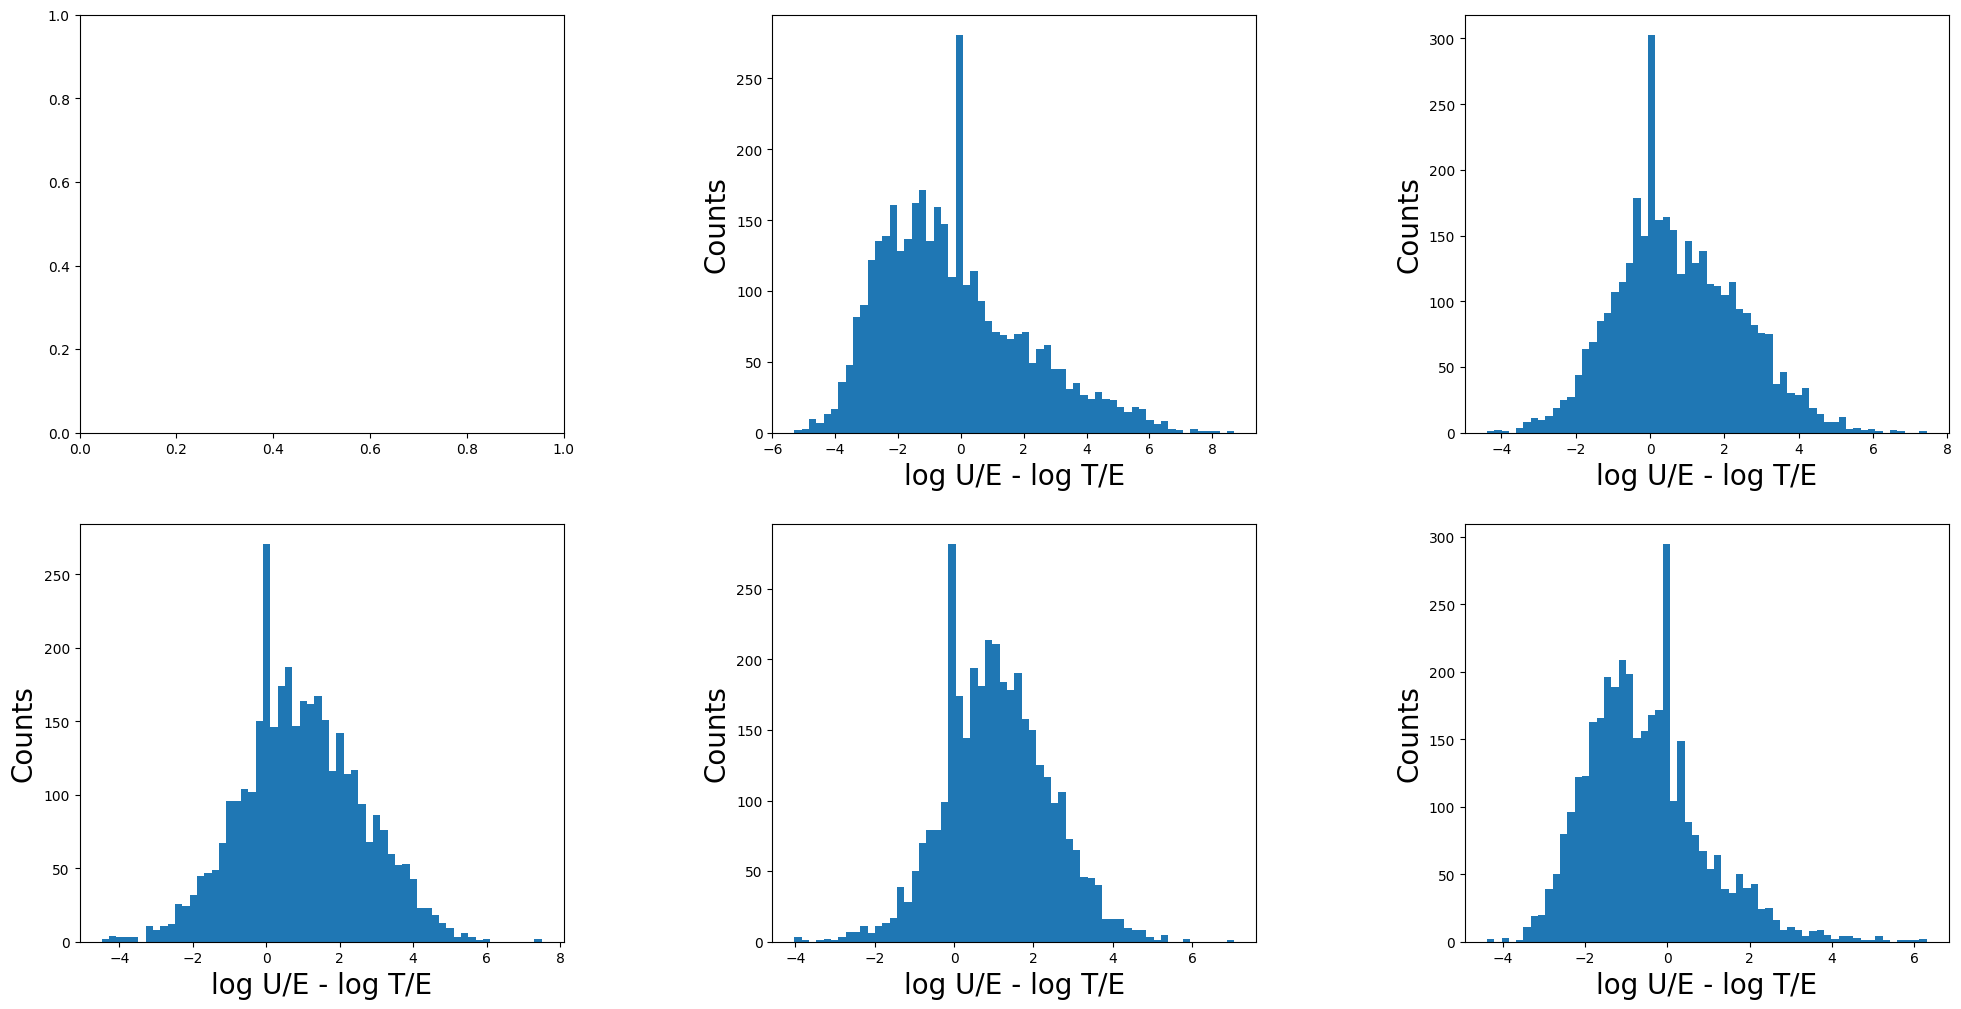

In [30]:
# Calculate score differences
all_score_differences = []
for i in range(1, len(all_scores_by_treatment)):
    treat_score_differences = {}
    for key in all_scores_by_treatment[i]:
        if key in all_scores_by_treatment[0]:
            treat_score_differences[key] = all_scores_by_treatment[i][key] - all_scores_by_treatment[0][key]
    all_score_differences.append(treat_score_differences)

# Plot distribution of score differences
fig, axs = plt.subplots(2, 3)
for i in range(1, len(all_scores_by_treatment)):
    axs[i // 3, i % 3].hist(list(all_score_differences[i - 1].values()), bins=60)
    axs[i // 3, i % 3].set_xlabel("log U/E - log T/E", size=20)
    axs[i // 3, i % 3].set_ylabel("Counts", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

In [31]:
# Save difference scores to output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
treatments = ["Afa_50nM", "Erl_600nM", "Gef_600nM", "Ico_600nM", "Osi_200nM"]
for treat_i in range(len(all_score_differences)):
    for pos, mut in all_score_differences[treat_i]:
        prot_col.append("EGFR")
        ligand_col.append(treatments[treat_i])
        wt_col.append(egfr_seq[pos - 1])
        pos_col.append(str(pos))
        mut_col.append(mut)
        score_col.append(all_score_differences[treat_i][(pos, mut)])

write_formatted_data("EGFR_An_2022.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"))

In [67]:
# Save the tails of the difference scores to an additional output file
prot_col = []
ligand_col = []
wt_col = []
pos_col = []
mut_col = []
score_col = []

# Record all score columns
treatments = ["Afa_50nM", "Erl_600nM", "Gef_600nM", "Ico_600nM", "Osi_200nM"]
for treat_i in range(len(all_score_differences)):
    diff_mean = np.mean(list(all_score_differences[treat_i].values()))
    diff_std = np.std(list(all_score_differences[treat_i].values()))
    print(f"Treatment {treat_i} mean, std: {diff_mean}, {diff_std}")
    
    for pos, mut in all_score_differences[treat_i]:
        if np.abs(all_score_differences[treat_i][(pos, mut)] - diff_mean) > diff_std:
            prot_col.append("EGFR")
            ligand_col.append(treatments[treat_i])
            wt_col.append(egfr_seq[pos - 1])
            pos_col.append(str(pos))
            mut_col.append(mut)
            score_col.append(all_score_differences[treat_i][(pos, mut)])

write_formatted_data("EGFR_An_2022_tail.csv", 
                     clean_data(prot_col, ligand_col, wt_col, pos_col, mut_col, score_col), 
                     ("Protein", "Ligand", "WT", "Pos", "Mut", "Score"),
                     directory=difference_tail_dir)

Treatment 0 mean, std: -0.25185604840063885, 2.2799785147447174
Treatment 1 mean, std: 0.7590288481732133, 1.6724857740666816
Treatment 2 mean, std: 0.9605440716943848, 1.6439031119400753
Treatment 3 mean, std: 1.086338059413151, 1.3248281395146464
Treatment 4 mean, std: -0.5453565129779735, 1.4087639182033929
